# Calibrated Character Ledger with a Gate (CCL-Gate): Knowing, Using and Abstaining on Referent Gender in Machine Translation

**Final notebook (CCL v3 / CCL-Gate), 21 October 2026.** One notebook implements the method, the baselines, the evaluation and every table and figure. Run it top to bottom; it writes everything to `Results/`.

**Research question.** When a source language leaves a referent's gender unexpressed (Turkish *o*, Persian *او*, Indonesian *dia*, dropped subjects) and the evidence lies elsewhere — earlier in the passage, in a previous passage, or nowhere — can a translation system **know** the gender when evidence exists, **use** it in the output, and **abstain** (gender-neutral wording) when the gender is not established?

**Method in one paragraph.** An LLM builds a *character ledger*: persons, verbatim-verified typed gender cues and a name prior. Ledger hygiene removes pronoun pseudo-entities, typologically impossible cues and name-only cues; extraction of the current passage is conditioned on the ledger of earlier text, so pronoun-only evidence can be bound to a person named later. A log-prob resolver links every third-person slot to a ledger entry, and an intercept-free evidence model turns cues into a calibrated probability that the referent is female. **CCL-Gate** then intervenes only where the ledger is reliable: it neutralises a slot when no candidate carries gender evidence or the resolver finds the reference ambiguous between candidates of opposite gender, enforces a gender when the posterior is confident, and otherwise leaves the translator's own choice. The gate's instructions are added to the *plain* translation prompt (which also sees the earlier text), so a slot the gate does not touch is translated exactly as by the plain baseline.

**Main results** (Qwen3-8B Q4_K_M, local llama.cpp, X→EN, held-out test instances; Section 12.1c, `Results/pilot/tables/T1_*`, `T2e_*`):

| System | ACC on determinable ↑ | Wrong gender on determinable ↓ | Gendered output when gender is unknowable (UCR) ↓ | BAL ↑ |
|---|---|---|---|---|
| llm_plain | 0.552 | 0.242 | 0.828 | 0.362 |
| llm_cautious (prompt-only abstention) | 0.543 | 0.293 | 0.856 | 0.344 |
| llm_cot_gender | 0.551 | 0.237 | 0.864 | 0.344 |
| infer_then_tag | 0.601 | 0.305 | 0.918 | 0.342 |
| CCL (full ledger conditioning) | 0.350 | 0.084 | 0.165 | 0.593 |
| **CCL-Gate (proposed)** | **0.469** | **0.156** | **0.257** | **0.606** |
| oracle (gold gender given) | 0.893 | 0.017 | 0.812 | 0.540 |

CCL-Gate improves per-instance correctness over every prompt baseline (+3.5 to +6.8 points over all analysed conditions; +5.1 to +8.4 in the adjacent condition; +71 to +82 points on unrecoverable items), ties them in the memory condition, and loses when the evidence is 8 filler sentences away (−16 to −28 points). It halves misgendering of determinable referents but produces more neutral renderings, so exact-gender accuracy on determinable items is lower than the prompt baselines'. These are the numbers this notebook reproduces; read Section 16 for limitations.

**Reproduce.** All 56,866 model calls of the reported run are cached in `_runtime/ccl_work/cache/llm_cache_pilot.sqlite`, so this notebook re-creates every number in a few minutes without the GPU (`_runtime/scripts/run_final_notebook.ps1`). To regenerate the calls from scratch, start the model server (Section 1.1) and move the cache file away (more than a day of GPU time on an RTX 4070 Laptop).

**Development history.** The v2 notebook (`original_v2/CCL_experiments_v2.ipynb`), the development notebooks (`_runtime/dev/`), their executed runs (`_runtime/runs/`), the caches and `_runtime/dev/EXPERIMENT_LOG.md` document every step from v2 to this version, including failed variants.


## 0. Notebook map

1. Configuration (final defaults: `pilot` run mode, `pilot_v3` system profile, all v3 components on) and environment
2. Data acquisition and validity checks (MiTTenS, Translate-with-Care, MT-GenEval, FLORES-200 filler, SSA name table, Urdu kit)
3. Benchmark construction: adjacent / distant (8, 32 filler sentences) / memory / isolated conditions, late binding, counterfactuals, validity filters
4. Model backend (OpenAI-compatible llama.cpp server) with a persistent SQLite cache, JSON-schema constraints and a throughput probe
5. Prompts (v2 prompts kept for the ablations; v3/v3b prompts used by the final method)
6. Proposed method: CCL v3 ledger and **CCL-Gate** (6.2)
7. Baselines and controls
8. Experiment runner
9. Calibration on dev only (evidence temperature, τ, τ_gate); 9b decision-layer lab on real states
10–11. Scoring, metrics and statistics (cluster bootstrap, exact McNemar, Holm)
12. Analyses: main results, decisive comparisons, **held-out check and headline table (12.1c)**, error decomposition, languages, distance, gender asymmetry, knowing vs using, ablations, EN→X, calibration and risk–coverage, cost, evidence type
13. Error analysis and human-evaluation export
14. Figures
15. Reproducibility manifest
16. Final configuration, interpretation, limitations, reproduction
17. Export to `Results/`


## 1. Configuration and environment
Edit `CONFIG` here; everything downstream reads from it. Environment variables override the common settings.

**Run modes**

| Mode | Purpose | Items per (dataset, subset, language, split) |
|---|---|---|
| `dry_run` | Plumbing test with a mock model (outputs stamped synthetic) | 3 |
| `smoke` | Quick real-model check, 4 X→EN + 2 EN→X languages | 4 |
| **`pilot`** (default) | **The reported evaluation**: 15 X→EN source languages, EN→X into hi/de/ar, 4,585 instances (2,684 test / 1,901 dev) | 20 |
| `full` | Larger run (cap `CCL_FULL_LIMIT`, default 150); not run for this report | 150 |

**System profiles** (`CCL_SYSTEMS`): `pilot_v3` (default; 13 systems, the reported set), `smoke`, `core`, `all`.

**v3 switches** (`CCL_V3`, comma list; default = all on): `hygiene` (typology and name-only cue filters), `prior` (given-name SSA prior, clipped to [0.05, 0.95]), `pseudo` (pronoun/narrator pseudo-entities removed), `slots` (name mentions are not pronoun slots), `tauguard` (no degenerate abstain-everything τ), `prompts` (pronoun-aware, ledger-conditioned extraction; third-person resolver), `prompts2` (discourse-continuity resolver, apposition rule, singular-*they* deferral), `monotone` (a repair is kept only if it removes the problem), `gate` (CCL-Gate). `CCL_V3=none` reproduces v2 exactly.

**Analysis scope.** `analysis_exclude_conditions = ["distant_32"]`: the 768-token output budget truncates 34-line translations for every system (≈97 % parse failures, table `T0_excluded_conditions`), so the condition is run but not analysed.


In [1]:
import os, sys, json, re, math, time, random, hashlib, subprocess, sqlite3, itertools, collections, logging, platform, datetime, difflib, unicodedata, shutil, warnings, string
from pathlib import Path
from dataclasses import dataclass, field, asdict, replace

RUN_MODE = os.environ.get("CCL_RUN_MODE", "pilot").strip()      # "dry_run" | "smoke" | "pilot" | "full"
assert RUN_MODE in {"dry_run", "smoke", "pilot", "full"}, RUN_MODE
_full_cap = int(os.environ.get("CCL_FULL_LIMIT", "150"))

CONFIG = dict(
    run_mode=RUN_MODE,
    seed=20261006,
    work_dir=os.environ.get("CCL_WORK_DIR", "ccl_work"),
    datasets=dict(mittens=True, twc=True, mtgeneval=True, bwb=True, urdu=True, flores_filler=True, late_binding=True),
    # Pinned dataset commits (verified 2026-10-14: each pin is the current HEAD of its repository).
    repos=dict(
        mittens=("https://github.com/google-research-datasets/mittens", "1635a8076672d022695213942bda98ce046892a4"),
        twc=("https://github.com/pardissz/Translate-With-Care", "84e280cd5ce5e45a4d158d8a7177103294c20c3e"),
        mtgeneval=("https://github.com/amazon-science/machine-translation-gender-eval", "c77132ccd248d0b09ac185aebebc94f1051dbc9e"),
        # US SSA baby-name shares 1880-2008 (public US government data) -> deterministic, auditable name prior table
        names=("https://github.com/hadley/data-baby-names", "b6525579cf7d2816e77fa885299445d15a09c906"),
    ),
    bwb_dir=os.environ.get("CCL_BWB_DIR", ""),
    bwb_gdrive_folder="https://drive.google.com/drive/folders/12K1-DWmpEdqkaR_61aogdywsALDg4z1L",
    bwb_chunk_lines=12,
    bwb_prev_raw_lines=60,
    urdu_csv=os.environ.get("CCL_URDU_CSV", ""),
    flores=dict(hf_name="openlanguagedata/flores_plus", split="devtest",
                tarball_url="https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz"),
    # Core languages: genderless 3rd-person pronouns, reasonable 4-9B model support. Extended: MiTTenS low-resource
    # languages (about 18 items each; small models are weak there, so report them separately).
    x2en_core=["tr", "fa", "id", "fi", "et", "az", "bn", "ur", "es"],
    x2en_extended=["as", "bho", "mai", "ln", "lg", "om"],
    en2x_langs=["hi", "ar", "de", "es", "fr", "it", "pt", "ru"],
    filler_distances=[8, 32],
    limits=dict(dry_run=3, smoke=4, pilot=int(os.environ.get("CCL_PILOT_LIMIT", "20")), full=(_full_cap or None)),
    # Isolation validity: languages whose TARGET sentence itself marks the referent's gender (so 'isolated' is
    # determinable, not unrecoverable) and languages where this is not yet verified by a speaker.
    target_marks_gender_langs=["om"],
    isolation_unverified_langs=["bho", "mai"],
    exclude_unverified_isolation=True,
    llm=dict(
        backend=os.environ.get("CCL_LLM_BACKEND", "openai"),        # openai (llama.cpp / Ollama / vLLM server) | vllm | hf | mock
        translator=os.environ.get("CCL_TRANSLATOR", "qwen3-8b"),     # the model name your server expects
        extractor=os.environ.get("CCL_EXTRACTOR") or None,
        verifier=os.environ.get("CCL_VERIFIER") or None,
        openai_base_url=os.environ.get("CCL_OPENAI_BASE_URL", "http://localhost:8080/v1"),
        openai_api_key_env="CCL_OPENAI_API_KEY",
        server_kind=os.environ.get("CCL_SERVER_KIND", "llamacpp"),   # llamacpp | ollama | vllm | generic (controls extras)
        json_schema=True,          # constrained JSON for extract/resolve/verify/probe (llama.cpp, vLLM; ignored by Ollama's /v1)
        disable_thinking=True,     # Qwen3 / hybrid-reasoning models: non-thinking mode
        # Log-prob resolver (v2 default where supported): one greedy call instead of S samples. Auto-falls back to sampling
        # if the server returns no log-probs. Off for Ollama's /v1 (no log-probs). CCL_LOGPROBS=0 forces sampling.
        logprobs=os.environ.get("CCL_LOGPROBS", "1" if os.environ.get("CCL_SERVER_KIND", "llamacpp") in {"llamacpp", "vllm"} else "0") == "1",
        max_new_tokens=768, max_model_len=4096, gpu_memory_utilization=0.90, tensor_parallel_size=1,
        concurrency=int(os.environ.get("CCL_CONCURRENCY", "4")), request_timeout=300,
    ),
    # Laptop model grid (8 GB VRAM). Run the notebook once per model; restart the kernel in between.
    model_grid=["qwen3-8b (Q4_K_M)", "gemma-4-e4b (Q4_K_M)", "llama-3.1-8b-instruct (Q4_K_M)",
                "qwen3-4b (Q4_K_M)", "qwen3-1.7b (Q8_0)",
                "qwen3-30b-a3b or gemma-4-26b-a4b (Q4_K_M, MoE experts on CPU)"],
    nllb_model=os.environ.get("CCL_NLLB", "facebook/nllb-200-distilled-600M"),   # 1.3B also fits in 8 GB (fp16 ~2.7 GB)
    name_prior_source=os.environ.get("CCL_NAME_PRIOR", "table_then_llm"),       # llm | table | table_then_llm
    method=dict(posterior_samples=5, resolve_temperature=0.7, translate_temperature=0.0,
                max_repair_rounds=1, tau_grid=[0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95],
                default_tau=0.7, noisy_ledger_rates=[0.1, 0.3],
                fit_method="temp",             # v2 default (Section 9b): default weights x one fitted temperature
                tau_rule="balanced",           # balanced | risk@0.05 | risk@0.10 | fixed@0.8
                saturate_counts=False, unknown_mode="half"),
    systems=["nllb_sent", "llm_plain", "llm_cautious", "llm_cot_gender", "infer_then_tag",
             "llm_summary_mem", "llm_names_mem", "llm_selfrefine", "llm_neutral_always", "probe", "oracle_goe",
             "ccl", "ccl_posthoc", "ccl_plain_list", "ccl_no_defer", "ccl_no_repair", "ccl_retranslate",
             "ccl_no_name_prior", "ccl_argmax", "ccl_verbalized", "ccl_noisy_0.1", "ccl_noisy_0.3"],
    run_bwb_systems=["llm_plain", "llm_cautious", "llm_summary_mem", "llm_names_mem", "ccl", "ccl_no_repair"],
    # v3 switches (Section 6.2). CCL_V3=none reproduces v2; a comma list enables a subset for ablations.
    v3=dict(enabled=sorted(set(os.environ.get("CCL_V3", "hygiene,prior,pseudo,slots,tauguard,prompts,prompts2,monotone,gate").split(",")) - {"none", ""}),
            name_prior_clip=float(os.environ.get("CCL_V3_PRIOR_CLIP", "0.05"))),
    # Conditions dropped from ANALYSIS (instances are still built and run, so the cache and the dev calibration are unchanged).
    # distant_32: the 768-token output budget truncates 34-line translations for every system (parse failure ~97 %).
    analysis_exclude_conditions=[c for c in os.environ.get("CCL_ANALYSIS_EXCLUDE", "distant_32").split(",") if c],
    bootstrap_iters=10000 if RUN_MODE in {"pilot", "full"} else 300,
    human_eval_per_cell=25,
)
# System profiles keep laptop runs tractable (Section G of the report: ~23 LLM calls per test instance with 'all').
SYSTEM_PROFILES = dict(
    smoke=["llm_plain", "llm_cautious", "probe", "oracle_goe", "ccl", "ccl_posthoc"] + (["ccl_gate", "ccl_gate_posthoc"] if "gate" in set(os.environ.get("CCL_V3", "hygiene,prior,pseudo,slots,tauguard,prompts,prompts2,monotone,gate").split(",")) else []),
    core=["nllb_sent", "llm_plain", "llm_cautious", "llm_cot_gender", "infer_then_tag", "llm_summary_mem", "llm_names_mem",
          "probe", "oracle_goe", "ccl", "ccl_posthoc", "ccl_no_defer", "ccl_no_repair", "ccl_argmax"] + (["ccl_gate", "ccl_gate_posthoc"] if "gate" in set(os.environ.get("CCL_V3", "hygiene,prior,pseudo,slots,tauguard,prompts,prompts2,monotone,gate").split(",")) else []),
    all=list(CONFIG["systems"]),
    pilot_v3=(["nllb_sent"] if os.environ.get("CCL_NLLB_ON") == "1" else []) + ["llm_plain", "llm_cautious", "llm_cot_gender", "infer_then_tag",
              "llm_summary_mem", "llm_names_mem", "probe", "oracle_goe", "ccl", "ccl_posthoc", "ccl_no_repair", "ccl_gate", "ccl_gate_posthoc"])
SYSTEM_PROFILE = os.environ.get("CCL_SYSTEMS", dict(dry_run="all", smoke="smoke", pilot="pilot_v3", full="pilot_v3")[RUN_MODE])
CONFIG["systems"] = SYSTEM_PROFILES[SYSTEM_PROFILE]
# Also compute the sampled resolver next to the log-prob one (decision-level comparison in Section 9b; no translations)
CONFIG["lab_both_resolvers"] = os.environ.get("CCL_LAB_BOTH_RESOLVERS", "1" if RUN_MODE == "dry_run" else "0") == "1"
if RUN_MODE == "smoke":       # a quick, cheap end-to-end check on a few well-supported languages
    CONFIG["x2en_core"], CONFIG["x2en_extended"], CONFIG["en2x_langs"] = ["tr", "fa", "id", "es"], [], ["hi", "de"]
    CONFIG["filler_distances"] = [8]
if RUN_MODE == "pilot" and os.environ.get("CCL_EN2X", "") != "all":
    CONFIG["en2x_langs"] = ["hi", "de", "ar"]      # three typologically different gendered targets keep the pilot overnight-sized
CONFIG["x2en_langs"] = CONFIG["x2en_core"] + CONFIG["x2en_extended"]
V3 = set(CONFIG["v3"]["enabled"]); CONFIG["v3"]["given_name_prior"] = "prior" in V3
if "prior" not in V3:
    CONFIG["v3"]["name_prior_clip"] = 0.01        # v2 clip
if RUN_MODE == "dry_run":
    CONFIG["llm"]["backend"] = "mock"
    CONFIG["model_grid"] = ["mock-llm"]
    CONFIG["llm"]["translator"] = "mock-llm"
    CONFIG["method"]["posterior_samples"] = 3
    CONFIG["method"]["tau_grid"] = [0.6, 0.7, 0.8, 0.9]

LIMIT = CONFIG["limits"][RUN_MODE]
WORK = Path(CONFIG["work_dir"]).resolve()
DATA = WORK / "data"
MODEL_SLUG = re.sub(r"[^A-Za-z0-9._-]+", "_", CONFIG["llm"]["translator"])
OUT_TAG = os.environ.get("CCL_OUT_TAG", "")            # separates experiment variants; the LLM cache is shared
OUT_ROOT = WORK / "outputs" / (RUN_MODE + OUT_TAG)
OUT = OUT_ROOT / MODEL_SLUG
FIG = WORK / "figures" / (RUN_MODE + OUT_TAG)
TAB = WORK / "tables" / (RUN_MODE + OUT_TAG)
CACHE_DB = WORK / "cache" / f"llm_cache_{RUN_MODE}.sqlite"
for p in [DATA, OUT, FIG, TAB, CACHE_DB.parent]:
    p.mkdir(parents=True, exist_ok=True)

random.seed(CONFIG["seed"])
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("ccl")
STAMP = "DRY RUN: synthetic mock outputs, not results" if RUN_MODE == "dry_run" else ""
MANIFEST = dict(created=datetime.datetime.now(datetime.timezone.utc).isoformat(), run_mode=RUN_MODE, config=CONFIG,
                datasets={}, models={}, notes=[], timings={})
TIMINGS = MANIFEST["timings"]

class stage_timer:
    """Context manager that records wall-clock seconds per pipeline stage in MANIFEST['timings']."""
    def __init__(self, name): self.name = name
    def __enter__(self): self.t0 = time.time(); return self
    def __exit__(self, *a): TIMINGS[self.name] = round(TIMINGS.get(self.name, 0.0) + time.time() - self.t0, 2)

print(f"Run mode: {RUN_MODE} | backend: {CONFIG['llm']['backend']} | translator: {CONFIG['llm']['translator']} | limit: {LIMIT} | systems: {SYSTEM_PROFILE} ({len(CONFIG['systems'])})")
print(f"Outputs: {OUT}")

Run mode: pilot | backend: openai | translator: qwen3-8b | limit: 20 | systems: pilot_v3 (13)
Outputs: <project>\_runtime\ccl_work\outputs\pilot\qwen3-8b


### 1.1 Hardware and model server used for the reported run

* Laptop: NVIDIA RTX 4070 Laptop GPU (8 GB), AMD Ryzen 9 7845HX, 32 GB DDR5, Windows 11; Python 3.12.6 in `_runtime/venv`.
* Model: **Qwen3-8B, Q4_K_M GGUF** (Apache-2.0), thinking mode off, temperature 0 for translation and resolution.
* Server: llama.cpp build b11642 (CUDA 12.4), OpenAI-compatible API, 4 parallel slots:
  `llama-server -m Qwen3-8B-Q4_K_M.gguf --alias qwen3-8b -c 32768 -np 4 -ngl 99 -fa on -ctk q8_0 -ctv q8_0 --port 8080 --jinja`
  (8,192 tokens per slot with an 8-bit KV cache). The first part of the pilot ran with `-c 16384` (4,096 per slot, f16 KV); requests rejected for length were removed from the cache and re-run on the larger server (`_runtime/dev/EXPERIMENT_LOG.md`, incident of 19 Oct).
* Measured: ~90 generated tokens/s aggregate at 4 parallel requests; GPU memory 7.4 / 8.2 GB; mean GPU utilisation 78–86 %, peak temperature 80 °C.

Start the server with `_runtime/scripts/2b_start_server_8k.ps1`. The server is needed only for calls that are not in the cache.


In [2]:
# Dependencies. Set CCL_SKIP_INSTALL=1 if your environment is already prepared (recommended on the laptop:
# `pip install -r requirements_ccl.txt` once, see the report).
REQUIRED = {"pandas": "pandas", "numpy": "numpy", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "openpyxl": "openpyxl", "requests": "requests",
            "sacrebleu": "sacrebleu>=2.4", "statsmodels": "statsmodels"}
GPU_EXTRAS = {"transformers": "transformers>=4.46", "sentencepiece": "sentencepiece", "datasets": "datasets>=2.20"}
VLLM_EXTRA = {"vllm": "vllm"}

def _ensure(pkgs):
    import importlib
    for mod, spec in pkgs.items():
        try:
            importlib.import_module(mod)
        except Exception:
            print("installing", spec)
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=False)

if os.environ.get("CCL_SKIP_INSTALL") != "1":
    _ensure(REQUIRED)
    if CONFIG["llm"]["backend"] in {"vllm", "hf"} or ("nllb_sent" in CONFIG["systems"] and RUN_MODE != "dry_run"):
        _ensure(GPU_EXTRAS)
    if CONFIG["llm"]["backend"] == "vllm":
        _ensure(VLLM_EXTRA)

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib
import matplotlib.pyplot as plt

def _optional(mod):
    try:
        return __import__(mod)
    except Exception:
        print(f"[optional] {mod} not available; dependent metrics are skipped.")
        return None
sacrebleu = _optional("sacrebleu")
statsmodels = _optional("statsmodels")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
try:
    display
except NameError:            # running outside Jupyter
    def display(x): print(x)
np.random.seed(CONFIG["seed"] % (2**32))
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| kernel:", sys.executable)
MANIFEST["python_executable"] = sys.executable

python 3.12.6 | numpy 2.5.4 | pandas 3.0.6 | kernel: <project>\_runtime\venv\Scripts\python.exe


In [3]:
# Small utilities used throughout (unchanged from v1 except TYPOLOGY).
def sha(obj) -> str:
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()

def save_jsonl(rows, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

def limit_df(df, by, n, seed=CONFIG["seed"]):
    """Deterministic per-group subsample (keeps all rows when n is None)."""
    if n is None or df.empty:
        return df
    return (df.sample(frac=1.0, random_state=seed).groupby(by, sort=False).head(n)
              .sort_index().reset_index(drop=True))

def sigmoid(x):
    return 1.0 / (1.0 + math.exp(-max(-50.0, min(50.0, x))))

def logit(p, eps=1e-4):
    p = min(1 - eps, max(eps, p)); return math.log(p / (1 - p))

LANG_NAMES = dict(en="English", tr="Turkish", fa="Persian", id="Indonesian", fi="Finnish", et="Estonian",
                  az="Azerbaijani", bn="Bengali", **{"as": "Assamese"}, bho="Bhojpuri", mai="Maithili", ln="Lingala",
                  lg="Luganda", om="Oromo", ur="Urdu", zh="Chinese", hi="Hindi", ar="Arabic", de="German",
                  es="Spanish", fr="French", it="Italian", pt="Portuguese", ru="Russian", ja="Japanese")
NLLB_CODES = dict(en="eng_Latn", tr="tur_Latn", fa="pes_Arab", id="ind_Latn", fi="fin_Latn", et="est_Latn",
                  az="azj_Latn", bn="ben_Beng", **{"as": "asm_Beng"}, bho="bho_Deva", mai="mai_Deva", ln="lin_Latn",
                  lg="lug_Latn", om="gaz_Latn", ur="urd_Arab", zh="zho_Hans", hi="hin_Deva", ar="arb_Arab",
                  de="deu_Latn", es="spa_Latn", fr="fra_Latn", it="ita_Latn", pt="por_Latn", ru="rus_Cyrl")
FLORES_CODES = dict(NLLB_CODES, zh="cmn_Hans")   # flores_plus uses cmn_Hans; FLORES-200 tarball uses zho_Hans

# Typological grouping used in cross-language analysis (how third-person gender is marked in the SOURCE).
# v2: Oromo moved out of the genderless group (3sg pronouns inni/isheen and verbs mark gender; 18/18 MiTTenS Oromo
# targets reveal gender, measured in Section 2.7). Spanish added for the late-binding (pro-drop) subset.
TYPOLOGY = {**{l: "genderless_pronoun" for l in ["tr", "fa", "id", "fi", "et", "az", "bn", "as", "ln", "lg"]},
            "bho": "genderless_pronoun_with_agreement", "mai": "genderless_pronoun_with_agreement",
            "ur": "genderless_pronoun_with_agreement", "om": "gendered_pronoun_and_agreement",
            "hi": "gendered_target", "zh": "gendered_written_pronoun_prodrop"}
for l in ["ar", "de", "es", "fr", "it", "pt", "ru"]:
    TYPOLOGY[l] = "gendered_target"
TYPOLOGY_X2EN = dict(TYPOLOGY, es="prodrop_with_gender_agreement")
def typology_of(lang, direction):
    """Typology of the language whose gender marking matters: the source for X->EN, the target for EN->X."""
    return TYPOLOGY_X2EN.get(lang, "other") if direction == "x2en" else "gendered_target"

_SENT_SPLIT = re.compile(r"(?<=[\.\!\?।۔؟])\s+")
_ZH_SPLIT = re.compile(r"(?<=[。！？])")
def split_sentences(text, lang=""):
    text = (text or "").strip()
    if not text:
        return []
    parts = _ZH_SPLIT.split(text) if lang in {"zh", "ja"} else _SENT_SPLIT.split(text)
    return [p.strip() for p in parts if p.strip()]

def numbered(lines):
    return "\n".join(f"[{i+1}] {l}" for i, l in enumerate(lines))

_NUM_RE = re.compile(r"\[(\d+)\]\s*(.*?)(?=\s*\[\d+\]|\Z)", re.S)
def parse_numbered(text, n_expected):
    """Parse '[k] ...' lines. Returns (lines, ok)."""
    found = {}
    for m in _NUM_RE.finditer(text or ""):
        k = int(m.group(1))
        if 1 <= k <= n_expected and k not in found:
            found[k] = re.sub(r"\s+", " ", m.group(2)).strip()
    ok = len(found) == n_expected
    return [found.get(i + 1, "") for i in range(n_expected)], ok

## 2. Data acquisition

| Dataset | Use in this study | Direction | Status | License / terms |
|---|---|---|---|---|
| **MiTTenS** `nouns_then_pronouns` (Robinson et al., 2024) | Evidence sentence (name + kinship/role noun) and target sentence with a genderless pronoun; 11 languages, 222 items, all built on the names *Sarah* / *Benjamin* | X→EN | Existing | CC BY 4.0 |
| **MiTTenS** `late_binding` (new in v2) | Spanish pro-drop: the pronoun slot comes **before** the evidence (*Vino… Es una buena médica*); 84 two-sentence items | X→EN | Existing | CC BY 4.0 |
| **MiTTenS** `synthbio` | Long passages; within-passage consistency (secondary) | X→EN | Existing | CC BY 4.0 |
| **Translate With Care (TWC)** (Zahraei & Emami, 2025) | Reasoning items (gender recoverable via coreference + name/title) and Bias/Neutrality items (referent ambiguous) in 6 languages | X→EN | Existing | CC BY 4.0 |
| **MT-GenEval contextual** (Currey et al., 2022) | Two English context sentences fix the gender of the target sentence; 8 gendered targets | EN→X | Existing | CC BY-SA 3.0 |
| **BWB test set** (Jiang et al., 2023) | Chinese web-novel chapters with coreference and zero-pronoun annotation | ZH→EN | Existing; manual download | Research-only terms |
| **FLORES+ devtest** | Person-free filler for distance control | all | Existing; HF login | CC BY-SA 4.0 |
| **SSA baby names 1880–2008** (via `hadley/data-baby-names`) | Deterministic name→P(female) table (new in v2) | – | Existing | US government data (public domain); repo has no licence file, so cite the SSA as the source |
| **Urdu extension** | Agreement-hiding, agreement-revealing and agreement-distractor items | UR→EN | **Draft kit provided; must be verified by you and a second speaker** | Yours (derived from CC BY 4.0 English items + original sentences) |

All constructions in Section 3 are deterministic and every validity check is executed in Section 2.7.

In [4]:
def git_clone_pinned(name):
    url, commit = CONFIG["repos"][name]
    dest = DATA / "repos" / name
    if not (dest / ".git").exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["git", "clone", "-q", url, str(dest)], check=True)
    r = subprocess.run(["git", "-C", str(dest), "checkout", "-q", commit], capture_output=True, text=True)
    if r.returncode != 0:
        subprocess.run(["git", "-C", str(dest), "fetch", "-q", "origin", commit], capture_output=True, text=True)
        r = subprocess.run(["git", "-C", str(dest), "checkout", "-q", commit], capture_output=True, text=True)
    head = subprocess.run(["git", "-C", str(dest), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
    if head != commit:
        warnings.warn(f"{name}: pinned commit {commit[:10]} not available, using {head[:10]}. Record this in the paper.")
    MANIFEST["datasets"][name] = dict(url=url, commit_pinned=commit, commit_used=head)
    return dest

REPO = {k: git_clone_pinned(k) for k in ["mittens", "twc", "mtgeneval"] if CONFIG["datasets"].get(k)}
try:
    REPO["names"] = git_clone_pinned("names")          # name-prior table (small, 21 MB)
except Exception as ex:
    print("name table unavailable:", ex)
REPO

{'mittens': WindowsPath('<project>/_runtime/ccl_work/data/repos/mittens'),
 'twc': WindowsPath('<project>/_runtime/ccl_work/data/repos/twc'),
 'mtgeneval': WindowsPath('<project>/_runtime/ccl_work/data/repos/mtgeneval'),
 'names': WindowsPath('<project>/_runtime/ccl_work/data/repos/names')}

### 2.1 MiTTenS
`inputs` holds *"Translate the following text from L to English.\n\nL: … \nEnglish:"*; `targets` is the English reference; `encoded_gender` is the gold gender. We use the into-English (`2en`) rows.

**v2 fix: where the cue lives.** v1 assigned the cue type from the *English* evidence (*"Benjamin is my brother"* → explicit kinship noun). Several source nouns are gender-neutral, though. Turkish *kardeş* means sibling, Indonesian *saudara* sibling, Lingala *ndeko* sibling and *nkɔkɔ* grandparent, Luganda *jjajja* grandparent, and Persian *bāzigar* actor/actress. In those items the **name is the only cue in the source**. This changes the gold label of the name-swap counterfactual: the gold flips, it does not stay. `SRC_NOUN_NEUTRAL` lists every neutral (language, noun) pair found by inspecting all source templates (printed below). Luganda entries are marked unverified. Have a speaker confirm the table before publication.

In [5]:
GENDERED_EN_NOUNS = {
 "F": ["sister", "mother", "aunt", "grandmother", "daughter", "niece", "wife", "girlfriend", "girl", "woman", "lady",
       "queen", "princess", "actress", "mom", "mum", "granddaughter", "stepmother", "bride", "nun", "widow", "madam", "ms", "mrs", "miss"],
 "M": ["brother", "father", "uncle", "grandfather", "son", "nephew", "husband", "boyfriend", "boy", "man", "gentleman",
       "king", "prince", "dad", "grandson", "stepfather", "groom", "priest", "monk", "widower", "sir", "mr", "actor"],
}
_GN_RE = {g: re.compile(r"\b(" + "|".join(w for w in ws) + r")\b", re.I) for g, ws in GENDERED_EN_NOUNS.items()}
def english_gendered_noun(text):
    f, m = bool(_GN_RE["F"].search(text or "")), bool(_GN_RE["M"].search(text or ""))
    return "F" if f and not m else "M" if m and not f else ("both" if f and m else None)

# (lang, English noun of the evidence sentence) -> why the SOURCE noun carries no gender.
SRC_NOUN_NEUTRAL = {
    ("tr", "brother"): "kardeş = sibling", ("tr", "actor"): "oyuncu = actor/player, not gendered",
    ("id", "brother"): "saudara = sibling", ("fa", "actor"): "bāzigar = actor, not gendered",
    ("fa", "actress"): "bāzigar = actor, not gendered", ("ln", "brother"): "ndeko = sibling",
    ("ln", "grandfather"): "nkɔkɔ = grandparent", ("lg", "grandfather"): "jjajja = grandparent",
    ("lg", "grandmother"): "jjajja = grandparent",
    ("lg", "brother"): "muganda = same-sex sibling (UNVERIFIED)", ("lg", "sister"): "mwannyinaze = opposite-sex sibling (UNVERIFIED)",
}

def _mittens_src(inp):
    body = inp.split("\n\n", 1)[1] if "\n\n" in inp else inp
    body = re.sub(r"\n\s*English:\s*$", "", body.rstrip())
    return body.split(":", 1)[1].strip() if ":" in body else body.strip()

def evidence_noun(en_evidence):
    return re.sub(r"^\w+ is (my|an|a) ", "", en_evidence).rstrip(".").strip().lower()

def load_mittens():
    df = pd.read_csv(REPO["mittens"] / "mittens_dataset_v5.csv")
    df = df[df["format"] == "2en"].copy()
    df["src_full"] = df["inputs"].map(_mittens_src)
    df["gold_gender"] = df["encoded_gender"].map({"feminine": "F", "masculine": "M"})
    df["split2"] = df["split"].map({"validation": "dev", "test": "test"}).fillna("test")
    return df

MITTENS = load_mittens() if CONFIG["datasets"]["mittens"] else pd.DataFrame()
if len(MITTENS):
    print(MITTENS.groupby(["eval_set_key", "split2"]).size().unstack(fill_value=0))
    # Evidence templates per language (this is how SRC_NOUN_NEUTRAL was derived; re-check with speakers).
    _ntp = MITTENS[MITTENS.eval_set_key == "nouns_then_pronouns"]
    _tmpl = (_ntp.assign(noun=_ntp.targets.map(lambda t: evidence_noun(split_sentences(t, "en")[0])),
                         evidence=_ntp.src_full.map(lambda s: (split_sentences(s) or [""])[0]))
                 .drop_duplicates(["lang", "noun"])[["lang", "noun", "evidence"]])
    _tmpl["source_noun_gendered"] = [(l, n) not in SRC_NOUN_NEUTRAL for l, n in zip(_tmpl.lang, _tmpl.noun)]
    display(_tmpl.sort_values(["lang", "noun"]).reset_index(drop=True).head(60))

split2                                 dev  test
eval_set_key                                    
coref:coreference                       38   142
coref:synthetic                         49   161
gender_agreement:contextual_synthetic   26    94
gender_specific_words:synthetic         24    96
late_binding                            46   206
nouns_then_pronouns                     45   177
synthbio                               122   518


,lang,noun,evidence,source_noun_gendered
0,as,aunt,চাৰা মোৰ পেহী।,True
1,as,brother,বিন্যামীন মোৰ ভাই।,True
2,as,grandfather,বিন্যামীন মোৰ দাদা।,True
3,as,grandmother,চাৰা মোৰ আইতা।,True
4,as,sister,চাৰা মোৰ ভনীয়েক।,True
5,as,uncle,বিন্যামীন মোৰ ককাক।,True
6,bho,aunt,सारा हमार चाची हई।,True
7,bho,brother,बिन्यामीन हमार भाई हवे।,True
8,bho,grandfather,बिन्यामीन हमार दादा हवें।,True
9,bho,grandmother,सारा हमार दादी हई।,True


### 2.2 Translate With Care (TWC)
`TWC Dataset.xlsx` holds all 3,950 items (parallel in six languages). `Test/test.xlsx` lists the 1,914 test items. **v2 fix:** an item belongs to test if its English statement matches a test row after lower-casing, removing punctuation and collapsing whitespace. v1 used exact matching, which found only 1,756 of the 1,914 test rows (differences were punctuation such as `;` vs `,`, measured in Section 2.7). Normalised matching finds all 1,914. Every other item is **dev**. Gold `english pronoun` is `he`/`she` (gender recoverable by reasoning from the first clause) or `one` (referent ambiguous: the correct output avoids committing).

In [6]:
def _norm_key(s):
    """Lower-case, strip punctuation, collapse whitespace (used to match TWC rows to the authors' test file)."""
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", "", str(s).lower())).strip()

TWC_LANG_COLS = dict(fi="finnish statement", tr="turkish statement", id="indonesian statement",
                     fa="persian statement", et="estonian statement", az="azerbaijani statement")

def load_twc():
    base = REPO["twc"] / "Translate With Care Resources"
    full = pd.read_excel(base / "Dataset" / "TWC Dataset.xlsx")
    test = pd.read_excel(base / "Test" / "test.xlsx")
    test_keys = set(test["English statement"].map(_norm_key))
    full["en"] = full["English statement"].astype(str).str.strip()
    full["split2"] = np.where(full["en"].map(_norm_key).isin(test_keys), "test", "dev")   # v2: normalised match
    MANIFEST["datasets"].setdefault("twc", {})["exact_match_test_rows_v1"] = int(
        full["en"].isin(set(test["English statement"].astype(str).str.strip())).sum())
    full["gold_raw"] = full["english pronoun"].astype(str).str.strip().str.lower()
    full["gold_gender"] = full["gold_raw"].map({"he": "M", "she": "F", "one": "N"})
    full["twc_id"] = [f"twc{i:05d}" for i in range(len(full))]
    rows = []
    for _, r in full.iterrows():
        for lang, col in TWC_LANG_COLS.items():
            rows.append(dict(twc_id=r.twc_id, lang=lang, src_full=str(r[col]).strip(), en_full=r.en,
                             gold_gender=r.gold_gender, twc_type=r["Type"], sub_bias=r.get("Sub Bias"),
                             antecedent_type=r["Antecedent Type"], creation=r["Source"], split2=r.split2))
    long = pd.DataFrame(rows)
    stats = full.groupby(["split2", "Type"]).size().unstack(fill_value=0)
    MANIFEST["datasets"].setdefault("twc", {})["split_counts"] = {k: int(v) for k, v in full["split2"].value_counts().items()}
    return long, stats

if CONFIG["datasets"]["twc"]:
    TWC, TWC_STATS = load_twc()
    print(TWC_STATS)
else:
    TWC = pd.DataFrame()

Type    Bias  Neutrality  Reasoning
split2                             
dev      779         433        824
test     814         357        743


### 2.3 MT-GenEval (contextual subset)
Each source line is `context <sep> target`. `original` and `flipped` hold correct and counterfactual target-language references for the target sentence. The gold gender is read off the English context pronouns; items whose context mixes genders are kept for the dataset's own metric but excluded from gender-specific analyses.

In [7]:
EN_PRON = {"M": ["he", "him", "his", "himself"], "F": ["she", "her", "hers", "herself"],
           "N": ["they", "them", "their", "theirs", "themselves", "themself"]}
_PRON_RE = {g: re.compile(r"\b(" + "|".join(ws) + r")\b", re.I) for g, ws in EN_PRON.items()}
def pronoun_counts(text):
    t = text or ""
    return {g: len(r.findall(t)) for g, r in _PRON_RE.items()}

def context_gender(ctx):
    c = pronoun_counts(ctx)
    if c["F"] and not c["M"]: return "F"
    if c["M"] and not c["F"]: return "M"
    return None

def load_mtgeneval(lang, split):
    base = REPO["mtgeneval"] / "data" / "context"
    src = (base / f"geneval-context-wikiprofessions-2to1-{split}.en_{lang}.en").read_text(encoding="utf-8").splitlines()
    orig = (base / f"geneval-context-wikiprofessions-original-{split}.en_{lang}.{lang}").read_text(encoding="utf-8").splitlines()
    flip = (base / f"geneval-context-wikiprofessions-flipped-{split}.en_{lang}.{lang}").read_text(encoding="utf-8").splitlines()
    assert len(src) == len(orig) == len(flip), (lang, split)
    rows = []
    for i, (s, o, f) in enumerate(zip(src, orig, flip)):
        ctx, tgt = [x.strip() for x in s.split("<sep>", 1)] if "<sep>" in s else ("", s.strip())
        rows.append(dict(mtg_id=f"mtg_{lang}_{split}_{i:05d}", lang=lang, split2="dev" if split == "dev" else "test",
                         ctx_en=ctx, tgt_en=tgt, ref_orig=o.strip(), ref_flip=f.strip(), gold_gender=context_gender(ctx)))
    return rows

MTG = pd.DataFrame([r for lg in CONFIG["en2x_langs"] for sp in ["dev", "test"] for r in load_mtgeneval(lg, sp)]) \
      if CONFIG["datasets"]["mtgeneval"] else pd.DataFrame()
if len(MTG):
    print(MTG.groupby(["lang", "split2"]).size().unstack(), "\n", MTG.gold_gender.value_counts(dropna=False))

split2  dev  test
lang             
ar      792  1100
de      598  1100
hi      397  1098 
 gold_gender
M      2449
F      2132
NaN     504
Name: count, dtype: int64


### 2.4 BWB (Chinese→English web novels, chapter-level)
Download the annotated test set from the BWB authors' Google Drive folder (link in `CONFIG["bwb_gdrive_folder"]`, terms: research and education only) and set `CCL_BWB_DIR`. The parser below reads the bracket markup directly: `<P, 1>{she}` is an overt pronoun of entity 1, `<O, 1>{her}` is an English pronoun whose Chinese counterpart is **omitted** (a zero-pronoun slot), and `<PER, T, 1>{乔恋}` is a named mention.

In [8]:
_TAG = re.compile(r"<\s*\\?[A-Z]+[^<>]*>")
_BWB_PRON = re.compile(r"<\s*([PO])\s*,\s*(\d+)\s*>\s*\{?\s*([A-Za-z]+)\s*\}?")
_BWB_NAME = re.compile(r"<\s*PER\s*,\s*T\s*,\s*(\d+)\s*>\s*\{([^{}<>]+)\}")
GENDER_OF_PRON = {w: g for g, ws in EN_PRON.items() for w in ws}

def bwb_plain(line):
    s = _TAG.sub("", line)
    s = s.replace("{", "").replace("}", "")
    return re.sub(r"\s+", " ", s).strip()

def bwb_en_pronouns(line):
    out = []
    for t, eid, w in _BWB_PRON.findall(line):
        g = GENDER_OF_PRON.get(w.lower())
        if g in {"F", "M"}:
            out.append(dict(kind=t, entity=int(eid), word=w.lower(), gender=g))
    return out

def bwb_zh_names(line):
    return [dict(entity=int(e), name=n.strip()) for e, n in _BWB_NAME.findall(line)]

_BWB_ZH_PRON = re.compile(r"<\s*P\s*,\s*(\d+)\s*>\s*\{?\s*([他她])")
def bwb_zh_pronouns(line):
    """Written Chinese distinguishes 他 (M) and 她 (F): these are the in-source gender cues."""
    return [dict(entity=int(e), gender="F" if c == "她" else "M") for e, c in _BWB_ZH_PRON.findall(line)]

def load_bwb(root):
    root = Path(root)
    docs = []
    for book in sorted(p for p in root.iterdir() if p.is_dir()):
        idx = sorted(int(f.name.split(".")[0]) for f in book.glob("*.chs_re.an.txt"))
        for i in idx:
            zh = (book / f"{i}.chs_re.an.txt").read_text(encoding="utf-8").splitlines()
            en = (book / f"{i}.ref_re.an.txt").read_text(encoding="utf-8").splitlines()
            if len(zh) != len(en):
                warnings.warn(f"BWB {book.name}/{i}: {len(zh)} zh vs {len(en)} en lines; truncating to min")
            n = min(len(zh), len(en))
            lines = [dict(zh=bwb_plain(zh[k]), en=bwb_plain(en[k]), en_pron=bwb_en_pronouns(en[k]),
                          zh_names=bwb_zh_names(zh[k]), zh_pron=bwb_zh_pronouns(zh[k])) for k in range(n)]
            docs.append(dict(book=book.name, doc=i, lines=lines))
    return docs

def _bwb_parser_selftest():
    # Format example from the BWB README (tests the parser only; not data).
    zh = "<PER, T, 1>{乔恋}攥紧了拳头，<P, 1>{她}垂下了头。"
    en = "<PER, T, 1>{Qiao Lian} clenched <O, 1>{her} fists and lowered <P, 1>{her}head."
    assert bwb_plain(en).startswith("Qiao Lian clenched her fists")
    assert [p["kind"] for p in bwb_en_pronouns(en)] == ["O", "P"]
    assert bwb_zh_names(zh)[0]["name"] == "乔恋"
    assert bwb_zh_pronouns(zh) == [dict(entity=1, gender="F")]
_bwb_parser_selftest()

BWB = []
if CONFIG["datasets"]["bwb"] and CONFIG["bwb_dir"] and Path(CONFIG["bwb_dir"]).exists():
    BWB = load_bwb(CONFIG["bwb_dir"])
    MANIFEST["datasets"]["bwb"] = dict(path=CONFIG["bwb_dir"], n_docs=len(BWB))
    print(f"BWB: {len(BWB)} chapters from {len({d['book'] for d in BWB})} books")
else:
    print("BWB not found: chapter-level analyses (Section 12.6) will be skipped. Set CCL_BWB_DIR after downloading.")

BWB not found: chapter-level analyses (Section 12.6) will be skipped. Set CCL_BWB_DIR after downloading.


### 2.5 FLORES+ person-free filler (distance control)
Filler sentences are inserted between evidence and target to move the evidence further away without adding people. A sentence qualifies only if its English side has no personal pronouns and no capitalised word after the first token (a conservative proxy for names). The same FLORES+ sentence IDs are used in every language, so distance is matched across languages.

In [9]:
_PERSONAL = re.compile(r"\b(he|she|him|her|his|hers|they|them|their|i|we|you|me|us|my|our|your|himself|herself|themselves)\b", re.I)
def person_free(en):
    toks = en.split()
    return not _PERSONAL.search(en) and not any(t[:1].isupper() for t in toks[1:])

def load_flores(langs):
    """Returns {lang: [sentences aligned to FILLER_IDS]} or {} if unavailable."""
    codes = {l: FLORES_CODES.get(l) for l in langs + ["en"] if FLORES_CODES.get(l)}
    texts = {}
    try:
        from datasets import load_dataset
        for l, c in codes.items():
            ds = load_dataset(CONFIG["flores"]["hf_name"], c, split=CONFIG["flores"]["split"])
            texts[l] = list(ds["text"])
    except Exception as e:
        log.warning(f"FLORES+ via HF unavailable ({type(e).__name__}: {e}); trying the FLORES-200 tarball")
        try:
            import tarfile, requests, io
            tgz = DATA / "flores200.tar.gz"
            if not tgz.exists():
                r = requests.get(CONFIG["flores"]["tarball_url"], timeout=120); r.raise_for_status(); tgz.write_bytes(r.content)
            with tarfile.open(tgz) as tf:
                for l, c in codes.items():
                    c2 = "zho_Hans" if c == "cmn_Hans" else c
                    m = [x for x in tf.getmembers() if x.name.endswith(f"devtest/{c2}.devtest")]
                    if m:
                        texts[l] = tf.extractfile(m[0]).read().decode("utf-8").splitlines()
        except Exception as e2:
            log.warning(f"FLORES unavailable ({e2}); distance conditions will be skipped.")
            return {}
    if "en" not in texts:
        return {}
    ids = [i for i, s in enumerate(texts["en"]) if person_free(s) and 6 <= len(s.split()) <= 30]
    MANIFEST["datasets"]["flores_filler"] = dict(n_person_free=len(ids))
    return {l: [t[i] for i in ids] for l, t in texts.items() if len(t) == len(texts["en"])}

FILLER = {}
if CONFIG["datasets"]["flores_filler"] and RUN_MODE != "dry_run":
    FILLER = load_flores(CONFIG["x2en_langs"] + CONFIG["en2x_langs"])
elif RUN_MODE == "dry_run":
    # Plumbing test only: placeholder filler strings (no linguistic content).
    FILLER = {l: [f"<filler {l} {i}>." for i in range(40)] for l in CONFIG["x2en_langs"] + CONFIG["en2x_langs"] + ["en"]}
print("filler languages:", sorted(FILLER))

2026-10-21 00:46:07,246 INFO HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"


2026-10-21 00:46:07,509 INFO HTTP Request: HEAD https://huggingface.co/datasets/openlanguagedata/flores_plus/resolve/main/README.md "HTTP/1.1 200 OK"


2026-10-21 00:46:07,781 INFO HTTP Request: HEAD https://huggingface.co/datasets/openlanguagedata/flores_plus/resolve/e707e62e762a9e2faca3933aa315f4665cc3cd8f/flores_plus.py "HTTP/1.1 401 Unauthorized"


2026-10-21 00:46:07,783 WARNING FLORES+ via HF unavailable (DatasetNotFoundError: Dataset 'openlanguagedata/flores_plus' is a gated dataset on the Hub. You must be authenticated to access it.); trying the FLORES-200 tarball


filler languages: ['ar', 'as', 'az', 'bho', 'bn', 'de', 'en', 'es', 'et', 'fa', 'fi', 'hi', 'id', 'lg', 'ln', 'mai', 'om', 'tr', 'ur']


### 2.5b Deterministic name prior (new in v2)
In TWC *Personal Name* items, the name is the **only** gender evidence in the source. Among 1,113 Reasoning items, 1,058 contain an opposite-gender name pair, so the gold is recoverable only through coreference plus the name prior (measured, Section 2.7). v1 asked the LLM for P(female | name). That is model-dependent, unauditable and changes with every model. v2 first looks the English spelling up in a fixed table of US Social Security Administration birth-name shares (1880–2008, top-1000 names per year). Only if the name is missing does it fall back to the LLM prior (`CONFIG["name_prior_source"]`).

*Caveats (also in the paper):* the table is US-centric and covers about 83% of TWC name tokens. It reflects naming conventions, not anyone's gender identity. Ambiguous names (Chris, Kim, Lee, Harper, …) correctly receive priors near 0.5, which leads CCL to defer.

In [10]:
def load_name_prior_table():
    p = REPO.get("names", Path("/nonexistent")) / "baby-names.csv"
    if not p.exists():
        log.warning("name table missing; falling back to LLM-elicited name priors")
        return {}
    b = pd.read_csv(p)
    g = b.pivot_table(index="name", columns="sex", values="percent", aggfunc="sum", fill_value=0.0)
    pf = (g["girl"] / (g["girl"] + g["boy"])).clip(0.01, 0.99)
    MANIFEST["datasets"]["name_table"] = dict(source="SSA via hadley/data-baby-names", n_names=int(len(pf)))
    return pf.to_dict()

NAME_PRIOR = load_name_prior_table()

def table_prior(english_name):
    """P(female) for the first token of an English name that is in the table, else None."""
    for tok in re.findall(r"[A-Z][a-z]+", english_name or ""):
        if tok in NAME_PRIOR:
            return float(NAME_PRIOR[tok])
    return None

print(len(NAME_PRIOR), "names;", {n: round(NAME_PRIOR[n], 3) for n in ["Sarah", "Benjamin", "Chris", "Kim", "Lee", "Harper", "Ayesha", "Ali"] if n in NAME_PRIOR})

6782 names; {'Sarah': 0.99, 'Benjamin': 0.01, 'Chris': 0.118, 'Kim': 0.844, 'Lee': 0.163, 'Harper': 0.551, 'Ayesha': 0.99, 'Ali': 0.235}


### 2.6 Urdu extension: draft kit and validation workflow (verification required)

**Why Urdu is a distinct test.** *woh/us/use* do not mark gender, but Urdu verbs and possessives often **do** carry gender. The important part is that they frequently agree with something *other than the referent*:

| Category | Example (target sentence) | What the morphology shows | Gold in `isolated` |
|---|---|---|---|
| `reveal` (agreement-revealing) | وہ بازار گئی ہے *woh bāzār gayī hai* | the referent's gender (F) | the referent's gender (determinable) |
| `hide` (agreement-hiding) | اسے آج بخار ہے *use āj bukhār hai* | nothing | unrecoverable (abstain) |
| `distractor_F` | اس نے سب کے لیے چائے بنائی *us ne … chāy banāyī* | **feminine**, from *chāy* (ergative agreement with the object) | unrecoverable, and a naive system says *she* |
| `distractor_M` | اس کا گھر یہاں سے دور ہے *us kā ghar …* | **masculine**, from *ghar* (possessive agrees with the possessed noun) | unrecoverable, and a naive system says *he* |

Distractors are also planted in **evidence** sentences (*Usman kī shādī huī thī*: feminine agreement with *shādī*, but Usman is male). This tests whether the CCL extractor attaches a false `verb_agreement` cue. The verbatim-quote check cannot catch this because the quote really is in the text.

**What the methodology needs from Urdu data.** Base items of the form (evidence sentence(s), target sentence, gold gender of the target's referent, `target_marks_gender`, construction). Section 3 then derives the adjacent/distant/isolated/memory conditions automatically. Two-referent controls with gold *N* and an ambiguous-name control (*Shamim*, *Naseem*) round out the set.

**Workflow (you are the first validator; a second speaker is needed for agreement statistics).**
1. Run the cell below. It writes `data/urdu/urdu_draft_items.csv` and `urdu_validation_sheet.xlsx` (one row per item, with drop-down columns).
2. For each row, check: (a) grammatical and natural Urdu, (b) the English reference is correct, (c) `category` / `construction` / `target_marks_gender` are right, (d) the gold gender follows **only** from the evidence (no stereotype). Edit text in place and set `verified` to `yes`, `fix` or `reject`, with notes.
3. A second annotator repeats step 2 on at least a 30% overlap. Compute Cohen's κ on `verified` and `category` with `kappa_from_sheets` (Section 13), then adjudicate disagreements.
4. Point `CCL_URDU_CSV` to the adjudicated file. Only rows with `verified=yes` are imported. **Unverified machine drafts are never used as data.**

**Natural text (optional, licence-checked).** For a natural-text subset, mine candidate pairs from **public-domain** Urdu prose (`mine_urdu_candidates` below). Examples: Premchand (d. 1936) and Saadat Hasan Manto (d. 1955) are in the public domain in Pakistan (life + 50 years) and India (life + 60). Use texts from Urdu Wikisource and check each page's licence. Do not scrape sites whose terms forbid reuse, and do not redistribute copyrighted modern novels. Store only sentence pairs with source, page and licence fields.

In [11]:
URDU_COLUMNS = ["item_id", "subset", "evidence_en", "target_en", "evidence_ur", "target_ur", "gold_gender", "cue_type",
                "target_marks_gender", "construction", "verified", "annotator", "notes",
                # v2 additions
                "category", "distractor_gender", "evidence_distractor", "register", "script", "source", "license",
                "draft_confidence", "reviewer2", "adjudicated"]
URDU_DIR = DATA / "urdu"; URDU_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Draft generator (Claude-drafted, NOT verified) ----------------
# Evidence: (id, urdu, english, gold, cue_type, register, evidence_distractor)
_UR_EVIDENCE = [
    ("E01", "عائشہ ایک ڈاکٹر ہے۔", "Ayesha is a doctor.", "F", "name_only", "sg", ""),
    ("E02", "بلال ایک ڈاکٹر ہے۔", "Bilal is a doctor.", "M", "name_only", "sg", ""),
    ("E03", "میری خالہ ایک اسکول میں پڑھاتی ہیں۔", "My aunt teaches at a school.", "F", "kinship_noun", "hon", ""),
    ("E04", "میرے ماموں ایک بینک میں کام کرتے ہیں۔", "My uncle works at a bank.", "M", "kinship_noun", "hon", ""),
    ("E05", "مسز رضا حال ہی میں ہمارے محلے میں منتقل ہوئی ہیں۔", "Mrs Raza has recently moved into our neighbourhood.", "F", "gendered_title", "hon", ""),
    ("E06", "مسٹر رضا حال ہی میں ہمارے محلے میں منتقل ہوئے ہیں۔", "Mr Raza has recently moved into our neighbourhood.", "M", "gendered_title", "hon", ""),
    ("E07", "میری ہمسائی بہت ملنسار ہے۔", "My neighbour is very friendly; she", "F", "gendered_noun", "sg", ""),
    ("E08", "میرا ہمسایہ بہت ملنسار ہے۔", "My neighbour is very friendly; he", "M", "gendered_noun", "sg", ""),
    ("E09", "حنا کل شام لاہور سے واپس آئی۔", "Hina came back from Lahore yesterday evening.", "F", "verb_agreement", "sg", ""),
    ("E10", "حمزہ کل شام لاہور سے واپس آیا۔", "Hamza came back from Lahore yesterday evening.", "M", "verb_agreement", "sg", ""),
    ("E11", "میری بہن کو کتابیں پڑھنے کا بہت شوق ہے۔", "My sister is very fond of reading books.", "F", "kinship_noun", "sg", ""),
    ("E12", "میرے بھائی کو کتابیں پڑھنے کا بہت شوق ہے۔", "My brother is very fond of reading books.", "M", "kinship_noun", "sg", ""),
    ("E13", "ہماری نئی استانی بہت محنتی ہیں۔", "Our new teacher is very hard-working; she", "F", "gendered_noun", "hon", ""),
    ("E14", "ہمارے نئے استاد بہت محنتی ہیں۔", "Our new teacher is very hard-working; he", "M", "gendered_noun", "hon", ""),
    ("E15", "دادی جان ہر صبح نماز کے بعد چائے پیتی ہیں۔", "Grandma drinks tea every morning after prayers.", "F", "kinship_noun", "hon", ""),
    ("E16", "دادا جان ہر صبح نماز کے بعد چائے پیتے ہیں۔", "Grandpa drinks tea every morning after prayers.", "M", "kinship_noun", "hon", ""),
    ("E17", "زینب کی شادی پچھلے سال ہوئی تھی۔", "Zainab got married last year.", "F", "name_only", "sg", "F(coincides)"),
    ("E18", "عثمان کی شادی پچھلے سال ہوئی تھی۔", "Usman got married last year.", "M", "name_only", "sg", "F"),
    ("E19", "بیگم صاحبہ نے ڈرائیور کو بلایا۔", "The lady of the house called the driver.", "F", "gendered_title", "hon", "M"),
    ("E20", "صاحب نے ڈرائیور کو بلایا۔", "The master of the house called the driver.", "M", "gendered_title", "hon", ""),
    ("E21", "نادیہ ایک انجینئر ہے۔", "Nadia is an engineer.", "F", "name_only", "sg", ""),
    ("E22", "کامران ایک انجینئر ہے۔", "Kamran is an engineer.", "M", "name_only", "sg", ""),
    ("E23", "میری بیٹی نے امتحان میں پہلی پوزیشن لی۔", "My daughter came first in the exam.", "F", "kinship_noun", "sg", "F(coincides)"),
    ("E24", "میرے بیٹے نے امتحان میں پہلی پوزیشن لی۔", "My son came first in the exam.", "M", "kinship_noun", "sg", "F"),
    ("E25", "وہ لڑکی روز اسی بس میں سفر کرتی ہے۔", "That girl travels on this same bus every day.", "F", "gendered_noun", "sg", ""),
    ("E26", "وہ لڑکا روز اسی بس میں سفر کرتا ہے۔", "That boy travels on this same bus every day.", "M", "gendered_noun", "sg", ""),
    ("E27", "سلمیٰ نے نیا گھر خریدا۔", "Salma bought a new house.", "F", "name_only", "sg", "M"),
    ("E28", "طارق نے نئی گاڑی خریدی۔", "Tariq bought a new car.", "M", "name_only", "sg", "F"),
]
# Targets: (id, category, construction, {register: urdu or {F:..,M:..}}, english template with {S}/{O}/{P}/{p})
_UR_TARGETS = [
    ("H1", "hide", "dative_experiencer", {"sg": "اسے آج بخار ہے۔", "hon": "انہیں آج بخار ہے۔"}, "{S} has a fever today."),
    ("H2", "hide", "infinitive_obligation", {"sg": "اسے کل اسلام آباد جانا ہے۔", "hon": "انہیں کل اسلام آباد جانا ہے۔"}, "{S} has to go to Islamabad tomorrow."),
    ("H3", "hide", "subjunctive", {"sg": "شاید وہ کل ہم سے ملنے آئے۔", "hon": "شاید وہ کل ہم سے ملنے آئیں۔"}, "Perhaps {s} will come to see us tomorrow."),
    ("H4", "hide", "copula_invariant_adjective", {"sg": "وہ آج کل بہت مصروف ہے۔", "hon": "وہ آج کل بہت مصروف ہیں۔"}, "{S} is very busy these days."),
    ("H5", "hide", "dative_pasand", {"sg": "اسے موسیقی سننا بہت پسند ہے۔", "hon": "انہیں موسیقی سننا بہت پسند ہے۔"}, "{S} really likes listening to music."),
    ("H6", "hide", "copula_locative", {"sg": "وہ اس وقت گھر پر نہیں ہے۔", "hon": "وہ اس وقت گھر پر نہیں ہیں۔"}, "{S} is not at home right now."),
    ("H7", "hide", "chahiye_obligation", {"sg": "اسے جلدی سونا چاہیے۔", "hon": "انہیں جلدی سونا چاہیے۔"}, "{S} should go to bed early."),
    ("H8", "hide", "object_pronoun_with_noun_predicate", {"sg": "مجھے اس پر پورا بھروسہ ہے۔", "hon": "مجھے ان پر پورا بھروسہ ہے۔"}, "I trust {o} completely."),
    ("DF1", "distractor_F", "ergative_feminine_object", {"sg": "اس نے سب کے لیے چائے بنائی۔", "hon": "انہوں نے سب کے لیے چائے بنائی۔"}, "{S} made tea for everyone."),
    ("DF2", "distractor_F", "possessive_feminine_possessum", {"sg": "اس کی گاڑی راستے میں خراب ہو گئی۔", "hon": "ان کی گاڑی راستے میں خراب ہو گئی۔"}, "{P} car broke down on the way."),
    ("DF3", "distractor_F", "ergative_feminine_object", {"sg": "اس نے مجھے ایک لمبی کہانی سنائی۔", "hon": "انہوں نے مجھے ایک لمبی کہانی سنائی۔"}, "{S} told me a long story."),
    ("DF4", "distractor_F", "possessive_feminine_possessum", {"sg": "ہم سب اس کی بہت عزت کرتے ہیں۔", "hon": "ہم سب ان کی بہت عزت کرتے ہیں۔"}, "We all respect {o} a lot."),
    ("DM1", "distractor_M", "ergative_masculine_object", {"sg": "اس نے مجھے ایک خط لکھا۔", "hon": "انہوں نے مجھے ایک خط لکھا۔"}, "{S} wrote me a letter."),
    ("DM2", "distractor_M", "possessive_masculine_possessum", {"sg": "اس کا گھر یہاں سے کافی دور ہے۔", "hon": "ان کا گھر یہاں سے کافی دور ہے۔"}, "{P} house is quite far from here."),
    ("DM3", "distractor_M", "ergative_masculine_object", {"sg": "اس نے سارا کھانا اکیلے ختم کر دیا۔", "hon": "انہوں نے سارا کھانا اکیلے ختم کر دیا۔"}, "{S} finished all the food alone."),
    ("DM4", "distractor_M", "possessive_masculine_possessum", {"sg": "اس کا بیٹا میرے ساتھ پڑھتا ہے۔", "hon": "ان کا بیٹا میرے ساتھ پڑھتا ہے۔"}, "{P} son studies with me."),
    ("R1", "reveal", "intransitive_perfective", {"sg": {"F": "وہ ابھی ابھی بازار گئی ہے۔", "M": "وہ ابھی ابھی بازار گیا ہے۔"},
                                                 "hon": {"F": "وہ ابھی ابھی بازار گئی ہیں۔", "M": "وہ ابھی ابھی بازار گئے ہیں۔"}}, "{S} has just gone to the market."),
    ("R2", "reveal", "future", {"sg": {"F": "وہ کل ہم سے ملنے آئے گی۔", "M": "وہ کل ہم سے ملنے آئے گا۔"},
                                "hon": {"F": "وہ کل ہم سے ملنے آئیں گی۔", "M": "وہ کل ہم سے ملنے آئیں گے۔"}}, "{S} will come to see us tomorrow."),
    ("R3", "reveal", "habitual", {"sg": {"F": "وہ روز صبح سیر کرتی ہے۔", "M": "وہ روز صبح سیر کرتا ہے۔"},
                                  "hon": {"F": "وہ روز صبح سیر کرتی ہیں۔", "M": "وہ روز صبح سیر کرتے ہیں۔"}}, "{S} goes for a walk every morning."),
    ("R4", "reveal", "progressive_adjectival", {"sg": {"F": "وہ آج بہت تھکی ہوئی لگ رہی تھی۔", "M": "وہ آج بہت تھکا ہوا لگ رہا تھا۔"},
                                                "hon": {"F": "وہ آج بہت تھکی ہوئی لگ رہی تھیں۔", "M": "وہ آج بہت تھکے ہوئے لگ رہے تھے۔"}}, "{S} looked very tired today."),
]
_PRON = {"F": dict(S="She", s="she", O="Her", o="her", P="Her", p="her"), "M": dict(S="He", s="he", O="Him", o="him", P="His", p="his"),
         "N": dict(S="They", s="they", O="Them", o="them", P="Their", p="their")}

def _en(template, g):
    out = template.format(**_PRON[g])
    if g == "N":   # minimal agreement repair for singular they
        out = out.replace("They has", "They have").replace("They is", "They are").replace("They goes", "They go")
    return out

def draft_urdu_items():
    rows = []
    # 1) evidence x target grid (rotated so each evidence gets 2 hide, 1 distractor_F, 1 distractor_M, 1 reveal)
    by_cat = collections.defaultdict(list)
    for t in _UR_TARGETS:
        by_cat[t[1]].append(t)
    for k, (eid, eur, een, g, cue, reg, ev_dis) in enumerate(_UR_EVIDENCE):
        picks = [by_cat["hide"][k % 8], by_cat["hide"][(k + 3) % 8], by_cat["distractor_F"][k % 4],
                 by_cat["distractor_M"][(k + 1) % 4], by_cat["reveal"][k % 4]]
        for tid, cat, cons, forms, en_t in picks:
            tur = forms[reg][g] if isinstance(forms[reg], dict) else forms[reg]
            dis = {"distractor_F": "F", "distractor_M": "M"}.get(cat, "")
            een_clean = re.sub(r"; (she|he)$", ".", een)
            rows.append(dict(item_id=f"ur_{eid}_{tid}", subset="evidence_target", evidence_en=een_clean, target_en=_en(en_t, g),
                             evidence_ur=eur, target_ur=tur, gold_gender=g, cue_type=cue,
                             target_marks_gender="yes" if cat == "reveal" else "no", construction=cons, category=cat,
                             distractor_gender=dis, evidence_distractor=ev_dis, register=reg, script="arabic",
                             source="original (Claude draft)", license="CC BY 4.0 (yours)", draft_confidence="medium" if reg == "hon" else "high"))
    # 2) ambiguous-name control: name does not establish gender -> gold N with hiding targets (unrecoverable everywhere)
    for eid, eur, een in [("A1", "شمیم ایک صحافی ہے۔", "Shamim is a journalist."), ("A2", "نسیم ہمارے دفتر میں کام کرتا ہے۔", "Naseem works in our office.")]:
        for tid, cat, cons, forms, en_t in [by_cat["hide"][0], by_cat["hide"][3], by_cat["distractor_F"][0]]:
            g = "M" if eid == "A2" else "N"          # A2: the verb kartā reveals M despite the unisex name
            rows.append(dict(item_id=f"ur_{eid}_{tid}", subset="ambiguous_name" if g == "N" else "unisex_name_agreement",
                             evidence_en=een, target_en=_en(en_t, g), evidence_ur=eur, target_ur=forms["sg"], gold_gender=g,
                             cue_type="none" if g == "N" else "verb_agreement", target_marks_gender="no", construction=cons,
                             category=cat, distractor_gender={"distractor_F": "F"}.get(cat, ""), evidence_distractor="",
                             register="sg", script="arabic", source="original (Claude draft)", license="CC BY 4.0 (yours)",
                             draft_confidence="medium", notes="unisex name; check that the name alone does not decide gender"))
    # 3) two-referent controls: opposite-gender pair, target refers to one of them -> referent ambiguous (gold N)
    pairs = [("ثنا اور بلال دونوں انجینئر ہیں۔", "Sana and Bilal are both engineers."),
             ("حنا اور عمران ایک ہی دفتر میں کام کرتے ہیں۔", "Hina and Imran work in the same office."),
             ("میری بہن اور میرا بھائی کل ہمارے گھر آئے۔", "My sister and my brother came to our house yesterday."),
             ("فاطمہ اور احمد نے ایک ساتھ امتحان دیا۔", "Fatima and Ahmed took the exam together.")]
    for i, (pur, pen) in enumerate(pairs):
        for tid, tur, ten, cat in [("x1", "اس نے نیا گھر خریدا۔", "One of them bought a new house.", "distractor_M"),
                                   ("x2", "اسے کل لاہور جانا ہے۔", "One of them has to go to Lahore tomorrow.", "hide")]:
            rows.append(dict(item_id=f"ur_P{i+1}_{tid}", subset="two_referent", evidence_en=pen, target_en=ten, evidence_ur=pur,
                             target_ur=tur, gold_gender="N", cue_type="none", target_marks_gender="no", construction="ergative" if tid == "x1" else "infinitive_obligation",
                             category=cat, distractor_gender="M" if tid == "x1" else "", evidence_distractor="", register="sg", script="arabic",
                             source="original (Claude draft)", license="CC BY 4.0 (yours)", draft_confidence="medium",
                             notes="referent-ambiguous control: us ne / use can refer to either person; correct English avoids he/she"))
    # 4) Roman Urdu with English code-mixing (informal register)
    roman = [("Bilal kal office late aaya tha.", "Bilal came to the office late yesterday.", "M", "verb_agreement"),
             ("Sana kal office late aayi thi.", "Sana came to the office late yesterday.", "F", "verb_agreement"),
             ("Meri cousin Hira Dubai mein job karti hai.", "My cousin Hira works in Dubai.", "F", "verb_agreement"),
             ("Mera colleague Faisal bohat helpful hai.", "My colleague Faisal is very helpful.", "M", "adjective_agreement")]
    rtargets = [("r1", "Usne mujhe raat ko call ki.", "{S} called me at night.", "distractor_F", "ergative_feminine_object (call: f.)"),
                ("r2", "Uska laptop phir se kharab ho gaya.", "{P} laptop broke down again.", "distractor_M", "possessive_masculine_possessum"),
                ("r3", "Usay kal Karachi jana hai.", "{S} has to go to Karachi tomorrow.", "hide", "infinitive_obligation"),
                ("r4", {"F": "Woh weekend pe Lahore gayi thi.", "M": "Woh weekend pe Lahore gaya tha."}, "{S} went to Lahore at the weekend.", "reveal", "intransitive_perfective")]
    for i, (eur, een, g, cue) in enumerate(roman):
        for tid, tur, ten, cat, cons in rtargets:
            rows.append(dict(item_id=f"ur_R{i+1}_{tid}", subset="roman_codemixed", evidence_en=een, target_en=_en(ten, g),
                             evidence_ur=eur, target_ur=tur[g] if isinstance(tur, dict) else tur, gold_gender=g, cue_type=cue,
                             target_marks_gender="yes" if cat == "reveal" else "no", construction=cons, category=cat,
                             distractor_gender={"distractor_F": "F", "distractor_M": "M"}.get(cat, ""), evidence_distractor="",
                             register="informal", script="roman", source="original (Claude draft)", license="CC BY 4.0 (yours)",
                             draft_confidence="medium", notes="Roman Urdu spelling varies; normalise only if unnatural"))
    df = pd.DataFrame(rows)
    df["verified"] = "no"; df["annotator"] = ""; df["reviewer2"] = ""; df["adjudicated"] = ""
    df["notes"] = df["notes"].fillna("") if "notes" in df else ""
    return df.reindex(columns=URDU_COLUMNS)

URDU_DRAFT = draft_urdu_items()
URDU_DRAFT.to_csv(URDU_DIR / "urdu_draft_items.csv", index=False, encoding="utf-8-sig")
try:   # validation sheet with drop-downs (openpyxl)
    from openpyxl import Workbook
    from openpyxl.worksheet.datavalidation import DataValidation
    from openpyxl.styles import Font, Alignment, PatternFill
    wb = Workbook(); ws = wb.active; ws.title = "items"
    ws.append(URDU_COLUMNS)
    for r in URDU_DRAFT.itertuples(index=False):
        ws.append(["" if (isinstance(v, float) and math.isnan(v)) else v for v in r])
    for c in ws[1]:
        c.font = Font(bold=True); c.fill = PatternFill("solid", fgColor="DDEBF7")
    col = {n: i + 1 for i, n in enumerate(URDU_COLUMNS)}
    from openpyxl.utils import get_column_letter
    for name, opts in [("verified", '"yes,fix,reject,no"'), ("target_marks_gender", '"yes,no"'), ("gold_gender", '"F,M,N"'),
                       ("category", '"reveal,hide,distractor_F,distractor_M"')]:
        dv = DataValidation(type="list", formula1=opts, allow_blank=True); ws.add_data_validation(dv)
        L_ = get_column_letter(col[name]); dv.add(f"{L_}2:{L_}{len(URDU_DRAFT) + 1}")
    for name in ["evidence_ur", "target_ur"]:
        L_ = get_column_letter(col[name]); ws.column_dimensions[L_].width = 48
        for cell in ws[L_][1:]:
            cell.alignment = Alignment(horizontal="right", wrap_text=True)
    for name in ["evidence_en", "target_en", "notes"]:
        ws.column_dimensions[get_column_letter(col[name])].width = 40
    ws.freeze_panes = "C2"
    g = wb.create_sheet("guidelines")
    for line in ["Check each row: (1) grammatical, natural Urdu; (2) English reference correct; (3) category/construction/target_marks_gender correct;",
                 "(4) gold gender follows ONLY from the evidence sentence (no stereotype). Edit text in place if needed.",
                 "verified: yes = correct as is or after your edit; fix = needs a change you could not make; reject = drop the item.",
                 "category: reveal = target morphology shows the referent's gender; hide = no gender morphology; distractor_F/M = morphology",
                 "shows a gender that belongs to ANOTHER noun (ergative object, possessed noun).",
                 "Second annotator: fill reviewer2 with your initials and your own 'verified' judgement in a copy of this file."]:
        g.append([line])
    wb.save(URDU_DIR / "urdu_validation_sheet.xlsx")
except Exception as ex:
    print("xlsx sheet skipped:", ex)
print(f"Urdu draft items: {len(URDU_DRAFT)} ->", URDU_DIR / "urdu_draft_items.csv")
display(URDU_DRAFT.groupby(["subset", "category"]).size().unstack(fill_value=0))
display(URDU_DRAFT[["item_id", "evidence_ur", "target_ur", "target_en", "gold_gender", "category"]].head(6))

def load_urdu(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    missing = set(URDU_COLUMNS[:13]) - set(df.columns)
    assert not missing, f"Urdu CSV missing columns: {missing}"
    df = df[df["verified"].astype(str).str.lower().eq("yes")].copy()
    assert df["evidence_ur"].notna().all() and df["target_ur"].notna().all(), "verified rows need Urdu text"
    MANIFEST["datasets"]["urdu"] = dict(path=str(path), n_verified=len(df))
    return df

def mine_urdu_candidates(text_path, source, license_note, max_gap=3):
    """Mine candidate (evidence, target) pairs from a PUBLIC-DOMAIN Urdu text you have checked: an evidence sentence
    with a gendered verb/kinship cue followed within max_gap sentences by a target that starts with an ergative or
    dative pronoun (us ne / use / unhon ne / unhein). Output goes to manual validation; nothing is auto-labelled."""
    sents = split_sentences(Path(text_path).read_text(encoding="utf-8"), "ur")
    cue = re.compile(r"(تی|ئی|ی) (ہے|تھی|ہیں|تھیں)|(تا|یا|ا) (ہے|تھا)|(بہن|ماں|خالہ|بیٹی|بھائی|باپ|ماموں|بیٹا)")
    tgt = re.compile(r"^(اس نے|انہوں نے|اسے|انہیں|اس کا|اس کی|ان کا|ان کی)")
    rows = []
    for i, s in enumerate(sents):
        if cue.search(s):
            for j in range(i + 1, min(len(sents), i + 1 + max_gap)):
                if tgt.search(sents[j]):
                    rows.append(dict(evidence_ur=s, target_ur=sents[j], gap=j - i - 1, source=source, license=license_note,
                                     verified="no", gold_gender="", category=""))
                    break
    return pd.DataFrame(rows)

URDU = load_urdu(CONFIG["urdu_csv"]) if CONFIG["urdu_csv"] and Path(CONFIG["urdu_csv"]).exists() else pd.DataFrame()
print("Urdu verified items:", len(URDU))

Urdu draft items: 170 -> <project>\_runtime\ccl_work\data\urdu\urdu_draft_items.csv


category,distractor_F,distractor_M,hide,reveal
subset,,,,
ambiguous_name,1,0,2,0
evidence_target,28,28,56,28
roman_codemixed,4,4,4,4
two_referent,0,4,4,0
unisex_name_agreement,1,0,2,0


,item_id,evidence_ur,target_ur,target_en,gold_gender,category
0,ur_E01_H1,عائشہ ایک ڈاکٹر ہے۔,اسے آج بخار ہے۔,She has a fever today.,F,hide
1,ur_E01_H4,عائشہ ایک ڈاکٹر ہے۔,وہ آج کل بہت مصروف ہے۔,She is very busy these days.,F,hide
2,ur_E01_DF1,عائشہ ایک ڈاکٹر ہے۔,اس نے سب کے لیے چائے بنائی۔,She made tea for everyone.,F,distractor_F
3,ur_E01_DM2,عائشہ ایک ڈاکٹر ہے۔,اس کا گھر یہاں سے کافی دور ہے۔,Her house is quite far from here.,F,distractor_M
4,ur_E01_R1,عائشہ ایک ڈاکٹر ہے۔,وہ ابھی ابھی بازار گئی ہے۔,She has just gone to the market.,F,reveal
5,ur_E02_H2,بلال ایک ڈاکٹر ہے۔,اسے کل اسلام آباد جانا ہے۔,He has to go to Islamabad tomorrow.,M,hide


Urdu verified items: 0


## 3. Benchmark construction: the context-partitioned suite

Every base item is split into an **evidence** part (where the referent's gender is fixed) and a **target** part (which refers to that person without marking gender in the source). Where the evidence sits is then controlled:

| Condition | Translation input | Available to memory modules only | Gold for the target |
|---|---|---|---|
| `adjacent` | evidence + target (for `late_binding`: target + evidence, i.e. the evidence comes **after** the slot) | – | the referent's gender |
| `distant_k` | evidence + *k* person-free filler sentences + target | – | the referent's gender |
| `isolated` | target only | – | **unrecoverable** (abstain), unless the target itself marks gender (Oromo; Urdu `reveal` items) |
| `memory` | target only | evidence ("previous chapter") | the referent's gender, recoverable only through memory |

**v2 validity rules (Section 3.3 measures each one on the full data before subsampling):**
1. `target_marks_gender` is set when the target sentence itself reveals gender: Oromo pronouns/verbs, an English gendered noun in the target (*He is the older brother*), or Urdu `reveal` items. Such isolated instances are scored as determinable. Languages where this is unverified (Bhojpuri, Maithili) are excluded from isolated scoring by default.
2. **Scorer validity:** an item is kept only if the pronoun scorer, applied to its own gold reference, returns the gold label.
3. **Isolated de-duplication:** MiTTenS has only three distinct target sentences per language, and late-binding items share one first sentence. Identical isolated inputs are kept once, so they are not counted as independent items.
4. TWC Reasoning items whose two sentences cannot be separated are used in `adjacent` only (as in v1).

Counterfactuals (same target, different evidence) are as in v1, with corrected gold labels (Section 3.1).

In [12]:
def _base(item_id, dataset, subset, lang, direction, split, ev_src, tg_src, ev_en, tg_en, gold, kind, cue,
          refs=None, marks=False, extra=None):
    return dict(item_id=item_id, dataset=dataset, subset=subset, lang=lang, direction=direction, split=split,
                evidence_src=ev_src, target_src=tg_src, evidence_en=ev_en, target_en=tg_en, gold_gender=gold,
                base_kind=kind, cue_type=cue, target_marks_gender=bool(marks), refs=refs or {}, extra=extra or {})

BUILD_LOG = collections.Counter()

def build_mittens_items():
    out = []
    if not len(MITTENS):
        return out
    m = MITTENS[MITTENS.eval_set_key == "nouns_then_pronouns"]
    for r in m.itertuples():
        src = split_sentences(r.src_full, r.lang); en = split_sentences(r.targets, "en")
        if len(src) != 2 or len(en) != 2:
            BUILD_LOG[f"mittens_nouns_unsplittable_{r.lang}"] += 1
            continue
        noun = evidence_noun(en[0])
        src_gendered = (r.lang, noun) not in SRC_NOUN_NEUTRAL
        cue = "explicit_noun" if (src_gendered and english_gendered_noun(en[0]) in {"F", "M"}) else "name_only"
        out.append(_base(f"mit_{r.example_hash}_{r.lang}", "mittens", "nouns_then_pronouns", r.lang, "x2en", r.split2,
                         [src[0]], [src[1]], [en[0]], [en[1]], r.gold_gender, "determinable", cue,
                         marks=r.lang in CONFIG["target_marks_gender_langs"],
                         extra=dict(noun=noun, src_noun_gendered=src_gendered)))
    sb = MITTENS[MITTENS.eval_set_key == "synthbio"]
    for r in sb.itertuples():
        out.append(_base(f"mitsb_{r.example_hash}_{r.lang}", "mittens", "synthbio", r.lang, "x2en", r.split2,
                         [], split_sentences(r.src_full, r.lang), [], [r.targets], r.gold_gender, "passage", "in_passage"))
    return out

def build_late_binding_items():
    """MiTTenS late_binding (Spanish): 'Vino de inmediato cuando se enteró. Es una buena médica.' The pronoun slot (dropped
    subject of 'Vino') comes BEFORE the evidence (adjective/noun agreement). Target = first sentence, evidence = second."""
    out = []
    if not (len(MITTENS) and CONFIG["datasets"].get("late_binding")):
        return out
    lb = MITTENS[MITTENS.eval_set_key == "late_binding"]
    for r in lb.itertuples():
        src = split_sentences(r.src_full, r.lang); en = split_sentences(r.targets, "en")
        if len(src) == 2 and len(en) == 2:
            out.append(_base(f"mitlb_{r.example_hash}", "mittens", "late_binding", "es", "x2en", r.split2,
                             [src[1]], [src[0]], [en[1]], [en[0]], r.gold_gender, "determinable", "adjective_agreement",
                             extra=dict(evidence_after=True)))
        else:
            out.append(_base(f"mitlb_{r.example_hash}", "mittens", "late_binding_same_sentence", "es", "x2en", r.split2,
                             [], [r.src_full], [], [r.targets], r.gold_gender, "determinable", "same_sentence_after"))
    return out

def build_twc_items():
    out = []
    if not len(TWC):
        return out
    for r in TWC.itertuples():
        if r.gold_gender in {"F", "M"}:
            src = split_sentences(r.src_full, r.lang); en = split_sentences(r.en_full, "en")
            if len(src) == 2 and len(en) == 2:
                out.append(_base(f"{r.twc_id}_{r.lang}", "twc", "reasoning", r.lang, "x2en", r.split2,
                                 [src[0]], [src[1]], [en[0]], [en[1]], r.gold_gender, "determinable",
                                 "name_plus_role" if r.antecedent_type == "Personal Name" else "role_title",
                                 marks=english_gendered_noun(en[1]) in {"F", "M", "both"},
                                 extra=dict(antecedent_type=r.antecedent_type, creation=r.creation)))
            else:
                BUILD_LOG[f"twc_reasoning_same_sentence_{r.lang}"] += 1
                out.append(_base(f"{r.twc_id}_{r.lang}", "twc", "reasoning_same_sentence", r.lang, "x2en", r.split2,
                                 [], [r.src_full], [], [r.en_full], r.gold_gender, "determinable", "same_sentence",
                                 extra=dict(antecedent_type=r.antecedent_type, creation=r.creation)))
        else:
            out.append(_base(f"{r.twc_id}_{r.lang}", "twc", r.twc_type.lower(), r.lang, "x2en", r.split2,
                             [], [r.src_full], [], [r.en_full], "N", "referent_ambiguous", "none",
                             extra=dict(sub_bias=r.sub_bias, antecedent_type=r.antecedent_type, creation=r.creation)))
    return out

def build_mtg_items():
    out = []
    for r in MTG.itertuples() if len(MTG) else []:
        ctx = split_sentences(r.ctx_en, "en")
        if not ctx:
            BUILD_LOG["mtg_no_context"] += 1
            continue
        names_ctx = set(re.findall(r"\b[A-Z][a-z]+\b", r.ctx_en)) - {"The", "A", "An", "He", "She", "His", "Her", "In", "On", "After"}
        out.append(_base(r.mtg_id, "mtgeneval", "contextual", r.lang, "en2x", r.split2, ctx, [r.tgt_en], ctx, [r.tgt_en],
                         r.gold_gender if r.gold_gender in ("F", "M") else None,
                         "determinable" if r.gold_gender in ("F", "M") else "determinable_mixed", "context_pronoun",
                         refs=dict(correct=r.ref_orig, counterfactual=r.ref_flip),
                         extra=dict(target_has_context_name=bool(names_ctx & set(re.findall(r"\b[A-Z][a-z]+\b", r.tgt_en))))))
    return out

def build_urdu_items():
    out = []
    for r in URDU.itertuples() if len(URDU) else []:
        marks = str(r.target_marks_gender).lower() == "yes"
        sub = str(r.subset)
        kind = "referent_ambiguous" if sub == "two_referent" else ("unrecoverable" if r.gold_gender == "N" else "determinable")
        out.append(_base(f"ur_{r.item_id}", "urdu", sub, "ur", "x2en", "test",
                         split_sentences(r.evidence_ur, "ur"), split_sentences(r.target_ur, "ur"),
                         [r.evidence_en], [r.target_en], r.gold_gender, kind, r.cue_type, marks=marks,
                         extra=dict(construction=r.construction, category=getattr(r, "category", ""),
                                    distractor_gender=getattr(r, "distractor_gender", ""))))
    return out

with stage_timer("build_base"):
    BASE_FULL = pd.DataFrame(build_mittens_items() + build_late_binding_items() + build_twc_items() + build_mtg_items() + build_urdu_items())
    BASE_FULL = BASE_FULL[BASE_FULL.lang.isin(CONFIG["x2en_langs"] + CONFIG["en2x_langs"])].reset_index(drop=True)
print("Unsplittable / skipped:", dict(BUILD_LOG))
BASE_FULL.groupby(["dataset", "subset", "split"]).size().unstack(fill_value=0)

Unsplittable / skipped: {'mittens_nouns_unsplittable_fa': 3, 'mittens_nouns_unsplittable_lg': 1, 'twc_reasoning_same_sentence_fi': 247, 'twc_reasoning_same_sentence_tr': 248, 'twc_reasoning_same_sentence_id': 249, 'twc_reasoning_same_sentence_fa': 249, 'twc_reasoning_same_sentence_et': 246, 'twc_reasoning_same_sentence_az': 246, 'mtg_no_context': 27}


split                                  dev  test
dataset   subset                                
mittens   late_binding                  19    65
          late_binding_same_sentence    27   141
          nouns_then_pronouns           45   173
          synthbio                      41   159
mtgeneval contextual                  1781  3277
twc       bias                        4674  4884
          neutrality                  2598  2142
          reasoning                   4793  3124
          reasoning_same_sentence      151  1334

### 3.1 Counterfactual construction
Name forms for MiTTenS are read from the data itself (the most frequent first token of the evidence sentence among female vs male items in each language). For TWC, each English name is located in the source by exact match, or by an LLM span finder whose answer is accepted **only if it is an exact substring occurring once**. Name genders for TWC swaps come from an LLM name lexicon with a 0.95 confidence filter. Every swap records whether it passed its checks; a stratified sample is exported for human verification.
**v2 corrections.** (1) The MiTTenS gold after a name swap depends on whether the **source** noun is gendered (`SRC_NOUN_NEUTRAL`, Section 2.1), not the English noun. *Sarah benim kardeşim* is a name-only item, so its swapped version flips gold. (2) Name forms allow several spellings per language (Bengali writes Sarah as both সারা and সারাহ, which made v1 skip Bengali). (3) TWC name genders come from the deterministic SSA table (Section 2.5b) at the same 0.95/0.05 filter, and the LLM lexicon is only a fallback for names missing from the table. (4) The English pronoun flipper's `her` rule was revised and checked by hand on 180 random tokens: v1 made 11/80 errors on the design sample and 3/100 on a held-out sample, v2 makes 5/80 and 2/100. Errors only affect grammaticality (*grant his a livelihood*), not the gold label.

In [13]:
def _first_token(s):
    t = re.split(r"[\s,،]+", s.strip())
    return re.sub(r"[\.\!\?،؛:]+$", "", t[0]) if t and t[0] else ""

def mittens_name_forms(base):
    """Per language, the spellings of the female and male name used in the evidence sentence (several allowed)."""
    forms = {}
    sub = base[(base.dataset == "mittens") & (base.subset == "nouns_then_pronouns")]
    for lang, g in sub.groupby("lang"):
        fem = collections.Counter(_first_token(x[0]) for x in g[g.gold_gender == "F"].evidence_src)
        mas = collections.Counter(_first_token(x[0]) for x in g[g.gold_gender == "M"].evidence_src)
        nf, nm = sum(fem.values()), sum(mas.values())
        F_ = [w for w, c in fem.most_common() if w and c / max(nf, 1) >= 0.2]
        M_ = [w for w, c in mas.most_common() if w and c / max(nm, 1) >= 0.2]
        if F_ and M_ and not set(F_) & set(M_) and sum(fem[w] for w in F_) / nf >= 0.8 and sum(mas[w] for w in M_) / nm >= 0.8:
            forms[lang] = dict(F=F_, M=M_)
    return forms

def swap_strings(text, a, b):
    if text.count(a) != 1 or text.count(b) != 1:
        return None
    ph = ""
    return text.replace(a, ph).replace(b, a).replace(ph, b)

MIT_NAMES = mittens_name_forms(BASE_FULL)
print("MiTTenS name forms:", MIT_NAMES)

MiTTenS name forms: {'as': {'F': ['চাৰা'], 'M': ['বিন্যামীন']}, 'bho': {'F': ['सारा'], 'M': ['बिन्यामीन']}, 'bn': {'F': ['সারাহ', 'সারা'], 'M': ['বেঞ্জামিন']}, 'fa': {'F': ['سارا'], 'M': ['بنیامین']}, 'fi': {'F': ['Sarah'], 'M': ['Benjamin']}, 'id': {'F': ['Sarah'], 'M': ['Benyamin']}, 'lg': {'F': ['Sarah'], 'M': ['Benyamini']}, 'ln': {'F': ['Sarah'], 'M': ['Benyamina', 'Benjamin']}, 'mai': {'F': ['सारा'], 'M': ['बिन्यामिन', 'बिन्यामीन']}, 'om': {'F': ['Saaraan'], 'M': ['Biniyaam']}, 'tr': {'F': ['Sarah'], 'M': ['Benjamin']}}


In [14]:
_NAME_STOP = {"The", "A", "An", "Mr", "Mrs", "Ms", "Dr", "Aunt", "Uncle", "Her", "His", "My", "Our", "Their", "Both", "One"}
def english_names(sentence):
    cands = re.findall(r"\b[A-Z][a-z]+\b", sentence)
    names = []
    for c in cands:
        if c not in _NAME_STOP and c not in names:
            names.append(c)
    return names

def build_counterfactuals(client=None):
    """Returns list of (item_id, cf_type, new_evidence_src, new_evidence_en, new_gold, refs, valid_note)."""
    cfs, notes = [], collections.Counter()
    # MiTTenS name swap (gold depends on whether the SOURCE noun is gendered)
    sub = BASE_DF[(BASE_DF.dataset == "mittens") & (BASE_DF.subset == "nouns_then_pronouns")]
    for r in sub.itertuples():
        nf = MIT_NAMES.get(r.lang)
        if not nf:
            notes["mit_no_name_forms"] += 1; continue
        s = r.evidence_src[0]
        hit = [(g, w) for g in "FM" for w in nf[g] if s.count(w) == 1]
        if len(hit) != 1:
            notes["mit_swap_failed"] += 1; continue
        g_old, w_old = hit[0]
        ev = s.replace(w_old, nf["M" if g_old == "F" else "F"][0])
        en = r.evidence_en[0]
        en_first = en.split()[0]
        en_other = {"Sarah": "Benjamin", "Benjamin": "Sarah"}.get(en_first)
        en2 = en.replace(en_first, en_other, 1) if en_other else en
        if ev == s:
            notes["mit_swap_failed"] += 1; continue
        conflict = r.cue_type == "explicit_noun"       # source noun is gendered -> noun beats the swapped name
        gold = r.gold_gender if conflict else {"F": "M", "M": "F"}[r.gold_gender]
        cfs.append(dict(item_id=r.item_id, cf="name_swap", evidence_src=[ev], evidence_en=[en2], gold_gender=gold,
                        refs=r.refs, note="cue_conflict" if conflict else "name_only_flip"))
        notes["mit_ok_conflict" if conflict else "mit_ok_flip"] += 1
    # TWC name swap (personal names only)
    sub = BASE_DF[(BASE_DF.dataset == "twc") & (BASE_DF.subset == "reasoning")]
    sub = sub[sub.extra.map(lambda e: e.get("antecedent_type") == "Personal Name")]
    if len(sub) and client is not None:
        all_names = sorted({n for x in sub.evidence_en for n in english_names(x[0])})
        lex = {n: table_prior(n) for n in all_names if table_prior(n) is not None} if CONFIG["name_prior_source"] != "llm" else {}
        missing = [n for n in all_names if n not in lex]
        if missing and CONFIG["name_prior_source"] != "table":
            lex.update({k: v for k, v in name_gender_lexicon(client, missing).items() if k in missing})
        notes["twc_names_from_table"] = len(all_names) - len(missing)
        span_requests = []
        for r in sub.itertuples():
            names = english_names(r.evidence_en[0])
            if len(names) != 2:
                notes["twc_not_two_names"] += 1; continue
            pf = [lex.get(n) for n in names]
            if any(p is None for p in pf) or not ((pf[0] >= .95 and pf[1] <= .05) or (pf[0] <= .05 and pf[1] >= .95)):
                notes["twc_names_not_confident_opposite"] += 1; continue
            span_requests.append((r, names))
        spans = find_name_spans(client, [(r.evidence_src[0], r.lang, n) for r, names in span_requests for n in names])
        for r, names in span_requests:
            a, b = spans.get((r.evidence_src[0], names[0])), spans.get((r.evidence_src[0], names[1]))
            if not a or not b:
                notes["twc_span_not_found"] += 1; continue
            ev = swap_strings(r.evidence_src[0], a, b); en = swap_strings(r.evidence_en[0], names[0], names[1])
            if ev is None or en is None:
                notes["twc_swap_not_unique"] += 1; continue
            cfs.append(dict(item_id=r.item_id, cf="name_swap", evidence_src=[ev], evidence_en=[en],
                            gold_gender={"F": "M", "M": "F"}[r.gold_gender], refs=r.refs, note="name_flip"))
            notes["twc_ok"] += 1
    # MT-GenEval context flip
    sub = BASE_DF[(BASE_DF.dataset == "mtgeneval") & (BASE_DF.base_kind == "determinable") & BASE_DF.gold_gender.isin(["F", "M"])]
    for r in sub.itertuples():
        joined = " ".join(r.evidence_en)
        if english_gendered_noun(joined) is not None:
            notes["mtg_has_gendered_noun"] += 1; continue
        flipped = [flip_english_pronouns(s) for s in r.evidence_en]
        if context_gender(" ".join(flipped)) != {"F": "M", "M": "F"}[r.gold_gender]:
            notes["mtg_flip_check_failed"] += 1; continue
        cfs.append(dict(item_id=r.item_id, cf="ctx_flip", evidence_src=flipped, evidence_en=flipped,
                        gold_gender={"F": "M", "M": "F"}[r.gold_gender],
                        refs=dict(correct=r.refs["counterfactual"], counterfactual=r.refs["correct"]), note="ctx_flip"))
        notes["mtg_ok"] += 1
    return cfs, notes

_FLIP = {"he": "she", "she": "he", "him": "her", "himself": "herself", "herself": "himself", "hers": "his"}
# v2: 'her' is an object (-> him) before punctuation/end or a function word; otherwise possessive (-> his), incl. before
# capitals and digits ('her PhD', 'her 40s'). Hand check on 180 random MT-GenEval tokens: v1 14 errors, v2 7.
_OBJ_NEXT = set("""to in on at and or with by for from as that when after before into onto about through during over under
because since while but if who whom which whose where so than though although until unless whether a an the this these those
some any every each all no one two three my your our their his its me you him them us is was were be been being has had have
would could will shall should may might must can do does did not never again yesterday today tomorrow tonight now then there
here back up down out off away too also very just still already even only once twice""".split())
def flip_english_pronouns(s):
    toks = re.findall(r"\w+|\W+", s)
    out = []
    for i, t in enumerate(toks):
        lw = t.lower()
        if lw == "his":
            nxt = next((x for x in toks[i + 1:] if x.strip()), "")
            rep = "her" if re.match(r"\w", nxt or "") else "hers"
        elif lw == "her":
            nxt = next((x for x in toks[i + 1:] if x.strip()), "")
            rep = "him" if (not re.match(r"\w", nxt or "") or nxt.strip().lower() in _OBJ_NEXT) else "his"
        elif lw in _FLIP:
            rep = _FLIP[lw]
        else:
            out.append(t); continue
        out.append(rep.capitalize() if t[0].isupper() else rep)
    return "".join(out)

assert flip_english_pronouns("His father saw her and she smiled.") == "Her father saw him and he smiled."
assert flip_english_pronouns("She received her PhD and they gave her a prize.") == "He received his PhD and they gave him a prize."

### 3.3 Validity checks and filters (run on the full data, before subsampling)

These checks are measurements on the real datasets and need no model. Their output is the evidence behind the v2 data fixes:
- **V1** TWC split reconciliation (exact vs normalised matching).
- **V2** Isolated-condition leakage: does the target alone reveal gender (gendered noun in the target, Oromo pronouns, context name repeated in an MT-GenEval target)?
- **V3** Scorer validity: does the pronoun scorer applied to each item's **gold reference** return the gold label? (X→EN items, and the MT-GenEval overlap rule on both references.)
- **V4** Recoverability of TWC Reasoning gold from name priors (opposite-gender name pairs).
- **V5** Source-noun gender of MiTTenS evidence nouns (affects name-swap gold).

Filters applied: items failing V3 are dropped (logged); `target_marks_gender` from V2 is kept on the item; unverified-isolation languages are excluded from isolated scoring.

In [15]:
EN_PRON = {"M": ["he", "him", "his", "himself"], "F": ["she", "her", "hers", "herself"],
           "N": ["they", "them", "their", "theirs", "themselves", "themself"]}
GENDER_OF_PRON = {w: g for g, ws in EN_PRON.items() for w in ws}
def gendered_pronouns_in(text):
    toks = re.findall(r"[A-Za-z']+", text or "")
    return [GENDER_OF_PRON[t.lower()] for t in toks if GENDER_OF_PRON.get(t.lower()) in {"F", "M"}]

def committed_x2en(text):
    if not (text or "").strip():
        return "EMPTY"
    g = set(gendered_pronouns_in(text))
    return "MIXED" if g == {"F", "M"} else (g.pop() if g else "N")

_STRIP = str.maketrans(string.punctuation, " " * len(string.punctuation))
def _clean(s):
    return (s or "").lower().translate(_STRIP).strip()

def committed_en2x(text, ref_c, ref_cf, gold):
    t, c, f = set(_clean(text).split()), set(_clean(ref_c).split()), set(_clean(ref_cf).split())
    cu, fu = c - f, f - c
    hit_c, hit_f = bool(t & cu), bool(t & fu)
    other = {"F": "M", "M": "F"}.get(gold)
    if hit_f and hit_c:
        return "MIXED", False
    if hit_f:
        return (other or "WRONG"), False
    if hit_c:
        return (gold or "RIGHT"), True
    return "N", True          # MT-GenEval counts undetermined as correct

VALIDITY = {}
with stage_timer("validity_checks"):
    B = BASE_FULL
    # V1
    VALIDITY["V1_twc_split"] = dict(MANIFEST["datasets"].get("twc", {}))
    # V2 isolated leakage on determinable two-part items
    det2 = B[(B.base_kind == "determinable") & B.evidence_src.map(len).gt(0)]
    VALIDITY["V2_target_marks_gender_share"] = det2.groupby(["dataset", "subset"]).target_marks_gender.mean().round(4).to_dict()
    mt = B[B.dataset == "mtgeneval"]
    VALIDITY["V2_mtg_target_has_context_name_share"] = round(float(mt.extra.map(lambda e: e.get("target_has_context_name", False)).mean()), 4) if len(mt) else None
    # V3 scorer validity
    x2 = B[(B.direction == "x2en") & (B.subset != "synthbio") & B.target_en.map(len).gt(0)].copy()
    x2["scored_gold"] = x2.target_en.map(lambda t: committed_x2en(" ".join(t)))
    x2["scorer_valid"] = x2.scored_gold == x2.gold_gender.fillna("N")
    VALIDITY["V3_x2en_scorer_valid_share"] = x2.groupby(["dataset", "subset"]).scorer_valid.mean().round(4).to_dict()
    if len(mt):
        rc, rf = mt.refs.map(lambda d: d.get("correct")), mt.refs.map(lambda d: d.get("counterfactual"))
        VALIDITY["V3_en2x_correct_ref_scored_correct"] = float(np.mean([committed_en2x(a, a, b, g)[1] for a, b, g in zip(rc, rf, mt.gold_gender)]))
        VALIDITY["V3_en2x_counterfactual_ref_detected"] = float(np.mean([not committed_en2x(b, a, b, g)[1] for a, b, g in zip(rc, rf, mt.gold_gender)]))
    # V4 TWC Reasoning recoverability from name priors (English side, language-independent)
    if NAME_PRIOR and len(TWC):
        tr = TWC[(TWC.lang == "tr") & (TWC.gold_gender.isin(["F", "M"])) & (TWC.antecedent_type == "Personal Name")]
        def _rec(r):
            first = split_sentences(r.en_full, "en")[0]
            ps = [NAME_PRIOR[n] for n in dict.fromkeys(re.findall(r"\b[A-Z][a-z]+\b", first)) if n in NAME_PRIOR]
            sup = [p for p in ps if (p >= 0.9 if r.gold_gender == "F" else p <= 0.1)]
            opp = [p for p in ps if (p <= 0.1 if r.gold_gender == "F" else p >= 0.9)]
            return "opposite_pair" if (sup and opp) else "supported_only" if sup else "not_supported"
        VALIDITY["V4_twc_reasoning_name_recoverability"] = tr.apply(_rec, axis=1).value_counts().to_dict()
    # V5 MiTTenS source-noun gender
    mit = B[(B.dataset == "mittens") & (B.subset == "nouns_then_pronouns")]
    VALIDITY["V5_mittens_cue_type_by_lang"] = mit.groupby(["lang", "cue_type"]).size().unstack(fill_value=0).to_dict()

    # ---- filters ----
    bad = set(x2.loc[~x2.scorer_valid, "item_id"])
    VALIDITY["filter_scorer_invalid_items_dropped"] = len(bad)
    BASE_FULL = B[~B.item_id.isin(bad)].reset_index(drop=True)
    BUILD_LOG["scorer_invalid_dropped"] = len(bad)
MANIFEST["validity"] = VALIDITY
for k, v in VALIDITY.items():
    print(f"{k}: {v}")

V1_twc_split: {'url': 'https://github.com/pardissz/Translate-With-Care', 'commit_pinned': '84e280cd5ce5e45a4d158d8a7177103294c20c3e', 'commit_used': '84e280cd5ce5e45a4d158d8a7177103294c20c3e', 'exact_match_test_rows_v1': 1756, 'split_counts': {'dev': 2036, 'test': 1914}}
V2_target_marks_gender_share: {('mittens', 'late_binding'): 0.0, ('mittens', 'nouns_then_pronouns'): 0.0826, ('mtgeneval', 'contextual'): 0.0, ('twc', 'reasoning'): 0.0068}
V2_mtg_target_has_context_name_share: 0.3559
V3_x2en_scorer_valid_share: {('mittens', 'late_binding'): 1.0, ('mittens', 'late_binding_same_sentence'): 1.0, ('mittens', 'nouns_then_pronouns'): 1.0, ('twc', 'bias'): 0.9824, ('twc', 'neutrality'): 0.9848, ('twc', 'reasoning'): 0.9883, ('twc', 'reasoning_same_sentence'): 0.9374}
V3_en2x_correct_ref_scored_correct: 1.0
V3_en2x_counterfactual_ref_detected: 0.9833926453143536
V4_twc_reasoning_name_recoverability: {'opposite_pair': 1058, 'supported_only': 30, 'not_supported': 25}
V5_mittens_cue_type_by_lang

### 3.4 Subsampling, instance expansion and data card
`LIMIT` is applied **after** the validity filters, deterministically per (dataset, subset, language, split). `INST` holds one row per (item × condition × counterfactual). `target_idx` points at the first target line inside the numbered input, so scoring reads only the target translation. For `late_binding` the target comes first (`target_idx = 0`) and the evidence follows. Identical isolated inputs are kept once (`dedup_isolated`).

In [16]:
def _filler(lang, item_id, k):
    pool = FILLER.get(lang) or []
    if len(pool) < k:
        return None
    rng = random.Random(int(sha([item_id, k])[:8], 16))
    start = rng.randrange(0, len(pool) - k + 1)
    return pool[start:start + k]

DEDUP = collections.Counter()
def expand_instances(base_df, cfs):
    rows = []
    seen_isolated = set()
    cf_by_item = collections.defaultdict(list)
    for c in cfs:
        cf_by_item[c["item_id"]].append(c)
    for r in base_df.to_dict("records"):
        variants = [dict(cf="orig", evidence_src=r["evidence_src"], evidence_en=r["evidence_en"],
                         gold_gender=r["gold_gender"], refs=r["refs"], note="")]
        variants += cf_by_item.get(r["item_id"], [])
        after = r["extra"].get("evidence_after", False)
        if r["base_kind"] in {"referent_ambiguous", "passage"} or not r["evidence_src"]:
            conds = ["adjacent"]
        elif after:
            conds = ["adjacent", "isolated"]          # late binding: the evidence follows the slot
        else:
            conds = ["adjacent"] + [f"distant_{k}" for k in CONFIG["filler_distances"]] + ["isolated", "memory"]
        if (CONFIG["exclude_unverified_isolation"] and r["lang"] in CONFIG["isolation_unverified_langs"]):
            conds = [c for c in conds if c != "isolated"]
        for v in variants:
            for cond in conds:
                if v["cf"] != "orig" and cond not in {"adjacent", "memory"}:
                    continue
                ev, tg = v["evidence_src"], r["target_src"]
                mem = []
                if cond == "isolated":
                    key = (r["lang"], r["direction"], tuple(tg))
                    if key in seen_isolated:
                        DEDUP["isolated_duplicates_dropped"] += 1
                        continue
                    seen_isolated.add(key)
                if cond == "adjacent":
                    inp = (tg + ev) if after else (ev + tg)
                elif cond.startswith("distant_"):
                    fill = _filler("en" if r["direction"] == "en2x" else r["lang"], r["item_id"], int(cond.split("_")[1]))
                    if fill is None:
                        continue
                    inp = ev + fill + tg
                elif cond == "isolated":
                    inp = tg
                else:
                    inp, mem = tg, ev
                if r["base_kind"] in {"referent_ambiguous", "unrecoverable"}:
                    kind = r["base_kind"]
                elif r["base_kind"] == "passage":
                    kind = "passage"
                elif cond == "isolated":
                    kind = "determinable" if r["target_marks_gender"] else "unrecoverable"
                elif r["base_kind"] == "determinable_mixed":
                    kind = "mixed"
                else:
                    kind = "determinable"
                tgt_ref = r["target_en"][0] if r["target_en"] else ""
                rows.append(dict(inst_id=f"{r['item_id']}|{cond}|{v['cf']}", item_id=r["item_id"], dataset=r["dataset"],
                                 subset=r["subset"], lang=r["lang"], direction=r["direction"], split=r["split"],
                                 condition=cond, cf=v["cf"], cf_note=v.get("note", ""), input_src=inp, memory_src=mem,
                                 target_idx=0 if (after and cond == "adjacent") else len(inp) - len(tg), n_target=len(tg),
                                 gold_gender=v["gold_gender"],   # underlying gender; gold_kind says whether it is recoverable
                                 gold_kind=kind, cue_type=r["cue_type"], ref_target_en=tgt_ref,
                                 ref_correct=v["refs"].get("correct"), ref_counterfactual=v["refs"].get("counterfactual"),
                                 typology=typology_of(r["lang"], r["direction"]), extra=r["extra"]))
    return pd.DataFrame(rows)

def data_card(inst):
    card = (inst.groupby(["dataset", "subset", "split", "condition", "cf"]).size()
                .rename("n").reset_index())
    return card
with stage_timer("subsample"):
    BASE_DF = limit_df(BASE_FULL, ["dataset", "subset", "lang", "split"], LIMIT)
print(f"BASE_FULL {len(BASE_FULL)} items -> BASE_DF {len(BASE_DF)} items (limit {LIMIT})")

BASE_FULL 29002 items -> BASE_DF 1503 items (limit 20)


## 4. Model backends and cache
All LLM calls go through `LLMClient`, which batches requests, records token usage and wall time, and stores every response in an SQLite cache keyed by *(model, messages, n, temperature, max_tokens, response format, log-prob flag)*. Re-running the notebook therefore reproduces identical outputs and resumes after interruptions. The cache is the reproducibility record, so archive it with the paper.

Backends: **OpenAI-compatible HTTP** (default; llama.cpp `llama-server`, Ollama, vLLM server, or a free API), **vLLM** in-process (Linux/WSL2), **HF transformers** (slow fallback) and **mock** (dry run only).

**v2 additions.** (1) JSON-schema constrained decoding for every JSON task when the server supports it (llama.cpp, vLLM), which removes malformed-JSON failures from small models. (2) Thinking is switched off for hybrid-reasoning models (Qwen3: `chat_template_kwargs.enable_thinking=false`; Ollama: `reasoning_effort=none`), and stray `<think>` blocks are stripped. (3) Optional **log-prob resolver**: one greedy call with `top_logprobs` replaces S sampled calls. The referent distribution is read from the token probabilities at the position of the referent value (Section 6). (4) Wall-clock and token accounting per call.

In [17]:
CUE_TYPES = ["gendered_pronoun", "kinship_noun", "gendered_title", "gendered_noun",
             "verb_agreement", "adjective_agreement", "narrator_statement"]

def strip_think(text):
    return re.sub(r"<think>.*?</think>\s*", "", text or "", flags=re.S).strip()

def value_first_char_dists(toks, key="referent"):
    """toks: list of (token_text, [(alt_text, logprob), ...]) for one generated text. For every JSON occurrence of
    "key": "<value>", return the probability mass of each possible FIRST CHARACTER of the value, computed from the
    top-k alternatives of the token that contains that character (robust to tokens that merge the quote and the value)."""
    spans, pos = [], 0
    for t, alts in toks:
        spans.append((pos, pos + len(t), t, alts)); pos += len(t)
    recon = "".join(t for t, _ in toks)
    out = []
    for m in re.finditer(r'"%s"\s*:\s*"' % re.escape(key), recon):
        p = m.end()
        for s, e, t, alts in spans:
            if s <= p < e:
                o, d = p - s, collections.Counter()
                for a, lp in alts:
                    if len(a) > o and a[:o] == t[:o]:
                        d[a[o]] += math.exp(lp)
                out.append(dict(d))
                break
    return out

class MockBackend:
    """Plumbing test only. Produces schema-valid random outputs; never use for results."""
    supports_logprobs = True
    def __init__(self, name="mock-llm"):
        self.name = name
    def _one(self, req, k):
        user = req["messages"][-1]["content"]
        rng = random.Random(int(sha([user, k, req["temperature"]])[:8], 16))
        m = re.search(r"^TASK:\s*(\w+)", user, re.M)
        task = m.group(1) if m else "translate"
        if task == "extract_state":
            passage = user.split("PASSAGE:", 1)[-1]
            words = re.findall(r"\w{3,}", passage)
            ents = []
            for i in range(rng.randint(1, 2)):
                q = rng.choice(words) if words else ""
                ents.append({"id": f"E{i+1}", "source_names": [q] if q else [], "english_name": rng.choice(["Sarah", "Benjamin", "Chris", f"Person{i+1}"]),
                             "description": "mock", "gender_guess": rng.choice(["F", "M", "unknown"]),
                             "cues": [{"quote": q, "type": rng.choice(CUE_TYPES), "gender": rng.choice(["F", "M"])}] if q and rng.random() < .7 else [],
                             "name_gender_prior": {"p_female": round(rng.random(), 2)}})
            return json.dumps({"entities": ents})
        if task in {"resolve_slots", "resolve_slots_verbalized", "resolve_slots_lp"}:
            head, text = user.split("TEXT:", 1) if "TEXT:" in user else ("", user)
            n = len(re.findall(r"^\[\d+\]", text, re.M)) or 1
            ids = re.findall(r"^\s*([A-Z]|L\d+) = ", head, re.M)
            frm = int((re.search(r"lines (\d+) to", user) or re.search(r"(\d)", "1")).group(1))
            slots = []
            for line in range(frm, n + 1):
                ref = rng.choice(ids + ["unknown", "ambiguous"]) if ids else "unknown"
                s = {"sentence": line, "slot": 1, "source_text": "x"}
                if task == "resolve_slots_verbalized":
                    s["referent_probs"] = {ref: 0.7, "unknown": 0.3}
                else:
                    s["referent"] = ref
                slots.append(s)
            return json.dumps({"slots": slots})
        if task in {"translate", "repair", "selfrefine"}:
            text = user.split("TEXT:", 1)[-1] if task == "translate" else user.split("TRANSLATION:", 1)[-1]
            n = len(re.findall(r"^\[\d+\]", text, re.M)) or 1
            return "\n".join(f"[{i+1}] Mock line {i+1}: {rng.choice(['he', 'she', 'they', 'this person'])} went home." for i in range(n))
        if task == "cot_translate":
            text = user.split("TEXT:", 1)[-1]
            n = len(re.findall(r"^\[\d+\]", text, re.M)) or 1
            return "PEOPLE:\n- someone: unknown\nTRANSLATION:\n" + "\n".join(
                f"[{i+1}] Mock line {i+1}: {rng.choice(['he', 'she', 'they'])} left." for i in range(n))
        if task == "verify":
            text = user.split("TRANSLATION:", 1)[-1]
            prs = [{"line": 1, "word": w, "refers_to": "L1"} for w in re.findall(r"\b(he|she|him|her|his)\b", text, re.I)]
            return json.dumps({"pronouns": prs})
        if task == "summarize":
            return "Mock summary of the earlier text."
        if task == "names":
            return json.dumps({"names": []})
        if task == "name_gender":
            names = re.findall(r'"([^"]+)"', user.split("NAMES:", 1)[-1])
            return json.dumps({"names": [{"name": n, "p_female": rng.choice([0.01, 0.99, 0.5])} for n in names]})
        if task == "span_find":
            return json.dumps({"span": ""})
        if task in {"probe", "infer_gender"}:
            opts = ["F", "M", "unknown"] if task == "probe" else ["F", "M"]
            return json.dumps({"gender": rng.choice(opts)})
        return "mock"
    def _mock_lp(self, text, rng):
        dists = []
        for m in re.finditer(r'"referent"\s*:\s*"(.)', text):
            ch = m.group(1); p = rng.uniform(0.4, 0.95)
            dists.append({ch: p, "u": (1 - p) * 0.6, "a": (1 - p) * 0.4})
        return dists
    def generate(self, batch):
        texts = [[self._one(r, k) for k in range(r["n"])] for r in batch]
        usage = [(sum(len(m["content"]) for m in r["messages"]) // 4, sum(len(t) for t in tt) // 4) for r, tt in zip(batch, texts)]
        extras = []
        for r, tt in zip(batch, texts):
            rng = random.Random(int(sha([tt])[:8], 16))
            extras.append([dict(value_dists=self._mock_lp(t, rng)) if r.get("logprobs") else {} for t in tt])
        return texts, usage, extras

def _merge_system(messages):
    sys_txt = "\n\n".join(m["content"] for m in messages if m["role"] == "system")
    rest = [dict(m) for m in messages if m["role"] != "system"]
    if sys_txt and rest:
        rest[0]["content"] = sys_txt + "\n\n" + rest[0]["content"]
    return rest

class OpenAICompatBackend:
    """llama.cpp llama-server, Ollama (/v1), vLLM server, or any OpenAI-compatible endpoint."""
    def __init__(self, model):
        import requests
        self.rq, self.name = requests, model
        c = CONFIG["llm"]
        assert c["openai_base_url"], "Set CCL_OPENAI_BASE_URL (e.g. http://localhost:8080/v1)"
        self.url = c["openai_base_url"].rstrip("/") + "/chat/completions"
        self.key = os.environ.get(c["openai_api_key_env"], "")
        self.kind = c["server_kind"]
        self.supports_logprobs = self.kind in {"llamacpp", "vllm", "generic"}
        self.extra = json.loads(os.environ.get("CCL_EXTRA_BODY", "{}"))
    def _payload(self, req, k):
        p = dict(model=self.name, messages=req["messages"], temperature=req["temperature"], max_tokens=req["max_tokens"])
        if req["temperature"] > 0:
            p["seed"] = CONFIG["seed"] + k
            p["top_p"] = 0.95
        else:
            p["seed"] = CONFIG["seed"]
        if CONFIG["llm"]["disable_thinking"]:
            if self.kind in {"llamacpp", "vllm"}:
                p["chat_template_kwargs"] = {"enable_thinking": False}
            if self.kind in {"llamacpp", "ollama"}:
                p["reasoning_effort"] = "none"
        if req.get("schema") is not None and CONFIG["llm"]["json_schema"]:
            if self.kind == "ollama":
                p["response_format"] = {"type": "json_object"}
            else:
                p["response_format"] = {"type": "json_schema", "json_schema": {"name": "out", "schema": req["schema"]},
                                        "schema": req["schema"]}
        if req.get("logprobs") and self.supports_logprobs:
            p["logprobs"] = True
            p["top_logprobs"] = 10
        p.update(self.extra)
        return p
    def _call(self, req):
        outs, pt, ct, extras = [], 0, 0, []
        for k in range(req["n"]):
            payload = self._payload(req, k)
            text, extra = "", {}
            for attempt in range(6):
                try:
                    r = self.rq.post(self.url, headers={"Authorization": f"Bearer {self.key}"} if self.key else {},
                                     json=payload, timeout=CONFIG["llm"]["request_timeout"])
                    if r.status_code == 400 and "response_format" in payload:      # server without schema support
                        payload.pop("response_format"); continue
                    if r.status_code == 429 or r.status_code >= 500:
                        time.sleep(min(60, 2 ** attempt)); continue
                    r.raise_for_status()
                    j = r.json(); ch = j["choices"][0]
                    text = strip_think(ch["message"].get("content") or "")
                    u = j.get("usage") or {}; pt += u.get("prompt_tokens", 0); ct += u.get("completion_tokens", 0)
                    lp = (ch.get("logprobs") or {}).get("content") if req.get("logprobs") else None
                    if lp:
                        toks = [(t.get("token", ""), [(a.get("token", ""), a.get("logprob", -99)) for a in (t.get("top_logprobs") or [])]) for t in lp]
                        extra = dict(value_dists=value_first_char_dists(toks))
                    break
                except Exception as e:
                    log.warning(f"request failed ({e}); retrying"); time.sleep(min(60, 2 ** attempt))
            outs.append(text); extras.append(extra)
        return outs, (pt, ct), extras
    def generate(self, batch):
        from concurrent.futures import ThreadPoolExecutor
        with ThreadPoolExecutor(CONFIG["llm"]["concurrency"]) as ex:
            res = list(ex.map(self._call, batch))
        return [r[0] for r in res], [r[1] for r in res], [r[2] for r in res]

class VLLMBackend:
    """In-process vLLM (Linux / WSL2). Use an AWQ/GPTQ 4-bit checkpoint on 8 GB."""
    supports_logprobs = True
    def __init__(self, model):
        from vllm import LLM, SamplingParams
        self.SP, self.name = SamplingParams, model
        c = CONFIG["llm"]
        self.llm = LLM(model=model, max_model_len=c["max_model_len"], gpu_memory_utilization=c["gpu_memory_utilization"],
                       tensor_parallel_size=c["tensor_parallel_size"], seed=CONFIG["seed"])
        self.tok = self.llm.get_tokenizer()
    def _prompt(self, messages):
        kw = {"enable_thinking": False} if CONFIG["llm"]["disable_thinking"] else {}
        try:
            return self.tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, **kw)
        except Exception:
            return self.tok.apply_chat_template(_merge_system(messages), tokenize=False, add_generation_prompt=True, **kw)
    def generate(self, batch):
        prompts = [self._prompt(r["messages"]) for r in batch]
        sps = []
        for r in batch:
            kw = dict(n=r["n"], temperature=r["temperature"], top_p=0.95 if r["temperature"] > 0 else 1.0,
                      max_tokens=r["max_tokens"], seed=CONFIG["seed"])
            if r.get("logprobs"):
                kw["logprobs"] = 10
            if r.get("schema") is not None and CONFIG["llm"]["json_schema"]:
                try:
                    from vllm.sampling_params import GuidedDecodingParams
                    kw["guided_decoding"] = GuidedDecodingParams(json=r["schema"])
                except Exception:
                    pass
            sps.append(self.SP(**kw))
        outs = self.llm.generate(prompts, sps, use_tqdm=True)
        texts, usage, extras = [], [], []
        for r, o in zip(batch, outs):
            texts.append([strip_think(c.text) for c in o.outputs])
            usage.append((len(o.prompt_token_ids), sum(len(c.token_ids) for c in o.outputs)))
            ex = []
            for c in o.outputs:
                if r.get("logprobs") and c.logprobs:
                    toks = []
                    for tid, d in zip(c.token_ids, c.logprobs):
                        toks.append((d[tid].decoded_token if tid in d else "", [(v.decoded_token, v.logprob) for v in d.values()]))
                    ex.append(dict(value_dists=value_first_char_dists(toks)))
                else:
                    ex.append({})
            extras.append(ex)
        return texts, usage, extras

class HFBackend:
    supports_logprobs = False
    def __init__(self, model):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch, self.name = torch, model
        self.tok = AutoTokenizer.from_pretrained(model)
        self.model = AutoModelForCausalLM.from_pretrained(model, torch_dtype=torch.bfloat16, device_map="auto")
    def generate(self, batch):
        texts, usage = [], []
        for r in batch:
            try:
                ids = self.tok.apply_chat_template(r["messages"], add_generation_prompt=True, return_tensors="pt")
            except Exception:
                ids = self.tok.apply_chat_template(_merge_system(r["messages"]), add_generation_prompt=True, return_tensors="pt")
            ids = ids.to(self.model.device)
            outs = []
            for k in range(r["n"]):
                self.torch.manual_seed(CONFIG["seed"] + k)
                g = self.model.generate(ids, max_new_tokens=r["max_tokens"], do_sample=r["temperature"] > 0,
                                        temperature=r["temperature"] if r["temperature"] > 0 else None, top_p=0.95 if r["temperature"] > 0 else None)
                outs.append(strip_think(self.tok.decode(g[0, ids.shape[1]:], skip_special_tokens=True)))
            texts.append(outs); usage.append((ids.shape[1], sum(len(self.tok(o).input_ids) for o in outs)))
        return texts, usage, [[{} for _ in t] for t in texts]

_BACKENDS = {}
def get_backend(model):
    if model not in _BACKENDS:
        kind = CONFIG["llm"]["backend"]
        _BACKENDS[model] = dict(mock=MockBackend, vllm=VLLMBackend, openai=OpenAICompatBackend, hf=HFBackend)[kind](model)
        MANIFEST["models"][model] = dict(backend=kind, server_kind=CONFIG["llm"].get("server_kind"))
    return _BACKENDS[model]

# unit test of the log-prob reader on a hand-made token stream where the quote and the value share one token
_toks = [('{"slots":[{"sentence":2,"slot":1,"referent":', []), (' "B', [(' "B', math.log(0.6)), (' "A', math.log(0.3)), (' "u', math.log(0.1))]), ('"}]}', [])]
assert {k: round(v, 2) for k, v in value_first_char_dists(_toks)[0].items()} == {"B": 0.6, "A": 0.3, "u": 0.1}

In [18]:
class LLMClient:
    def __init__(self, model):
        self.backend = get_backend(model)
        self.name = self.backend.name
        self.db = sqlite3.connect(str(CACHE_DB))
        self.db.execute("create table if not exists cache (key text primary key, value text)")
        self.stats = collections.Counter()
    def _key(self, r):
        k = [self.name, r["messages"], r["n"], r["temperature"], r["max_tokens"]]
        if r.get("schema") is not None or r.get("logprobs"):        # v2 options enter the key only when used (v1 cache stays valid)
            k += [bool(r.get("schema") is not None and CONFIG["llm"]["json_schema"]), bool(r.get("logprobs"))]
        return sha(k)
    def run(self, reqs, chunk=256):
        """reqs: list of dict(messages, n, temperature, max_tokens). Returns list of dict(texts, pt, ct)."""
        reqs = [{**dict(n=1, temperature=0.0, max_tokens=CONFIG["llm"]["max_new_tokens"]), **r} for r in reqs]
        keys = [self._key(r) for r in reqs]
        results, todo = {}, {}
        for k, r in zip(keys, reqs):
            if k in results or k in todo:
                continue
            row = self.db.execute("select value from cache where key=?", (k,)).fetchone()
            if row:
                results[k] = json.loads(row[0]); self.stats["cache_hit"] += 1
            else:
                todo[k] = r
        items = list(todo.items())
        for i in range(0, len(items), chunk):
            part = items[i:i + chunk]
            t0 = time.time()
            texts, usage, extras = self.backend.generate([r for _, r in part])
            self.stats["wall_s"] += time.time() - t0
            for (k, _), t, u, ex in zip(part, texts, usage, extras):
                v = dict(texts=t, pt=int(u[0]), ct=int(u[1]))
                if any(ex):
                    v["extras"] = ex
                self.stats["prompt_tokens"] += int(u[0]); self.stats["completion_tokens"] += int(u[1])
                results[k] = v
                if any(t for t in v["texts"]):
                    self.db.execute("insert or replace into cache values (?, ?)", (k, json.dumps(v, ensure_ascii=False)))
                else:
                    self.stats["not_cached_empty"] += 1
            self.db.commit()
            self.stats["generated"] += len(part)
        return [results[k] for k in keys]

def parse_json(text):
    if not text:
        return None
    t = re.sub(r"```(?:json)?", "", strip_think(text)).strip()
    s, e = t.find("{"), t.rfind("}")
    if s < 0 or e <= s:
        return None
    cand = t[s:e + 1]
    for c in (cand, re.sub(r",\s*([}\]])", r"\1", cand)):
        try:
            return json.loads(c)
        except Exception:
            pass
    return None

LLM = LLMClient(CONFIG["llm"]["translator"])
EXTRACTOR = LLM if not CONFIG["llm"]["extractor"] else LLMClient(CONFIG["llm"]["extractor"])
VERIFIER = LLM if not CONFIG["llm"]["verifier"] else LLMClient(CONFIG["llm"]["verifier"])
print("translator:", LLM.name, "| extractor:", EXTRACTOR.name, "| verifier:", VERIFIER.name)

translator: qwen3-8b | extractor: qwen3-8b | verifier: qwen3-8b


In [19]:
class NLLB:
    """Sentence-level NMT baseline (no context). Cached like the LLM calls."""
    def __init__(self, model_name):
        self.name = model_name
        self.mock = RUN_MODE == "dry_run"
        self.db = sqlite3.connect(str(CACHE_DB)); self.db.execute("create table if not exists cache (key text primary key, value text)")
        self._loaded = False
    def _load(self):
        import torch
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        self.torch = torch
        self.tok = AutoTokenizer.from_pretrained(self.name)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(self.name, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32)
        self.model.to("cuda" if torch.cuda.is_available() else "cpu").eval()
        self._loaded = True
    def translate(self, sents, src, tgt, bs=16):
        out = [None] * len(sents); need = []
        for i, s in enumerate(sents):
            k = sha(["nllb", self.name, s, src, tgt])
            row = self.db.execute("select value from cache where key=?", (k,)).fetchone()
            if row: out[i] = json.loads(row[0])
            else: need.append((i, s, k))
        if need and self.mock:
            for i, s, k in need: out[i] = f"NLLB mock {i}."
            return out
        if need and not self._loaded:
            self._load()
        for j in range(0, len(need), bs):
            part = need[j:j + bs]
            self.tok.src_lang = NLLB_CODES[src]
            enc = self.tok([s for _, s, _ in part], return_tensors="pt", padding=True, truncation=True, max_length=256).to(self.model.device)
            with self.torch.no_grad():
                gen = self.model.generate(**enc, forced_bos_token_id=self.tok.convert_tokens_to_ids(NLLB_CODES[tgt]), num_beams=4, max_new_tokens=256)
            dec = self.tok.batch_decode(gen, skip_special_tokens=True)
            for (i, s, k), d in zip(part, dec):
                out[i] = d; self.db.execute("insert or replace into cache values (?, ?)", (k, json.dumps(d, ensure_ascii=False)))
            self.db.commit()
        return out

try:
    NLLB_MT = NLLB(CONFIG["nllb_model"]) if "nllb_sent" in CONFIG["systems"] else None
except Exception as _e:
    NLLB_MT = None; log.warning(f"NLLB baseline unavailable ({type(_e).__name__}: {_e}); skipped")

In [20]:
# 4.2 Throughput / VRAM probe (real backends only). Measures prompt and generation speed on THIS machine so the
# runtime plan (report, Section G) can be replaced by measured numbers. Takes ~1 minute.
def throughput_probe(client, n_req=8, max_tokens=128):
    if CONFIG["llm"]["backend"] == "mock":
        print("mock backend: probe skipped"); return {}
    reqs = [dict(messages=[dict(role="user", content=f"Write a 100-word description of a quiet village morning (variant {i}).")],
                 max_tokens=max_tokens, temperature=0.7) for i in range(n_req)]
    t0 = time.time(); out = client.backend.generate([{**dict(n=1), **r} for r in reqs]); dt = time.time() - t0
    ct = sum(u[1] for u in out[1]); pt = sum(u[0] for u in out[1])
    gpu = ""
    try:
        gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.used,memory.total", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=10).stdout.strip()
    except Exception:
        pass
    res = dict(requests=n_req, concurrency=CONFIG["llm"]["concurrency"], wall_s=round(dt, 1), completion_tokens=ct,
               prompt_tokens=pt, gen_tok_per_s_aggregate=round(ct / max(dt, 1e-9), 1), gpu=gpu)
    MANIFEST["throughput_probe"] = res
    print(res)
    return res

try:
    PROBE = throughput_probe(LLM) if os.environ.get("CCL_SKIP_PROBE") != "1" else {}
except Exception as _e:
    PROBE = {}; print(f"throughput probe skipped (server not reachable: {type(_e).__name__}); results come from the cache")

{'requests': 8, 'concurrency': 4, 'wall_s': 10.9, 'completion_tokens': 964, 'prompt_tokens': 240, 'gen_tok_per_s_aggregate': 88.5, 'gpu': 'NVIDIA GeForce RTX 4070 Laptop GPU, 7562 MiB, 8188 MiB'}


## 5. Prompts
All prompts open with a `TASK:` line (used for logging and by the mock backend). Output formats are strict (numbered lines or JSON), and in v2 every JSON task also carries a **JSON schema** that llama.cpp/vLLM enforce during decoding. Gender cues returned by the extractor are **accepted only if the quoted text occurs verbatim in the source**, which removes invented evidence. It does *not* remove misattributed evidence: an Urdu feminine verb that agrees with an object is a real quote (Section 2.6).

New in v2: `p_translate` with the **cautious** instruction (prompt-only abstention baseline), `p_cot_translate` (single-call "list people and evidence, then translate"), `p_infer_gender` (forced-choice gender inference for the infer-then-tag baseline after Tran et al., GeBNLP 2025), and `p_resolve(..., lp=True)` (letter IDs and a closed set of values, so the log-prob resolver can read one token per slot).

In [21]:
SYSTEM = "You are a careful professional literary translator and linguist. Follow the requested output format exactly."
def _msgs(user):
    return [dict(role="system", content=SYSTEM), dict(role="user", content=user)]

def p_translate(src, tgt, lines, context_note="", instructions=""):
    u = (f"TASK: translate\nTranslate the numbered {LANG_NAMES[src]} text into {LANG_NAMES[tgt]}. "
         f"Output exactly one line per input line, in the form \"[n] translation\", and nothing else.\n")
    if context_note:
        u += f"\nBACKGROUND (from earlier parts of the story; do not translate it):\n{context_note}\n"
    if instructions:
        u += f"\nINSTRUCTIONS:\n{instructions}\n"
    return _msgs(u + f"\nTEXT:\n{numbered(lines)}")

def p_extract(lang, passage):
    return _msgs(
        "TASK: extract_state\n"
        f"Build a character ledger from the {LANG_NAMES[lang]} passage below. List every human character, named or described.\n"
        "For each character give the gender evidence that is explicitly present IN THIS PASSAGE.\n"
        "Return JSON only: {\"entities\": [{\"id\": \"E1\", \"source_names\": [\"exact name or description as written\"], "
        "\"english_name\": \"name or short role in English\", \"description\": \"short English description\", "
        "\"gender_guess\": \"F|M|unknown\", "
        "\"cues\": [{\"quote\": \"exact substring of the passage\", \"type\": \"" + "|".join(CUE_TYPES) + "\", \"gender\": \"F|M\"}], "
        "\"name_gender_prior\": {\"p_female\": number between 0 and 1, or null}}]}\n"
        "Rules: every quote must be copied exactly from the passage. Do not infer gender from occupations, activities or stereotypes. "
        "verb_agreement and adjective_agreement mean grammatical gender marking that refers to this character. "
        "name_gender_prior is the probability that a person with this given name is female (null if there is no given name).\n"
        f"\nPASSAGE:\n{passage}")

def _entity_list(ents):
    if not ents:
        return "(no known characters)"
    return "\n".join(f"{e['lid']} = {e['english_name']} ({e.get('description','')}); source forms: {', '.join(e['source_names'][:3])}" for e in ents)

def p_resolve(lang, direction, tgt, ents, lines, target_from, verbalized=False):
    need = ("would need a gendered pronoun (he/she/him/her/his/hers/himself/herself) in English, including dropped subjects or objects"
            if direction == "x2en" else
            f"must be expressed with grammatical gender in {LANG_NAMES[tgt]} (agreement on nouns, verbs or adjectives)")
    fmt = ("\"referent\": \"<character id>|unknown|ambiguous\"" if not verbalized else
           "\"referent_probs\": {\"<character id>\": probability, \"unknown\": probability}")
    task = "resolve_slots_verbalized" if verbalized else "resolve_slots"
    return _msgs(
        f"TASK: {task}\n"
        f"In the {LANG_NAMES[lang]} text below, find every reference to a person in lines {target_from} to {len(lines)} that {need}. "
        "For each, say which known character it refers to. Use \"unknown\" if the text and the list do not identify the person, "
        "and \"ambiguous\" if two or more characters are equally possible. Do not guess from stereotypes.\n"
        f"Known characters:\n{_entity_list(ents)}\n"
        "Return JSON only: {\"slots\": [{\"sentence\": <line number>, \"slot\": <order within the line, from 1>, "
        f"\"source_text\": \"exact words\", {fmt}}}]}}\n"
        f"\nTEXT:\n{numbered(lines)}")

def p_repair(src, src_lines, trans_lines, problems):
    return _msgs(
        "TASK: repair\nFix ONLY the listed problems in the English translation. Change as few words as possible and keep every "
        "other word identical. Keep the numbering, one line per input line.\nProblems:\n" + "\n".join(f"- {p}" for p in problems) +
        f"\n\nSOURCE ({LANG_NAMES[src]}, for reference):\n{numbered(src_lines)}\n\nTRANSLATION:\n{numbered(trans_lines)}")

def p_verify(ents, lines):
    return _msgs(
        "TASK: verify\nList every occurrence of he, him, his, himself, she, her, hers, herself in the translation, in order, "
        "with the character it refers to (use the IDs; use \"other\" for anyone not listed).\n"
        f"Characters:\n{_entity_list(ents)}\n"
        "Return JSON only: {\"pronouns\": [{\"line\": n, \"word\": \"...\", \"refers_to\": \"ID|other\"}]}\n"
        f"\nTRANSLATION:\n{numbered(lines)}")

def p_summarize(lang, text):
    return _msgs(f"TASK: summarize\nSummarize the following {LANG_NAMES[lang]} text in English in at most 60 words. "
                 f"Keep the characters' names and what the text says about them.\n\nPASSAGE:\n{text}")

def p_names(lang, text):
    return _msgs(f"TASK: names\nList the personal names in the following {LANG_NAMES[lang]} text with their English spelling. "
                 "Return JSON only: {\"names\": [{\"source\": \"...\", \"english\": \"...\"}]}\n\nPASSAGE:\n" + text)

def p_selfrefine(src, tgt, src_lines, trans_lines):
    return _msgs(f"TASK: selfrefine\nReview the {LANG_NAMES[tgt]} translation of the {LANG_NAMES[src]} text for any errors "
                 "(meaning, references to people, pronouns, names) and output an improved translation with the same numbering, "
                 f"one line per input line, and nothing else.\n\nSOURCE:\n{numbered(src_lines)}\n\nTRANSLATION:\n{numbered(trans_lines)}")

def p_probe(lang, lines, line_no, context_note=""):
    bg = f"\nBACKGROUND (earlier text):\n{context_note}\n" if context_note else ""
    return _msgs(f"TASK: probe\nIn the {LANG_NAMES[lang]} text below, consider the person referred to in line {line_no} "
                 "(the person a third-person pronoun or dropped subject/object in that line refers to). "
                 "What is that person's gender according to the text? Answer \"unknown\" if the text does not establish it. "
                 "Return JSON only: {\"gender\": \"F|M|unknown\"}" + bg + f"\nTEXT:\n{numbered(lines)}")

def p_name_gender(names):
    return _msgs("TASK: name_gender\nFor each given name, estimate the probability that a person with this name is female, "
                 "based on common usage. Return JSON only: {\"names\": [{\"name\": \"...\", \"p_female\": number}]}\n"
                 "NAMES: " + json.dumps(names, ensure_ascii=False))

def p_span_find(lang, sentence, name):
    return _msgs(f"TASK: span_find\nThe {LANG_NAMES[lang]} sentence below mentions the person called \"{name}\" in English. "
                 "Copy the exact characters used for that name in the sentence (without case endings if they are attached). "
                 "Return JSON only: {\"span\": \"...\"}\n\nSENTENCE: " + sentence)

# ---------------- v2: JSON schemas (enforced by llama.cpp / vLLM; ignored where unsupported) ----------------
SCHEMA_EXTRACT = {"type": "object", "properties": {"entities": {"type": "array", "items": {"type": "object", "properties": {
    "id": {"type": "string"}, "source_names": {"type": "array", "items": {"type": "string"}}, "english_name": {"type": "string"},
    "description": {"type": "string"}, "gender_guess": {"enum": ["F", "M", "unknown"]},
    "cues": {"type": "array", "items": {"type": "object", "properties": {"quote": {"type": "string"}, "type": {"enum": CUE_TYPES},
             "gender": {"enum": ["F", "M"]}}, "required": ["quote", "type", "gender"]}},
    "name_gender_prior": {"type": "object", "properties": {"p_female": {"type": ["number", "null"]}}}},
    "required": ["id", "source_names", "english_name", "cues"]}}}, "required": ["entities"]}
def schema_resolve(values, verbalized=False):
    slot = {"sentence": {"type": "integer"}, "slot": {"type": "integer"}, "source_text": {"type": "string"}}
    if verbalized:
        slot["referent_probs"] = {"type": "object"}
    else:
        slot["referent"] = {"enum": values}
    return {"type": "object", "properties": {"slots": {"type": "array", "items": {"type": "object", "properties": slot,
            "required": list(slot)}}}, "required": ["slots"]}
SCHEMA_VERIFY = {"type": "object", "properties": {"pronouns": {"type": "array", "items": {"type": "object", "properties": {
    "line": {"type": "integer"}, "word": {"type": "string"}, "refers_to": {"type": "string"}}, "required": ["line", "word", "refers_to"]}}},
    "required": ["pronouns"]}
SCHEMA_PROBE = {"type": "object", "properties": {"gender": {"enum": ["F", "M", "unknown"]}}, "required": ["gender"]}
SCHEMA_INFER = {"type": "object", "properties": {"gender": {"enum": ["F", "M"]}}, "required": ["gender"]}
SCHEMA_NAMES = {"type": "object", "properties": {"names": {"type": "array", "items": {"type": "object", "properties": {
    "source": {"type": "string"}, "english": {"type": "string"}}}}}, "required": ["names"]}
SCHEMA_NAME_GENDER = {"type": "object", "properties": {"names": {"type": "array", "items": {"type": "object", "properties": {
    "name": {"type": "string"}, "p_female": {"type": "number"}}}}}, "required": ["names"]}
SCHEMA_SPAN = {"type": "object", "properties": {"span": {"type": "string"}}, "required": ["span"]}

CAUTIOUS_INSTR = ("Use he/him/his or she/her/hers for a person ONLY if the text (or the background) states or clearly shows "
                  "that person's gender. If it does not, do not guess: use the person's name or role, or rephrase neutrally.")

def p_cot_translate(src, tgt, lines, context_note=""):
    bg = f"\nBACKGROUND (earlier parts of the story; do not translate it):\n{context_note}\n" if context_note else ""
    return _msgs(
        f"TASK: cot_translate\nTranslate the numbered {LANG_NAMES[src]} text into {LANG_NAMES[tgt]}.\n"
        "First write PEOPLE: and, for every person mentioned, one line '- <name or role>: <F|M|not stated> because <exact quote>'. "
        "Use only evidence present in the text or background; never infer gender from occupations or stereotypes.\n"
        "Then write TRANSLATION: followed by exactly one line per input line in the form \"[n] translation\". In the translation, "
        "use gendered pronouns only for people whose gender you found evidence for; otherwise use the name, role or neutral wording."
        + bg + f"\nTEXT:\n{numbered(lines)}")

def parse_cot(text, n_expected):
    part = text.split("TRANSLATION:", 1)[1] if "TRANSLATION:" in (text or "") else (text or "")
    return parse_numbered(part, n_expected)

def p_infer_gender(lang, lines, line_no, context_note=""):
    bg = f"\nBACKGROUND (earlier text):\n{context_note}\n" if context_note else ""
    return _msgs(f"TASK: infer_gender\nIn the {LANG_NAMES[lang]} text below, consider the person referred to in line {line_no} "
                 "(the person a third-person pronoun or dropped subject/object in that line refers to). Is this person female or male? "
                 "You must choose one. Return JSON only: {\"gender\": \"F|M\"}" + bg + f"\nTEXT:\n{numbered(lines)}")

LETTERS = "ABCDEFGHIJKLMNOPQRST"
def p_resolve_lp(lang, direction, tgt, ents, lines, target_from):
    """Resolver variant for the log-prob reader: entities get single-letter IDs; values are a closed set."""
    need = ("would need a gendered pronoun (he/she/him/her/his/hers/himself/herself) in English, including dropped subjects or objects"
            if direction == "x2en" else
            f"must be expressed with grammatical gender in {LANG_NAMES[tgt]} (agreement on nouns, verbs or adjectives)")
    elist = "\n".join(f"{LETTERS[i]} = {e['english_name']} ({e.get('description','')}); source forms: {', '.join(e['source_names'][:3])}"
                      for i, e in enumerate(ents[:len(LETTERS)])) or "(no known characters)"
    return _msgs(
        "TASK: resolve_slots_lp\n"
        f"In the {LANG_NAMES[lang]} text below, find every reference to a person in lines {target_from} to {len(lines)} that {need}. "
        "For each, give the letter of the character it refers to, \"unknown\" if the text and the list do not identify the person, "
        "or \"ambiguous\" if two or more characters are equally possible. Do not guess from stereotypes.\n"
        f"Known characters:\n{elist}\n"
        "Return JSON only: {\"slots\": [{\"sentence\": <line number>, \"slot\": <order within the line, from 1>, "
        "\"source_text\": \"exact words\", \"referent\": \"<letter>|unknown|ambiguous\"}]}\n"
        f"\nTEXT:\n{numbered(lines)}")

# ---------------- v3 prompts (flag "prompts"): pronoun-aware, ledger-conditioned extraction; third-person-only resolution ----------------
def _known_list(known):
    return "\n".join(f"{k} = {e['english_name']} ({e.get('description', '')}); source forms: {', '.join(e['source_names'][:3])}"
                     for k, e in known) or "(none)"

def p_extract_v3(lang, passage, known=()):
    kn = ""
    if known:
        kn = ("\nCHARACTERS ALREADY KNOWN FROM EARLIER TEXT (not shown):\n" + _known_list(known) + "\n"
              "If a person in this passage is one of them, set \"same_as\" to that id. An earlier unnamed person who was being "
              "talked about can be the same as a person named here when the text plainly continues about them; otherwise use \"new\".\n")
    return _msgs(
        "TASK: extract_state_v3\n"
        f"Build a character ledger from the {LANG_NAMES[lang]} passage below: one entry per PERSON (named or described).\n"
        "Rules:\n"
        "1. A pronoun (he, she, they, I, or a genderless pronoun such as Turkish 'o' or Persian 'او') is NOT a person entry. "
        "Attach what the pronoun shows to the person it refers to; if that person is not otherwise named, make ONE entry "
        "called \"unnamed person\" for them.\n"
        "2. Do not make an entry for the first-person narrator unless the passage states the narrator's gender.\n"
        "3. A cue is an exact quote of the words that show gender: a gendered pronoun, a kinship or gendered noun "
        "(sister, uncle, actress), a title (Mr, Mrs, Bay, Bayan, Nyonya, Tuan) or gender agreement. The cue's gender comes from "
        "THOSE WORDS ONLY, never from the person's name: in 'Benjamin is my sister' the cue 'my sister' is F. A name alone is never a cue.\n"
        "4. Do not infer gender from occupations, activities or stereotypes.\n"
        "Return JSON only: {\"entities\": [{\"id\": \"E1\", \"same_as\": \"new or a known id\", \"source_names\": [\"name or description as written\"], "
        "\"english_name\": \"name or short role in English\", \"description\": \"short English description\", "
        "\"cues\": [{\"quote\": \"exact substring of the passage\", \"type\": \"" + "|".join(CUE_TYPES) + "\", \"gender\": \"F|M\"}], "
        "\"name_gender_prior\": {\"p_female\": number between 0 and 1, or null}}]}\n"
        "name_gender_prior is the probability that a person with this given name is female (null if there is no given name).\n"
        + kn + f"\nPASSAGE:\n{passage}")

def schema_extract_v3(known_ids):
    s = json.loads(json.dumps(SCHEMA_EXTRACT))
    it = s["properties"]["entities"]["items"]
    it["properties"]["same_as"] = {"enum": ["new"] + list(known_ids)}
    it["required"] = ["id", "same_as", "source_names", "english_name", "cues"]
    it["properties"].pop("gender_guess", None)
    return s

def p_resolve_lp_v3(lang, direction, tgt, ents, lines, target_from):
    if direction != "x2en":
        return p_resolve_lp(lang, direction, tgt, ents, lines, target_from)
    elist = "\n".join(f"{LETTERS[i]} = {e['english_name']} ({e.get('description','')}); source forms: {', '.join(e['source_names'][:3])}"
                      for i, e in enumerate(ents[:len(LETTERS)])) or "(no known characters)"
    return _msgs(
        "TASK: resolve_slots_lp_v3\n"
        f"In the {LANG_NAMES[lang]} text below, find every THIRD-PERSON reference to a person in lines {target_from} to {len(lines)} "
        "that English would express with he/she/him/her/his/hers/himself/herself: third-person pronouns, possessives, and dropped "
        "subjects or objects. Do NOT list names, nouns, or first/second-person words (I, me, we, you). "
        "For each, give the letter of the character it refers to, \"unknown\" if the text and the list do not identify the person, "
        "or \"ambiguous\" if two or more characters are equally possible. Do not guess from stereotypes.\n"
        f"Known characters:\n{elist}\n"
        "Return JSON only: {\"slots\": [{\"sentence\": <line number>, \"slot\": <order within the line, from 1>, "
        "\"source_text\": \"exact words\", \"referent\": \"<letter>|unknown|ambiguous\"}]}\n"
        f"\nTEXT:\n{numbered(lines)}")

_V2_NEED = "find every reference to a person in lines"
def p_resolve_v3(lang, direction, tgt, ents, lines, target_from, verbalized=False):
    m = p_resolve(lang, direction, tgt, ents, lines, target_from, verbalized=verbalized)
    if direction == "x2en":
        assert _V2_NEED in m[1]["content"]
        m[1]["content"] = m[1]["content"].replace("TASK: resolve_slots", "TASK: resolve_slots_v3", 1).replace(
            _V2_NEED, "find every THIRD-PERSON reference (pronoun, possessive, or dropped subject/object; NOT names, nouns, or "
                      "I/me/we/you) to a person in lines")
    return m


# ---------------- v3b (flag "prompts2"): discourse-continuity resolver, apposition rule, singular-they deferral ----------------
_CLITIC_HINT = {"id": " (including the clitic -nya, e.g. 'menyukainya')", "fa": " (including attached pronouns such as -ش, e.g. 'دوستش')",
                "tr": " (including case forms of 'o': onu, ona, onun, ondan)", "az": " (including case forms of 'o': onu, ona, onun)",
                "fi": " (hän and its case forms)", "et": " (tema/ta and its case forms)", "es": " (including dropped subjects and clitics lo/la/le)"}

def p_extract_v3b(lang, passage, known=()):
    m = p_extract_v3(lang, passage, known)
    m[1]["content"] = m[1]["content"].replace("TASK: extract_state_v3", "TASK: extract_state_v3b", 1).replace(
        "4. Do not infer gender",
        "4. If the passage says a named person IS someone's relative or role ('Sarah is my grandfather', 'Benjamin adalah "
        "kakek saya'), that is ONE person: one entry for the name, with the relation word as its cue.\n5. Do not infer gender", 1)
    return m

def p_resolve_lp_v3b(lang, direction, tgt, ents, lines, target_from):
    if direction != "x2en":
        return p_resolve_lp(lang, direction, tgt, ents, lines, target_from)
    elist = "\n".join(f"{LETTERS[i]} = {e['english_name']} ({e.get('description','')}); source forms: {', '.join(e['source_names'][:3])}"
                      for i, e in enumerate(ents[:len(LETTERS)])) or "(no known characters)"
    return _msgs(
        "TASK: resolve_slots_lp_v3b\n"
        f"In the {LANG_NAMES[lang]} text below, find every THIRD-PERSON reference to a person in lines {target_from} to {len(lines)} "
        f"that English would express with he/she/him/her/his/hers/himself/herself: third-person pronouns{_CLITIC_HINT.get(lang, '')}, "
        "possessives, and dropped subjects or objects. Do NOT list names, nouns, or first/second-person words (I, me, we, you).\n"
        "The known characters were mentioned in this text or in earlier text of the same story. As a reader would, assume the text "
        "continues to talk about them: give the letter of the character the reference most plausibly points to. Answer \"ambiguous\" "
        "if two or more listed characters are equally plausible, and \"unknown\" only if no listed character could be meant. "
        "Do not use stereotypes about occupations or activities to choose between characters.\n"
        f"Known characters:\n{elist}\n"
        "Return JSON only: {\"slots\": [{\"sentence\": <line number>, \"slot\": <order within the line, from 1>, "
        "\"source_text\": \"exact words\", \"referent\": \"<letter>|unknown|ambiguous\"}]}\n"
        f"\nTEXT:\n{numbered(lines)}")

def p_resolve_v3b(lang, direction, tgt, ents, lines, target_from, verbalized=False):
    m = p_resolve_v3(lang, direction, tgt, ents, lines, target_from, verbalized=verbalized)
    if direction == "x2en":
        m[1]["content"] = m[1]["content"].replace("TASK: resolve_slots_v3", "TASK: resolve_slots_v3b", 1).replace(
            "Use \"unknown\" if the text and the list do not identify the person, and \"ambiguous\" if two or more characters are equally possible.",
            "The known characters were mentioned in this text or in earlier text of the same story; assume the text continues to talk "
            "about them. Use \"ambiguous\" if two or more listed characters are equally plausible and \"unknown\" only if no listed "
            "character could be meant.", 1)
    return m

DEFER_HINT_V3B = ("Do not use he/him/his/she/her/hers (and not 'his/her' or 'he/she') for this person; use singular "
                  "they/them/their, or repeat the name or role.")


In [22]:
def name_gender_lexicon(client, names):
    path = DATA / f"name_gender_lexicon__{MODEL_SLUG}.json"
    lex = json.loads(path.read_text()) if path.exists() else {}
    todo = [n for n in names if n not in lex]
    reqs = [dict(messages=p_name_gender(todo[i:i + 40]), schema=SCHEMA_NAME_GENDER) for i in range(0, len(todo), 40)]
    for res in client.run(reqs):
        j = parse_json(res["texts"][0]) or {}
        for e in j.get("names", []):
            try:
                lex[str(e["name"])] = float(e["p_female"])
            except Exception:
                pass
    path.write_text(json.dumps(lex, ensure_ascii=False, indent=1))
    MANIFEST["notes"].append(f"name-gender lexicon from {client.name}: {len(lex)} names (construction tool; 0.95 filter)")
    return lex

def find_name_spans(client, triples):
    out, need = {}, []
    for sent, lang, name in triples:
        if sent.count(name) == 1:
            out[(sent, name)] = name
        else:
            need.append((sent, lang, name))
    res = client.run([dict(messages=p_span_find(l, s, n), schema=SCHEMA_SPAN) for s, l, n in need])
    for (s, l, n), r in zip(need, res):
        span = (parse_json(r["texts"][0]) or {}).get("span", "")
        if span and s.count(span) == 1:
            out[(s, n)] = span
    return out

with stage_timer("counterfactuals"):
    CFS, CF_NOTES = build_counterfactuals(EXTRACTOR)
print("Counterfactual construction:", dict(CF_NOTES))
INST = expand_instances(BASE_DF, CFS)
print("De-duplication:", dict(DEDUP))
INST.to_pickle(OUT / "instances.pkl")
CARD = data_card(INST)
CARD.to_csv(TAB / "data_card.csv", index=False)
print(f"{len(INST)} instances")
CARD.pivot_table(index=["dataset", "subset", "split"], columns="condition", values="n", aggfunc="sum", fill_value=0)

Counterfactual construction: {'mit_ok_conflict': 179, 'mit_ok_flip': 31, 'mit_swap_failed': 7, 'twc_names_from_table': 162, 'twc_names_not_confident_opposite': 10, 'twc_not_two_names': 1, 'twc_ok': 173, 'twc_span_not_found': 11, 'mtg_ok': 95, 'mtg_has_gendered_noun': 14}


De-duplication: {'isolated_duplicates_dropped': 185}
4585 instances


condition                                   adjacent  distant_32  distant_8  isolated  memory
dataset   subset                     split                                                   
mittens   late_binding               dev          19           0          0         0       0
                                     test         20           0          0         1       0
          late_binding_same_sentence dev          20           0          0         0       0
                                     test         20           0          0         0       0
          nouns_then_pronouns        dev          89          45         45         0      89
                                     test        338         172        172        39     338
          synthbio                   dev          41           0          0         0       0
                                     test        100           0          0         0       0
mtgeneval contextual                 dev         109          60         60        60     109
                                     test        106          60         60        60     106
twc       bias                       dev         120           0          0         0       0
                                     test        120           0          0         0       0
          neutrality                 dev         120           0          0         0       0
                                     test        120           0          0         0       0
          reasoning                  dev         226         120        120       117     226
                                     test        187         120        120       118     187
          reasoning_same_sentence    dev         106           0          0         0       0
                                     test        120           0          0         0       0

In [23]:
# Human verification sample of constructed counterfactuals (filled in by bilingual annotators before the paper).
def export_cf_verification(n_per=20):
    cf = INST[(INST.cf != "orig") & (INST.condition == "adjacent")]
    if cf.empty:
        print("no counterfactual items to export"); return
    samp = limit_df(cf, ["dataset", "lang"], n_per)
    orig = INST[(INST.cf == "orig") & (INST.condition == "adjacent")].set_index("item_id")
    rows = []
    for r in samp.itertuples():
        o = orig.loc[r.item_id] if r.item_id in orig.index else None
        rows.append(dict(inst_id=r.inst_id, lang=r.lang, cf=r.cf, note=r.cf_note,
                         original_input=" ".join(o.input_src) if o is not None else "",
                         counterfactual_input=" ".join(r.input_src), gold_after=r.gold_gender,
                         is_grammatical="", gold_is_correct="", annotator=""))
    p = TAB / "verify_counterfactuals.csv"; pd.DataFrame(rows).to_csv(p, index=False, encoding="utf-8-sig")
    print("exported", len(rows), "rows to", p)
export_cf_verification()

exported

 382 rows to <project>\_runtime\ccl_work\tables\pilot\verify_counterfactuals.csv


## 6. Proposed method: CCL v3 and CCL-Gate

**6.1 Ledger (stages A–B).** For each passage an LLM lists persons with `source_names`, an English name, a description, typed gender cues (each an exact quote; a cue survives only if the quote occurs verbatim) and a name prior. v3 changes, each fixing an error class measured on the cached v2 states (`EXPERIMENT_LOG.md`, E1):
* *Pronoun-aware extraction*: a pronoun is evidence about a person, not a person; the narrator is listed only if the passage states the narrator's gender; a cue's gender comes from the cue words, never from the name ("Benjamin is my sister" → *sister* = F); a name alone is never a cue; an appositive ("Sarah is my grandfather") is one person.
* *Ledger-conditioned extraction*: the current input is extracted with the ledger of the earlier text in the prompt and may link a person to a known entry (`same_as`), so pronoun-only evidence in earlier text can be bound to a person named later.
* *Hygiene*: cues that are typologically impossible in the source language (gendered pronouns or gender agreement in Turkish, Persian, Indonesian, Finnish, Estonian, Azerbaijani, Bengali, Assamese, Lingala, Luganda) and cues consisting only of the person's own name are dropped; pronoun, generic and narrator pseudo-entities are removed; the SSA name prior is applied to the **given** name only (never after a title such as *Mrs.*/*Bay*), clipped to [0.05, 0.95].

**Entity score (no intercept).** With $n_t^{F}, n_t^{M}$ the verified female/male cues of type $t$ and $\pi_e$ the name prior:
$$z_e = \sum_t w_t\,(n_t^{F}-n_t^{M}) + w_{\text{name}}\operatorname{logit}(\pi_e),\qquad p_e(F)=\sigma(z_e),\qquad w = a\,w^{(0)},\ a\ge 0.$$
No cues and no prior give $p_e=0.5$: there is no default gender. $w^{(0)}$ are fixed expert weights (pronoun/kinship/title/narrator 3.0, noun/verb agreement 2.5, adjective agreement 2.0, name 0.8); the temperature $a$ is fitted on dev by maximum likelihood (fitted $a = 0.415$).

**6.2 Resolution (stage C).** A log-prob resolver (one greedy, JSON-constrained call) lists every *third-person* slot (pronouns, possessives, clitics such as Indonesian *-nya*, dropped arguments; not names, not first/second person) and gives the letter of its referent, *unknown* or *ambiguous*. It is told to assume the text continues about the listed persons and to answer *unknown* only if no listed person could be meant. $q_k(e)$ is the renormalised probability of each letter at the referent position (top-10 log-probs); $q_k(\varnothing)$ the mass on unknown/ambiguous, and $a_k$ the mass on *ambiguous* alone.

**Slot posterior.** $P_k(F)=\sum_e q_k(e)\,p_e(F)+q_k(\varnothing)\cdot\tfrac12$, $\ \text{conf}_k=\max\{P_k(F),1-P_k(F)\}$.

**6.3 Decisions.** *CCL* (full conditioning): commit to $\arg\max$ if $\text{conf}_k\ge\tau$ (dev-selected, τ = 0.70), else defer. **CCL-Gate** (proposed), per target slot:
1. no ledger entry carries any evidence (cue or name prior) → **defer** (gender not observable);
2. $a_k \ge 0.5$ and two evidence-bearing entries lean to opposite genders → **defer** (referent ambiguous);
3. $\text{conf}_k \ge \tau_{\text{gate}}$ → **commit** (dev-selected τ_gate = 0.60);
4. otherwise → **no instruction** (the translator's own choice stands).

**6.4 Translation, verification, repair.** Decisions become instruction lines ("Line 2: the text does not establish the gender of X. … use singular they/them/their, or repeat the name or role."). CCL-Gate adds them to the *plain* prompt, which includes the earlier text as background, and adds no names line (a names line was measured to prime name-gender stereotypes). Gendered English pronouns on single-referent target lines are checked against the decisions; flagged lines get one targeted repair, which is kept only if the problem disappears (monotone repair).

**Ablations reported.** `ccl` (full ledger conditioning), `ccl_no_repair`, `ccl_posthoc` (plain translation + verify/repair only), `ccl_gate_posthoc` (gate applied by repair instead of instructions), and the decision-level lab (Section 9b).


In [24]:
# Defaults (used when dev data are too few). Section 9b: fitted weights did not beat these in simulation.
DEFAULT_WEIGHTS = dict(gendered_pronoun=3.0, kinship_noun=3.0, gendered_title=3.0, gendered_noun=2.5,
                       verb_agreement=2.5, adjective_agreement=2.0, narrator_statement=3.0, name=0.8)
WEIGHTS_PATH = OUT / "ccl_weights.json"
TAU_PATH = OUT / "ccl_tau.json"
def current_weights():
    return json.loads(WEIGHTS_PATH.read_text()) if WEIGHTS_PATH.exists() else dict(DEFAULT_WEIGHTS)
TAU_GATE_PATH = OUT / "ccl_tau_gate.json"
def current_tau_gate():
    return json.loads(TAU_GATE_PATH.read_text())["tau_gate"] if TAU_GATE_PATH.exists() else 0.8
def current_tau():
    return json.loads(TAU_PATH.read_text())["tau"] if TAU_PATH.exists() else CONFIG["method"]["default_tau"]

def _norm(s):
    return unicodedata.normalize("NFC", str(s or "")).strip()

def parse_ledger(text, passage):
    j = parse_json(text) or {}
    ents, n_cues, n_kept = [], 0, 0
    P = _norm(passage)
    for e in j.get("entities", []) if isinstance(j.get("entities"), list) else []:
        if not isinstance(e, dict):
            continue
        cues = []
        for c in e.get("cues") or []:
            if not isinstance(c, dict):
                continue
            n_cues += 1
            q, t, g = _norm(c.get("quote")), c.get("type"), c.get("gender")
            if q and q in P and t in CUE_TYPES and g in {"F", "M"}:
                cues.append(dict(quote=q, type=t, gender=g)); n_kept += 1
        prior = (e.get("name_gender_prior") or {}).get("p_female") if isinstance(e.get("name_gender_prior"), dict) else None
        try:
            prior = None if prior is None else min(0.99, max(0.01, float(prior)))
        except Exception:
            prior = None
        prior_src = "llm" if prior is not None else None
        if CONFIG["name_prior_source"] in {"table", "table_then_llm"}:
            tp = table_prior(_norm(e.get("english_name")))
            if tp is not None:
                prior, prior_src = tp, "table"
            elif CONFIG["name_prior_source"] == "table":
                prior, prior_src = None, None
        ents.append(dict(source_names=[_norm(x) for x in (e.get("source_names") or []) if _norm(x)][:6],
                         english_name=_norm(e.get("english_name")) or "person", description=_norm(e.get("description"))[:120],
                         gender_guess=e.get("gender_guess") if e.get("gender_guess") in {"F", "M"} else "unknown",
                         cues=cues, name_prior=prior, name_prior_src=prior_src))
    return ents, dict(cues_proposed=n_cues, cues_verified=n_kept, parse_ok=bool(j))

_GENERIC = {"person", "man", "woman", "boy", "girl", "the man", "the woman", "someone", "he", "she", "narrator", "i", "me"}
def _name_tokens(x):
    return {t for t in re.findall(r"\w+", unicodedata.normalize("NFC", x).lower()) if len(t) >= 2}
def _same_entity(a, b):
    """v2: two ledger entries are the same character if a full source name matches, or if their source names share a
    whole token of length >= 3 (v1 used substrings, which merged 'Ali' into 'Alice'); CJK names (no spaces) must match exactly."""
    an = {x for x in a["source_names"] if len(x) >= 2}; bn = {x for x in b["source_names"] if len(x) >= 2}
    if an & bn:
        return True
    ta = set().union(*[_name_tokens(x) for x in an]) if an else set()
    tb = set().union(*[_name_tokens(x) for x in bn]) if bn else set()
    if any(len(t) >= 3 and not re.search(r"[\u4e00-\u9fff]", t) for t in ta & tb):
        return True
    ea, eb = a["english_name"].lower(), b["english_name"].lower()
    return ea == eb and ea not in _GENERIC

def _merge_unit_tests():
    E = lambda names, en: dict(source_names=names, english_name=en, cues=[], name_prior=None, gender_guess="unknown")
    assert not _same_entity(E(["Ali"], "Ali"), E(["Alice"], "Alice"))           # v1 merged these
    assert _same_entity(E(["Sarah Khan"], "Sarah"), E(["Sarah"], "Sarah"))
    assert not _same_entity(E(["乔恋"], "Qiao Lian"), E(["乔"], "Qiao"))
_merge_unit_tests()

def merge_ledgers(base, new):
    """Merge `new` entities into `base` (both lists). Keeps the first English name; accumulates cues."""
    out = [dict(e, cues=list(e["cues"]), source_names=list(e["source_names"])) for e in base]
    for e in new:
        hit = next((o for o in out if _same_entity(o, e)), None)
        if hit is None:
            out.append(dict(e, cues=list(e["cues"]), source_names=list(e["source_names"])))
        else:
            hit["source_names"] = list(dict.fromkeys(hit["source_names"] + e["source_names"]))[:8]
            seen = {(c["quote"], c["type"], c["gender"]) for c in hit["cues"]}
            hit["cues"] += [c for c in e["cues"] if (c["quote"], c["type"], c["gender"]) not in seen]
            if hit["name_prior"] is None:
                hit["name_prior"] = e["name_prior"]
            if hit["gender_guess"] == "unknown":
                hit["gender_guess"] = e["gender_guess"]
    for i, e in enumerate(out):
        e["lid"] = f"L{i+1}"
    return out

def entity_features(e, saturate=False):
    """Signed cue counts per type + name logit: the design matrix used for calibration."""
    x = {t: 0.0 for t in CUE_TYPES}
    for c in e["cues"]:
        x[c["type"]] += 1 if c["gender"] == "F" else -1
    if saturate:
        x = {t: math.copysign(math.log1p(abs(v)), v) for t, v in x.items()}
    x["name"] = logit(e["name_prior"]) if e.get("name_prior") is not None else 0.0
    return x

def entity_pF(e, w, use_name=True, saturate=None):
    saturate = CONFIG["method"]["saturate_counts"] if saturate is None else saturate
    f = entity_features(e, saturate)
    z = sum(w.get(t, 0.0) * f[t] for t in CUE_TYPES)
    if use_name:
        z += w.get("name", 0.0) * f["name"]
    return sigmoid(z)

def parse_slots(texts, target_from, n_lines, lids, verbalized=False, keep=None):
    """Aggregate S resolver samples into per-slot referent distributions for target lines."""
    dist = collections.defaultdict(collections.Counter); n_ok = 0
    for t in texts:
        j = parse_json(t) or {}
        slots = j.get("slots") if isinstance(j.get("slots"), list) else None
        if slots is None:
            continue
        n_ok += 1
        for s in slots:
            try:
                ln, k = int(s.get("sentence")), int(s.get("slot", 1))
            except Exception:
                continue
            if not (target_from <= ln <= n_lines):
                continue
            if keep is not None and not keep(str(s.get("source_text", ""))):
                continue
            if verbalized:
                probs = s.get("referent_probs") or {}
                tot = sum(float(v) for v in probs.values() if isinstance(v, (int, float))) or 1.0
                for r, v in probs.items():
                    if isinstance(v, (int, float)):
                        dist[(ln, k)][r if r in lids else "none"] += float(v) / tot
            else:
                r = s.get("referent")
                dist[(ln, k)][r if r in lids else "none"] += 1
    out = {}
    for key, cnt in dist.items():
        tot = sum(cnt.values())
        out[key] = {r: v / tot for r, v in cnt.items()}
    return out, n_ok

def slot_posterior(q, ents_by_lid, w, use_name=True, flip=frozenset(), argmax_only=False, unknown_mode=None, saturate=None):
    unknown_mode = unknown_mode or CONFIG["method"]["unknown_mode"]
    if argmax_only:
        q = {max(q, key=q.get): 1.0}
    if unknown_mode == "renorm":
        tot = sum(v for r, v in q.items() if r in ents_by_lid)
        q = {r: v / tot for r, v in q.items() if r in ents_by_lid} if tot > 0 else {"none": 1.0}
    pf = 0.0
    for r, v in q.items():
        if r in ents_by_lid:
            p = entity_pF(ents_by_lid[r], w, use_name, saturate)
            pf += v * ((1 - p) if r in flip else p)
        else:
            pf += v * 0.5
    return pf

def decide(pf, tau):
    conf = max(pf, 1 - pf)
    if conf >= tau and abs(pf - 0.5) > 1e-9:
        return "F" if pf > 0.5 else "M", conf
    return "DEFER", conf

# ---------------- CCL v3: ledger hygiene and decision safeguards (Section 6.2) ----------------
# Closed-class personal pronouns (with common case forms) of the source languages: function words, not dataset items.
_PRON_SRC = {
 "tr": "o onu ona onun ondan onda onunla kendisi kendi ben beni bana benim benden biz bizi bize bizim sen seni sana senin siz sizi size sizin onlar onları onlara onların",
 "az": "o onu ona onun ondan onda mən məni mənə mənim biz sən siz onlar",
 "fa": "او وی اون ایشان من ما تو شما آنها اونها اورا را مرا",
 "id": "dia ia beliau saya aku kami kita kamu anda engkau mereka dirinya nya",
 "fi": "hän häntä hänen hänelle hänet hänestä hänellä minä minua minun sinä me te he heidän",
 "et": "tema ta teda tal talle temal mina ma minu sina sa meie teie nemad nad",
 "bn": "সে তিনি তাকে তার তাঁর তাঁকে ও উনি আমি আমার আমাকে আমরা তুমি আপনি তারা",
 "as": "তেওঁ তাই সি তেওঁক তাইক তেওঁৰ মই মোৰ আমি তুমি",
 "ur": "وہ اس اسے انہوں ان انہیں اُس میں مجھے میرا میری ہم تم آپ",
 "es": "él ella lo la le su sus yo me mi tú usted nosotros ellos ellas se",
 "en": "he him his himself she her hers herself i me my mine myself we us our you your they them their it",
}
PRON_LEX = {l: set(v.split()) for l, v in _PRON_SRC.items()}
FIRST_PERSON_EN = {"i", "me", "my", "mine", "myself", "we", "us", "our"}
_GENERIC_EN = re.compile(r"^(the |an? |one )?(unnamed |unknown |other )?(person|speaker|narrator|i|me|he|she|he/she|she/he|him|her|"
                         r"someone|somebody|they|them|this person|that person|person mentioned|third person|pronoun|individual|one of them)$", re.I)
_NARRATOR_EN = re.compile(r"^(the )?(i|me|narrator|speaker|writer|author|myself|we|us)\b", re.I)
_TITLES = {"mr", "mrs", "ms", "miss", "mx", "dr", "prof", "professor", "sir", "lady", "lord", "madam", "madame", "mme", "mlle",
           "aunt", "uncle", "auntie", "grandma", "grandpa", "king", "queen", "prince", "princess", "father", "mother", "brother",
           "sister", "saint", "st", "rev", "captain", "capt", "general", "officer", "judge", "the"}
GENDERLESS_SRC = {"tr", "fa", "id", "fi", "et", "az", "bn", "as", "ln", "lg"}      # no gendered pronouns and no gender agreement

def _ltoks(s):
    return [t for t in re.findall(r"[\w‌'-]+", unicodedata.normalize("NFC", str(s or "")).lower()) if t]

def given_name_prior(english_name):
    """D1: P(female) from the SSA table for the GIVEN name only. A name introduced by a title (Mrs. Green, Bay Blue) has a
    surname as its next token, so no table prior is used; the title itself is evidence and is handled as a cue."""
    toks = re.findall(r"[A-Za-z][A-Za-z'-]*", english_name or "")
    if not toks or toks[0].lower().rstrip(".") in _TITLES:
        return None
    t = toks[0][:1].upper() + toks[0][1:].lower()
    return float(NAME_PRIOR[t]) if t in NAME_PRIOR else None

def is_pseudo_entity(e, lang):
    """D4: entries that are only a pronoun, a generic placeholder or the first-person narrator. A narrator is never the
    referent of a third-person slot, and a pronoun is evidence about a character, not a character."""
    en = (e.get("english_name") or "").strip()
    if _NARRATOR_EN.match(en):
        return "narrator"
    names = [n for n in e.get("source_names", []) if n]
    P = PRON_LEX.get(lang, set()) | PRON_LEX["en"]
    if names and all(_ltoks(n) and all(t in P for t in _ltoks(n)) for n in names):
        return "pronoun"
    if _GENERIC_EN.match(en):
        return "generic"
    return None

def cue_is_valid(c, e, lang):
    """D2 + D3. D2: a cue that consists only of the character's own name is a name prior, not explicit evidence (counting it
    as a cue double-counts the name). D3: typologically impossible cues are dropped (no gendered pronouns or gender agreement
    in genderless-pronoun languages such as Turkish, Persian or Indonesian)."""
    if lang in GENDERLESS_SRC and c["type"] in {"gendered_pronoun", "verb_agreement", "adjective_agreement"}:
        return False
    if c["type"] != "gendered_title":
        q = set(_ltoks(c["quote"]))
        own = set().union(*[set(_ltoks(n)) for n in e.get("source_names", [])] + [set(_ltoks(e.get("english_name", "")))])
        if q and q <= own:
            return False
    return True

def ledger_hygiene(ents, lang):
    """Apply D1-D3 to a parsed ledger (in place) and return it."""
    for e in ents:
        e["cues"] = [c for c in e["cues"] if cue_is_valid(c, e, lang)]
        if CONFIG["v3"]["given_name_prior"]:
            tp = given_name_prior(e.get("english_name"))
            if tp is not None:
                e["name_prior"], e["name_prior_src"] = tp, "table"
            elif e.get("name_prior_src") == "table":
                e["name_prior"], e["name_prior_src"] = None, None
        if e.get("name_prior") is not None:
            c = CONFIG["v3"]["name_prior_clip"]
            e["name_prior"] = min(1 - c, max(c, e["name_prior"]))
    return ents

def drop_pseudo_from_q(st_, lang):
    """D4 after resolution: probability mass on pseudo-entities becomes 'none' (unresolved)."""
    drop = {e["lid"] for e in st_["ents"] if is_pseudo_entity(e, lang)}
    st_["pseudo_dropped"] = sorted(drop)
    if not drop:
        return st_
    for key in ["q", "q_lp", "q_sampled", "q_verbal"]:
        if key in st_:
            new = {}
            for k, q in st_[key].items():
                d = collections.Counter()
                for a, v in q.items():
                    d["none" if a in drop else a] += v
                new[k] = dict(d)
            st_[key] = new
    return st_

def slot_is_pronominal(source_text, ents, direction, lang):
    """D5 (X->EN only): a slot whose text is a known character's name, or a first-person pronoun, does not need a
    third-person English pronoun. In EN->X names are legitimate slots (they trigger agreement), so nothing is dropped."""
    if direction != "x2en":
        return True
    toks = set(_ltoks(source_text))
    if not toks:
        return True
    names = set().union(*[set(_ltoks(n)) for e in ents for n in e.get("source_names", [])]) if ents else set()
    if toks & names and not (toks & PRON_LEX.get(lang, set())):
        return False
    return True

def ledger_hygiene_prior_only(ents):
    for e in ents:
        tp = given_name_prior(e.get("english_name"))
        if tp is not None:
            e["name_prior"], e["name_prior_src"] = tp, "table"
        elif e.get("name_prior_src") == "table":
            e["name_prior"], e["name_prior_src"] = None, None
        if e.get("name_prior") is not None:
            c = CONFIG["v3"]["name_prior_clip"]; e["name_prior"] = min(1 - c, max(c, e["name_prior"]))
    return ents


In [25]:
def gendered_pronouns_in(text):
    toks = re.findall(r"[A-Za-z']+", text or "")
    return [GENDER_OF_PRON[t.lower()] for t in toks if GENDER_OF_PRON.get(t.lower()) in {"F", "M"}]

def instructions_for(decisions, ents_by_lid, direction, tgt):
    """decisions: list of dict(line, referent, decision)."""
    lines = []
    for d in sorted(decisions, key=lambda d: (d["line"], d["slot"])):
        name = ents_by_lid[d["referent"]]["english_name"] if d["referent"] in ents_by_lid else "the person mentioned"
        if d["decision"] in {"F", "M"}:
            g = "female" if d["decision"] == "F" else "male"
            hint = "use she/her" if (direction == "x2en" and d["decision"] == "F") else "use he/him/his" if direction == "x2en" else f"use {g} grammatical forms"
            lines.append(f"Line {d['line']}: {name} is {g}; {hint}.")
        elif direction == "x2en":
            if "prompts2" in V3:
                lines.append(f"Line {d['line']}: the text does not establish the gender of {name}. {DEFER_HINT_V3B}")
            else:
                lines.append(f"Line {d['line']}: the text does not establish the gender of {name}. Do not use he/him/his/she/her/hers for this person; repeat the name or role, or rephrase.")
    return "\n".join(dict.fromkeys(lines))

def find_problems(out_lines, decisions, target_from):
    probs, flagged = [], set()
    by_line = collections.defaultdict(list)
    for d in decisions:
        by_line[d["line"]].append(d)
    for ln, ds in by_line.items():
        if ln < target_from or ln > len(out_lines):
            continue
        refs = {d["referent"] for d in ds}
        if len(refs) != 1:
            continue                      # multi-referent lines are handled by the LLM verifier (chapter mode)
        dec = {d["decision"] for d in ds}
        found = set(gendered_pronouns_in(out_lines[ln - 1]))
        if dec == {"F"} and "M" in found:
            probs.append(f"Line {ln}: the person is female but a male pronoun was used."); flagged.add(ln)
        elif dec == {"M"} and "F" in found:
            probs.append(f"Line {ln}: the person is male but a female pronoun was used."); flagged.add(ln)
        elif dec == {"DEFER"} and found:
            probs.append(f"Line {ln}: the person's gender is not established; " + ("replace the gendered pronoun with singular they/them/their, or repeat the name or role." if "prompts2" in V3 else "remove the gendered pronoun (repeat the name or role, or rephrase).")); flagged.add(ln)
    return probs, flagged

def verifier_problems(attrib_text, ents_by_lid, decisions_by_lid, out_lines):
    j = parse_json(attrib_text) or {}
    probs, flagged = [], set()
    for p in j.get("pronouns", []) if isinstance(j.get("pronouns"), list) else []:
        try:
            ln, w, r = int(p.get("line")), str(p.get("word", "")).lower(), p.get("refers_to")
        except Exception:
            continue
        g = GENDER_OF_PRON.get(w)
        dec = decisions_by_lid.get(r)
        if g not in {"F", "M"} or dec is None or not (1 <= ln <= len(out_lines)):
            continue
        name = ents_by_lid[r]["english_name"]
        if dec in {"F", "M"} and g != dec:
            probs.append(f"Line {ln}: '{w}' refers to {name}, who is {'female' if dec == 'F' else 'male'}."); flagged.add(ln)
        elif dec == "DEFER":
            probs.append(f"Line {ln}: '{w}' refers to {name}, whose gender is not established; rephrase without a gendered pronoun."); flagged.add(ln)
    return probs, flagged

def edit_footprint(a_lines, b_lines):
    a, b = " ".join(a_lines).split(), " ".join(b_lines).split()
    sm = difflib.SequenceMatcher(a=a, b=b, autojunk=False)
    changed = sum(max(i2 - i1, j2 - j1) for op, i1, i2, j1, j2 in sm.get_opcodes() if op != "equal")
    return changed, len(a)

### 6.1 CCL runner (batched, stage by stage)
Each stage gathers the requests for all instances and sends them in one batch. Variants (ablations) share the extraction and resolution stages, so they add only translation and repair cost.
**v2:** the verbalised resolver runs only when `ccl_verbalized` is requested (v1 always paid for it). The log-prob resolver (`resolver="lp"`) is used when `CONFIG["llm"]["logprobs"]` is on and the backend returns log-probs; otherwise sampling is used. `ccl_posthoc` reuses the plain translation and adds no translation call. `ccl_argmax` uses only the top referent (no marginalisation).

In [26]:
_RES = "lp" if CONFIG["llm"]["logprobs"] else "sampled"       # default resolver of full CCL
CCL_VARIANTS = {
    "ccl":               dict(mode="calibrated", use_name=True, defer=True, repair="targeted", resolver=_RES, noise=0.0),
    "ccl_posthoc":       dict(mode="calibrated", use_name=True, defer=True, repair="targeted", resolver=_RES, noise=0.0, posthoc=True),
    "ccl_plain_list":    dict(mode="plain_list", use_name=True, defer=False, repair="targeted", resolver=_RES, noise=0.0),
    "ccl_no_defer":      dict(mode="calibrated", use_name=True, defer=False, repair="targeted", resolver=_RES, noise=0.0),
    "ccl_no_repair":     dict(mode="calibrated", use_name=True, defer=True, repair="none", resolver=_RES, noise=0.0),
    "ccl_retranslate":   dict(mode="calibrated", use_name=True, defer=True, repair="retranslate", resolver=_RES, noise=0.0),
    "ccl_no_name_prior": dict(mode="calibrated", use_name=False, defer=True, repair="targeted", resolver=_RES, noise=0.0),
    "ccl_argmax":        dict(mode="calibrated", use_name=True, defer=True, repair="targeted", resolver=_RES, noise=0.0, argmax=True),
    "ccl_verbalized":    dict(mode="calibrated", use_name=True, defer=True, repair="targeted", resolver="verbalized", noise=0.0),
    "ccl_sampled":       dict(mode="calibrated", use_name=True, defer=True, repair="targeted", resolver="sampled", noise=0.0),
    "ccl_gate":          dict(mode="gate", use_name=True, defer=True, repair="targeted", resolver=_RES, noise=0.0),
    "ccl_gate_posthoc":  dict(mode="gate", use_name=True, defer=True, repair="targeted", resolver=_RES, noise=0.0, posthoc=True),
    **{f"ccl_noisy_{r}": dict(mode="calibrated", use_name=True, defer=True, repair="targeted", resolver=_RES, noise=r)
       for r in CONFIG["method"]["noisy_ledger_rates"]},
}

def tgt_lang(r):
    return "en" if r["direction"] == "x2en" else r["lang"]
def src_lang(r):
    return r["lang"] if r["direction"] == "x2en" else "en"

def q_from_lp(text, extra, target_from, n_lines, letter2lid, keep=None, amb_out=None):
    """Referent distributions from the log-prob resolver: the i-th 'referent' value in the JSON gets the i-th
    first-character distribution. Uppercase letters map to entities; 'u'/'a' (unknown/ambiguous) map to 'none'."""
    j = parse_json(text) or {}
    slots = j.get("slots") if isinstance(j.get("slots"), list) else []
    dists = (extra or {}).get("value_dists") or []
    out = {}
    for i, s in enumerate(slots):
        try:
            ln, k = int(s.get("sentence")), int(s.get("slot", 1))
        except Exception:
            continue
        if not (target_from <= ln <= n_lines):
            continue
        if keep is not None and not keep(str(s.get("source_text", ""))):
            continue
        d = collections.Counter()
        if i < len(dists) and dists[i]:
            for ch, p in dists[i].items():
                if ch in letter2lid:
                    d[letter2lid[ch]] += p
                elif ch in {"u", "a"}:
                    d["none"] += p
                    if ch == "a":
                        d["_amb"] += p
        if not d:                                                    # no log-probs: fall back to the chosen value
            v = str(s.get("referent", ""))
            d[letter2lid.get(v, "none")] += 1.0
        if not d.get("_amb") and str(s.get("referent", "")) == "ambiguous" and not (i < len(dists) and dists[i]):
            d["_amb"] = d.get("none", 0.0)
        amb = d.pop("_amb", 0.0)
        tot = sum(d.values())
        out[(ln, k)] = {r: v / tot for r, v in d.items()}
        if amb_out is not None:
            amb_out[(ln, k)] = amb / tot if tot else 0.0
    return out, int(bool(slots))

def ccl_state(insts, need_verbal=False, need_sampled=None):
    """Stages A-C: extraction (memory + input), ledger merge, resolution. Cached via LLMClient."""
    if "prompts" in V3:
        return ccl_state_v3(insts, need_verbal=need_verbal, need_sampled=need_sampled)
    passages = {}
    for r in insts:
        if r["memory_src"]:
            passages[(src_lang(r), " ".join(r["memory_src"]))] = None
        passages[(src_lang(r), " ".join(r["input_src"]))] = None
    keys = list(passages)
    with stage_timer("ccl_extract"):
        res = EXTRACTOR.run([dict(messages=p_extract(l, t), max_tokens=1024, schema=SCHEMA_EXTRACT) for l, t in keys])
    for k, rr in zip(keys, res):
        passages[k] = (parse_ledger(rr["texts"][0], k[1]), rr["pt"], rr["ct"])
    states = {}
    for r in insts:
        tok = 0
        if r["memory_src"]:
            (mem, _), pt, ct = passages[(src_lang(r), " ".join(r["memory_src"]))]; tok += pt + ct
        else:
            mem = []
        (cur, meta), pt, ct = passages[(src_lang(r), " ".join(r["input_src"]))]; tok += pt + ct
        ents = merge_ledgers(mem, cur)
        if V3 & {"hygiene", "prior"}:
            ents = ledger_hygiene(ents, src_lang(r)) if "hygiene" in V3 else ledger_hygiene_prior_only(ents)
        states[r["inst_id"]] = dict(ents=ents, extract_meta=meta, tokens=tok)
    return ccl_resolve(insts, states, need_verbal=need_verbal, need_sampled=need_sampled)

def ccl_resolve(insts, states, need_verbal=False, need_sampled=None):
    S = CONFIG["method"]["posterior_samples"]
    use_lp = CONFIG["llm"]["logprobs"] and getattr(EXTRACTOR.backend, "supports_logprobs", False)
    need_sampled = (not use_lp or CONFIG.get("lab_both_resolvers", False)) if need_sampled is None else need_sampled
    modes = (["sampled"] if need_sampled else []) + (["lp"] if use_lp else []) + (["verbalized"] if need_verbal else [])
    for mode in modes:
        reqs = []
        for r in insts:
            ents = states[r["inst_id"]]["ents"]
            values = [e["lid"] for e in ents] + ["unknown", "ambiguous"]
            if mode == "lp":
                lv = [LETTERS[i] for i in range(min(len(ents), len(LETTERS)))] + ["unknown", "ambiguous"]
                reqs.append(dict(messages=(p_resolve_lp_v3b if "prompts2" in V3 else p_resolve_lp_v3 if "prompts" in V3 else p_resolve_lp)(src_lang(r), r["direction"], tgt_lang(r), ents, r["input_src"], r["target_idx"] + 1),
                                 n=1, temperature=0.0, max_tokens=512, logprobs=True, schema=schema_resolve(lv)))
            else:
                verbal = mode == "verbalized"
                reqs.append(dict(messages=(p_resolve_v3b if "prompts2" in V3 else p_resolve_v3 if "prompts" in V3 else p_resolve)(src_lang(r), r["direction"], tgt_lang(r), ents, r["input_src"], r["target_idx"] + 1,
                                                    verbalized=verbal),
                                 n=1 if verbal else S, temperature=0.0 if verbal else CONFIG["method"]["resolve_temperature"],
                                 max_tokens=512, schema=schema_resolve(values, verbalized=verbal)))
        with stage_timer(f"ccl_resolve_{mode}"):
            out = EXTRACTOR.run(reqs)
        for r, o in zip(insts, out):
            st_ = states[r["inst_id"]]
            lids = [e["lid"] for e in st_["ents"]]
            if mode == "lp":
                letter2lid = {LETTERS[i]: l for i, l in enumerate(lids[:len(LETTERS)])}
                keep = (lambda t, _e=st_["ents"], _r=r: slot_is_pronominal(t, _e, _r["direction"], src_lang(_r))) if "slots" in V3 else None
                amb_ = {}
                q, n_ok = q_from_lp(o["texts"][0], (o.get("extras") or [{}])[0], r["target_idx"] + 1, len(r["input_src"]), letter2lid, keep=keep, amb_out=amb_)
                st_["amb_lp"] = amb_
            else:
                keep = (lambda t, _e=st_["ents"], _r=r: slot_is_pronominal(t, _e, _r["direction"], src_lang(_r))) if "slots" in V3 else None
                q, n_ok = parse_slots(o["texts"], r["target_idx"] + 1, len(r["input_src"]), set(lids), verbalized=(mode == "verbalized"), keep=keep)
            key = {"sampled": "q_sampled", "lp": "q_lp", "verbalized": "q_verbal"}[mode]
            st_[key] = q
            st_["resolve_ok_" + mode] = n_ok
            st_["tokens_" + mode] = o["pt"] + o["ct"]
        if mode == "lp":
            have = np.mean([bool((o.get("extras") or [{}])[0].get("value_dists")) for o in out]) if out else 0.0
            MANIFEST.setdefault("resolver", {})["lp_share_with_logprobs"] = float(have)
            if have < 0.5 and "sampled" not in modes:
                log.warning(f"log-prob resolver: only {have:.0%} of responses carried log-probs; falling back to S={S} sampling")
                CONFIG["llm"]["logprobs"] = False
                for r in insts:
                    states[r["inst_id"]].pop("q_lp", None)
                return ccl_resolve(insts, states, need_verbal=need_verbal, need_sampled=True)
    for r in insts:
        st_ = states[r["inst_id"]]
        st_["q"] = st_.get("q_lp", st_.get("q_sampled", {}))        # 'q' = the default resolver of full CCL
        if "pseudo" in V3:
            drop_pseudo_from_q(st_, src_lang(r))
    return states

def _q_for(st_, resolver):
    return {"verbalized": st_.get("q_verbal", {}), "sampled": st_.get("q_sampled", st_.get("q", {})), "lp": st_.get("q_lp", st_.get("q", {}))}[resolver]

def ccl_decisions(r, st_, variant, w, tau):
    v = CCL_VARIANTS[variant]
    if v["mode"] == "gate":
        return gate_decisions(r, st_, w, current_tau_gate())
    ents_by_lid = {e["lid"]: e for e in st_["ents"]}
    q_all = _q_for(st_, v["resolver"])
    flip = frozenset()
    if v["noise"] > 0:
        rng = random.Random(int(sha([r["inst_id"], variant])[:8], 16))
        flip = frozenset(l for l in ents_by_lid if rng.random() < v["noise"])
    decs = []
    for (ln, k), q in q_all.items():
        top = max(q, key=q.get)
        if v["mode"] == "plain_list":
            g = ents_by_lid[top]["gender_guess"] if top in ents_by_lid else "unknown"
            if top in flip and g in {"F", "M"}:
                g = {"F": "M", "M": "F"}[g]
            decs.append(dict(line=ln, slot=k, referent=top, decision=g if g in {"F", "M"} else "NONE", pF=None, conf=None))
            continue
        pf = slot_posterior(q, ents_by_lid, w, v["use_name"], flip, argmax_only=v.get("argmax", False))
        dec, conf = decide(pf, tau if v["defer"] else 0.5)
        if not v["defer"] and dec == "DEFER":
            dec = "NONE"
        decs.append(dict(line=ln, slot=k, referent=top, decision=dec, pF=pf, conf=conf))
    return decs

def run_ccl(insts, variants, tau=None, states=None, tag="", plain_recs=None):
    w, tau = current_weights(), (current_tau() if tau is None else tau)
    states = states or ccl_state(insts, need_verbal=any(CCL_VARIANTS[v]["resolver"] == "verbalized" for v in variants),
                                 need_sampled=any(CCL_VARIANTS[v]["resolver"] == "sampled" for v in variants) or None)
    recs = {}
    for variant in variants:
        v = CCL_VARIANTS[variant]
        plans = []
        for r in insts:
            st_ = states[r["inst_id"]]
            ents_by_lid = {e["lid"]: e for e in st_["ents"]}
            decs = ccl_decisions(r, st_, variant, w, tau)
            act = [d for d in decs if d["decision"] in {"F", "M", "DEFER"}]
            names = "; ".join(f"{e['english_name']}" for e in st_["ents"][:12])
            instr = instructions_for(act, ents_by_lid, r["direction"], tgt_lang(r))
            if names and r["direction"] == "x2en" and v["mode"] != "gate":
                instr = (f"Use these English names for the characters: {names}.\n" + instr).strip()
            plans.append((r, decs, act, instr, ents_by_lid))
        if v.get("posthoc"):
            assert plain_recs is not None, "ccl_posthoc needs the llm_plain records"
            first = []
            for r, *_ in plans:
                pr = plain_recs.get((r["inst_id"], "llm_plain"))
                first.append((pr["out_lines"], pr["parse_ok"], 0) if pr else ([""] * len(r["input_src"]), False, 0))
        else:
            with stage_timer("ccl_translate"):
                tr = LLM.run([dict(messages=p_translate(src_lang(r), tgt_lang(r), r["input_src"], instructions=ins,
                                                        context_note=raw_memory_note(r) if v["mode"] == "gate" else ""))
                              for r, _, _, ins, _ in plans])
            first = []
            for (r, decs, act, ins, eb), o in zip(plans, tr):
                lines, ok = parse_numbered(o["texts"][0], len(r["input_src"]))
                first.append((lines, ok, o["pt"] + o["ct"]))
        rep_reqs, rep_idx, probs_all = [], [], []
        chap = [i for i, (p, _) in enumerate(zip(plans, first)) if p[0].get("chapter_mode") and v["repair"] != "none"]
        ver = dict(zip(chap, VERIFIER.run([dict(messages=p_verify(states[plans[i][0]["inst_id"]]["ents"], first[i][0]),
                                                max_tokens=512, schema=SCHEMA_VERIFY) for i in chap]))) if chap else {}
        for i, ((r, decs, act, ins, eb), (lines, ok, _)) in enumerate(zip(plans, first)):
            probs, flagged = find_problems(lines, act, r["target_idx"] + 1)
            if i in ver:
                by_lid = collections.defaultdict(collections.Counter)
                for d in act:
                    by_lid[d["referent"]][d["decision"]] += 1
                dec_lid = {l: c.most_common(1)[0][0] for l, c in by_lid.items()}
                p2, f2 = verifier_problems(ver[i]["texts"][0], eb, dec_lid, lines)
                probs, flagged = list(dict.fromkeys(probs + p2)), flagged | f2
            probs_all.append((probs, flagged))
            if v["repair"] != "none" and probs:
                if v["repair"] == "targeted":
                    rep_reqs.append(dict(messages=p_repair(src_lang(r), r["input_src"], lines, probs)))
                else:
                    rep_reqs.append(dict(messages=p_translate(src_lang(r), tgt_lang(r), r["input_src"],
                                                              instructions=ins + "\nAlso avoid these errors:\n" + "\n".join(probs))))
                rep_idx.append(i)
        with stage_timer("ccl_repair"):
            rep_out = dict(zip(rep_idx, LLM.run(rep_reqs))) if rep_reqs else {}
        for i, ((r, decs, act, ins, eb), (lines, ok, tok)) in enumerate(zip(plans, first)):
            probs, flagged = probs_all[i]
            final, rtok, foot = list(lines), 0, (0, len(" ".join(lines).split()))
            if i in rep_out:
                new, ok2 = parse_numbered(rep_out[i]["texts"][0], len(lines))
                rtok = rep_out[i]["pt"] + rep_out[i]["ct"]
                if v["repair"] == "targeted":
                    final = [new[k] if (k + 1) in flagged and new[k] else lines[k] for k in range(len(lines))]
                    if "monotone" in V3:
                        for k in range(len(lines)):
                            if final[k] != lines[k]:
                                cand = list(lines); cand[k] = final[k]
                                n_new = sum(1 for p in find_problems(cand, act, r["target_idx"] + 1)[1] if p == k + 1)
                                if n_new >= 1:          # still a problem on this line after repair: keep the original wording
                                    final[k] = lines[k]
                elif ok2:
                    final = new
                foot = edit_footprint(lines, final)
            residual, _ = find_problems(final, act, r["target_idx"] + 1)
            st_ = states[r["inst_id"]]
            t_pf = [d["pF"] for d in decs if d["pF"] is not None]
            res_tokens = st_.get({"verbalized": "tokens_verbalized", "sampled": "tokens_sampled", "lp": "tokens_lp"}[v["resolver"]], 0)
            plain_tok = plain_recs[(r["inst_id"], "llm_plain")]["tokens"] if (v.get("posthoc") and plain_recs and (r["inst_id"], "llm_plain") in plain_recs) else 0
            recs[(r["inst_id"], variant + tag)] = dict(
                inst_id=r["inst_id"], system=variant + tag, out_lines=final, parse_ok=ok, first_pass=lines,
                decisions=decs, n_problems=len(probs), n_residual=len(residual), repaired=i in rep_out,
                edit_changed=foot[0], edit_total=foot[1],
                target_pF=float(np.mean(t_pf)) if t_pf else None,
                deferred=any(d["decision"] == "DEFER" for d in decs),
                ledger=[dict(lid=e["lid"], name=e["english_name"], cues=len(e["cues"]), prior=e["name_prior"],
                             prior_src=e.get("name_prior_src"), pF=round(entity_pF(e, w, v["use_name"]), 4)) for e in st_["ents"]],
                cues_proposed=st_["extract_meta"]["cues_proposed"], cues_verified=st_["extract_meta"]["cues_verified"],
                tokens=st_["tokens"] + res_tokens + tok + rtok + plain_tok + (ver[i]["pt"] + ver[i]["ct"] if i in ver else 0),
                tau=tau)
    return recs, states

def merge_linked(mem, cur, links):
    """v3: merge `cur` into `mem` using the extractor's same_as links first, then the v2 name rule."""
    out = [dict(e, cues=list(e["cues"]), source_names=list(e["source_names"])) for e in mem]
    rest = []
    for e, link in zip(cur, links):
        if link is not None and 0 <= link < len(out):
            hit = out[link]
            hit["source_names"] = list(dict.fromkeys(hit["source_names"] + e["source_names"]))[:8]
            seen = {(c["quote"], c["type"], c["gender"]) for c in hit["cues"]}
            hit["cues"] += [c for c in e["cues"] if (c["quote"], c["type"], c["gender"]) not in seen]
            if hit["name_prior"] is None:
                hit["name_prior"] = e["name_prior"]
            if hit["english_name"].lower() in {"unnamed person", "person"} and e["english_name"].lower() not in {"unnamed person", "person"}:
                hit["english_name"] = e["english_name"]
        else:
            rest.append(e)
    for e in out:
        e.pop("lid", None)
    return merge_ledgers(out, rest)

def ccl_state_v3(insts, need_verbal=False, need_sampled=None):
    """v3 stages A-B: memory passages are extracted first; the current input is then extracted CONDITIONED on the memory
    ledger (same_as links), so pronoun-only evidence in earlier text can be bound to a character named later."""
    mem_keys = list(dict.fromkeys((src_lang(r), " ".join(r["memory_src"])) for r in insts if r["memory_src"]))
    with stage_timer("ccl_extract"):
        res = EXTRACTOR.run([dict(messages=(p_extract_v3b if "prompts2" in V3 else p_extract_v3)(l, t), max_tokens=1024, schema=schema_extract_v3([])) for l, t in mem_keys])
    mem_led = {k: (parse_ledger(rr["texts"][0], k[1])[0], rr["pt"] + rr["ct"]) for k, rr in zip(mem_keys, res)}
    in_keys, in_known = [], {}
    for r in insts:
        mk = (src_lang(r), " ".join(r["memory_src"])) if r["memory_src"] else None
        k = (src_lang(r), " ".join(r["input_src"]), mk)
        if k not in in_known:
            known = [(f"K{i+1}", e) for i, e in enumerate(mem_led[mk][0])] if mk else []
            in_known[k] = known; in_keys.append(k)
    with stage_timer("ccl_extract"):
        res = EXTRACTOR.run([dict(messages=(p_extract_v3b if "prompts2" in V3 else p_extract_v3)(l, t, in_known[(l, t, mk)]), max_tokens=1024,
                                  schema=schema_extract_v3([kid for kid, _ in in_known[(l, t, mk)]])) for l, t, mk in in_keys])
    cur_led = {}
    for k, rr in zip(in_keys, res):
        ents, meta = parse_ledger(rr["texts"][0], k[1])
        j = parse_json(rr["texts"][0]) or {}
        raw = [e for e in (j.get("entities") or []) if isinstance(e, dict)] if isinstance(j.get("entities"), list) else []
        links = []
        for e in raw[:len(ents)]:
            m = re.fullmatch(r"K(\d+)", str(e.get("same_as", "")))
            links.append(int(m.group(1)) - 1 if m else None)
        links += [None] * (len(ents) - len(links))
        cur_led[k] = (ents, meta, rr["pt"] + rr["ct"], links)
    states = {}
    for r in insts:
        mk = (src_lang(r), " ".join(r["memory_src"])) if r["memory_src"] else None
        cur, meta, tok, links = cur_led[(src_lang(r), " ".join(r["input_src"]), mk)]
        mem, mtok = mem_led[mk] if mk else ([], 0)
        ents = merge_linked(mem, cur, links)
        if V3 & {"hygiene", "prior"}:
            ents = ledger_hygiene(ents, src_lang(r)) if "hygiene" in V3 else ledger_hygiene_prior_only(ents)
        n_all = len(ents)
        ents = [e for e in ents if not is_pseudo_entity(e, src_lang(r))]      # v3: pseudo-entities never reach the resolver
        for i, e in enumerate(ents):
            e["lid"] = f"L{i+1}"
        states[r["inst_id"]] = dict(ents=ents, extract_meta=dict(meta, pseudo_removed=n_all - len(ents)), tokens=tok + mtok)
    return ccl_resolve(insts, states, need_verbal=need_verbal, need_sampled=need_sampled)


# ---------------- v3c: CCL-Gate (flag "gate") ----------------
# The ledger decides WHETHER gender is observable and intervenes only where it is reliable; otherwise the translator's own
# choice stands. Rule per target slot k (pF, conf as in CCL; amb_k = resolver mass on "ambiguous"):
#   1. no entity in the ledger carries any gender evidence (cue or name prior)          -> DEFER (neutral wording)
#   2. amb_k >= 0.5 and two evidence-bearing entities lean to opposite genders            -> DEFER
#   3. conf_k >= tau_gate                                                                 -> commit argmax gender
#   4. otherwise                                                                          -> no instruction (keep translation)
# The first pass is the plain translation (as in ccl_posthoc); flagged lines get a monotone targeted repair.
def ledger_observable(ents):
    return any(e["cues"] or e.get("name_prior") is not None for e in ents)

def gate_decisions(r, st_, w, tau_gate):
    ents_by_lid = {e["lid"]: e for e in st_["ents"]}
    obs = ledger_observable(st_["ents"])
    lean = {l: entity_pF(e, w) for l, e in ents_by_lid.items() if e["cues"] or e.get("name_prior") is not None}
    opposite = any(p > 0.5 for p in lean.values()) and any(p < 0.5 for p in lean.values())
    amb = st_.get("amb_lp", {})
    decs = []
    for (ln, k), q in st_.get("q", {}).items():
        top = max(q, key=q.get)
        pf = slot_posterior(q, ents_by_lid, w)
        conf = max(pf, 1 - pf)
        if not obs:
            dec, why = "DEFER", "unobservable"
        elif amb.get((ln, k), 0.0) >= 0.5 and opposite:
            dec, why = "DEFER", "ambiguous"
        elif conf >= tau_gate and abs(pf - 0.5) > 1e-9:
            dec, why = ("F" if pf > 0.5 else "M"), "confident"
        else:
            dec, why = "NONE", "keep"
        decs.append(dict(line=ln, slot=k, referent=top, decision=dec, pF=pf, conf=conf, why=why))
    if not decs and not obs and r["direction"] == "x2en":
        # no slot found and nothing observable: still neutralise any gendered pronoun in the target lines
        for ln in range(r["target_idx"] + 1, r["target_idx"] + r["n_target"] + 1):
            decs.append(dict(line=ln, slot=1, referent="none", decision="DEFER", pF=0.5, conf=0.5, why="unobservable_noslot"))
    return decs

def gate_outcome_sim(r, st_, w, tau_gate, plain_commit):
    """Dev-only selection of tau_gate: simulated final commitment, assuming a flagged line is repaired as instructed."""
    td = target_decision(r, gate_decisions(r, st_, w, tau_gate))
    return "N" if td == "DEFER" else (td if td in {"F", "M"} else plain_commit)

def choose_tau_gate(insts, states, w, plain_recs, grid):
    rows = []
    for t in grid:
        det, unr = [], []
        for r in insts:
            rec = plain_recs.get((r["inst_id"], "llm_plain"))
            if rec is None:
                continue
            pc = committed_x2en(" ".join(rec["out_lines"][r["target_idx"]: r["target_idx"] + r["n_target"]])) if r["direction"] == "x2en" else None
            if r["direction"] != "x2en":
                continue
            o = gate_outcome_sim(r, states[r["inst_id"]], w, t, pc)
            if r["gold_kind"] == "determinable":
                det.append(o == r["gold_gender"])
            elif r["gold_kind"] in {"unrecoverable", "referent_ambiguous"}:
                unr.append(o == "N")
        a, b = (np.mean(det) if det else np.nan), (np.mean(unr) if unr else np.nan)
        rows.append(dict(tau_gate=t, acc_determinable=a, abstain_unrecoverable=b, balanced=np.nanmean([a, b])))
    df = pd.DataFrame(rows)
    return float(df.sort_values(["balanced", "tau_gate"], ascending=[False, False]).iloc[0].tau_gate), df


## 7. Baselines and controls (all with the same Qwen3-8B model and server)

| System | What it is | Why it is needed |
|---|---|---|
| `llm_plain` | Whole input; in `memory` the raw earlier text is given as background | Strongest raw-context baseline |
| `llm_cautious` | `llm_plain` + "use he/she only when the text establishes gender, otherwise neutral" | Prompt-only abstention: separates the ledger's effect from merely being told to abstain |
| `llm_cot_gender` | One call: list each person with quoted evidence, then translate | Single-call structured reasoning |
| `infer_then_tag` | Forced F/M inference for the slot, then translation with that gender | Infer-then-condition (closest published mechanism, Tran et al., GeBNLP 2025) |
| `llm_summary_mem`, `llm_names_mem` | Earlier text as an LLM summary / as a name list | Memory baselines (memory condition only) |
| `probe` | Asks for the referent's gender (F/M/unknown); not a translation | Knowing vs using |
| `oracle_goe` | Gold gender given as an instruction | Upper bound for conditioning |
| `ccl`, `ccl_no_repair`, `ccl_posthoc`, `ccl_gate_posthoc` | Method variants | Ablations |

`nllb_sent` (NLLB-200 600M, sentence level) is supported (`CCL_NLLB_ON=1`, needs a CUDA PyTorch install) but was not run for this report.


In [27]:
NEUTRAL_INSTR = "Do not use he/him/his/she/her/hers for any person whose gender is not stated in the text; repeat the name or role, or rephrase."

def _rec(r, system, lines, ok, tokens, **kw):
    return dict(inst_id=r["inst_id"], system=system, out_lines=lines, parse_ok=ok, tokens=tokens, **kw)

def run_llm_translate(insts, system, note_fn=None, instr_fn=None):
    reqs = [dict(messages=p_translate(src_lang(r), tgt_lang(r), r["input_src"],
                                      context_note=note_fn(r) if note_fn else "", instructions=instr_fn(r) if instr_fn else ""))
            for r in insts]
    out = LLM.run(reqs)
    recs = {}
    retry = []
    for r, o in zip(insts, out):
        lines, ok = parse_numbered(o["texts"][0], len(r["input_src"]))
        recs[(r["inst_id"], system)] = _rec(r, system, lines, ok, o["pt"] + o["ct"])
        if not ok:
            retry.append(r)
    if retry:   # one format-reminder retry (different prompt -> different cache key)
        reqs = [dict(messages=p_translate(src_lang(r), tgt_lang(r), r["input_src"],
                                          context_note=note_fn(r) if note_fn else "",
                                          instructions=((instr_fn(r) if instr_fn else "") + "\nOutput ONLY the numbered lines.").strip()))
                for r in retry]
        for r, o in zip(retry, LLM.run(reqs)):
            lines, ok = parse_numbered(o["texts"][0], len(r["input_src"]))
            prev = recs[(r["inst_id"], system)]
            if ok or sum(bool(x) for x in lines) > sum(bool(x) for x in prev["out_lines"]):
                recs[(r["inst_id"], system)] = _rec(r, system, lines, ok, prev["tokens"] + o["pt"] + o["ct"], retried=True)
    return recs

def raw_memory_note(r):
    return " ".join(r["memory_src"]) if r["memory_src"] else ""

def run_summary_mem(insts):
    mem = [r for r in insts if r["memory_src"]]
    sums = dict(zip([r["inst_id"] for r in mem],
                    LLM.run([dict(messages=p_summarize(src_lang(r), " ".join(r["memory_src"])), max_tokens=160) for r in mem])))
    recs = run_llm_translate(mem, "llm_summary_mem", note_fn=lambda r: sums[r["inst_id"]]["texts"][0].strip())
    for r in mem:
        recs[(r["inst_id"], "llm_summary_mem")]["tokens"] += sums[r["inst_id"]]["pt"] + sums[r["inst_id"]]["ct"]
    return recs

def run_names_mem(insts):
    mem = [r for r in insts if r["memory_src"]]
    nm = dict(zip([r["inst_id"] for r in mem],
                  LLM.run([dict(messages=p_names(src_lang(r), " ".join(r["memory_src"])), max_tokens=256) for r in mem])))
    def note(r):
        j = parse_json(nm[r["inst_id"]]["texts"][0]) or {}
        pairs = [f"{x.get('source')} = {x.get('english')}" for x in j.get("names", []) if isinstance(x, dict)]
        return "Names used earlier: " + "; ".join(pairs) if pairs else ""
    recs = run_llm_translate(mem, "llm_names_mem", note_fn=note)
    for r in mem:
        recs[(r["inst_id"], "llm_names_mem")]["tokens"] += nm[r["inst_id"]]["pt"] + nm[r["inst_id"]]["ct"]
    return recs

def run_selfrefine(insts, plain_recs):
    reqs = [dict(messages=p_selfrefine(src_lang(r), tgt_lang(r), r["input_src"], plain_recs[(r["inst_id"], "llm_plain")]["out_lines"]))
            for r in insts]
    recs = {}
    for r, o in zip(insts, LLM.run(reqs)):
        base = plain_recs[(r["inst_id"], "llm_plain")]
        lines, ok = parse_numbered(o["texts"][0], len(r["input_src"]))
        if not ok:
            lines = [l or b for l, b in zip(lines, base["out_lines"])]
        ch, tot = edit_footprint(base["out_lines"], lines)
        recs[(r["inst_id"], "llm_selfrefine")] = _rec(r, "llm_selfrefine", lines, ok, base["tokens"] + o["pt"] + o["ct"],
                                                       edit_changed=ch, edit_total=tot)
    return recs

def oracle_instr(r):
    ln = r["target_idx"] + 1
    if r["gold_kind"] in {"unrecoverable", "referent_ambiguous"}:
        return NEUTRAL_INSTR if r["direction"] == "x2en" else ""
    if r["gold_gender"] in {"F", "M"}:
        g = "female" if r["gold_gender"] == "F" else "male"
        return f"Line {ln}: the third-person person referred to in this line is {g}."
    return ""

def run_probe(insts):
    reqs = [dict(messages=p_probe(src_lang(r), r["input_src"], r["target_idx"] + 1, raw_memory_note(r)), max_tokens=32,
                 schema=SCHEMA_PROBE) for r in insts]
    recs = {}
    for r, o in zip(insts, LLM.run(reqs)):
        g = (parse_json(o["texts"][0]) or {}).get("gender", "invalid")
        g = {"female": "F", "male": "M"}.get(str(g).lower(), g)
        recs[(r["inst_id"], "probe")] = dict(inst_id=r["inst_id"], system="probe", probe=g if g in {"F", "M", "unknown"} else "invalid",
                                            tokens=o["pt"] + o["ct"], out_lines=[], parse_ok=g in {"F", "M", "unknown"})
    return recs

def run_nllb(insts):
    recs = {}
    flat = [(r, i, s) for r in insts for i, s in enumerate(r["input_src"])]
    by_pair = collections.defaultdict(list)
    for r, i, s in flat:
        by_pair[(src_lang(r), tgt_lang(r))].append((r, i, s))
    outs = {}
    for (sl, tl), items in by_pair.items():
        tr = NLLB_MT.translate([s for _, _, s in items], sl, tl)
        for (r, i, s), t in zip(items, tr):
            outs[(r["inst_id"], i)] = t
    for r in insts:
        recs[(r["inst_id"], "nllb_sent")] = _rec(r, "nllb_sent", [outs[(r["inst_id"], i)] for i in range(len(r["input_src"]))], True, 0)
    return recs

# ---------------- v2 baselines ----------------
def run_cautious(insts):
    return run_llm_translate(insts, "llm_cautious", note_fn=raw_memory_note, instr_fn=lambda r: CAUTIOUS_INSTR)

def run_cot(insts):
    reqs = [dict(messages=p_cot_translate(src_lang(r), tgt_lang(r), r["input_src"], raw_memory_note(r)), max_tokens=1024) for r in insts]
    recs = {}
    for r, o in zip(insts, LLM.run(reqs)):
        lines, ok = parse_cot(o["texts"][0], len(r["input_src"]))
        recs[(r["inst_id"], "llm_cot_gender")] = _rec(r, "llm_cot_gender", lines, ok, o["pt"] + o["ct"])
    return recs

def run_infer_then_tag(insts):
    """Infer-then-condition baseline: forced F/M inference for the target slot, then translation with that gender."""
    inf = LLM.run([dict(messages=p_infer_gender(src_lang(r), r["input_src"], r["target_idx"] + 1, raw_memory_note(r)),
                        max_tokens=32, schema=SCHEMA_INFER) for r in insts])
    g_of = {}
    for r, o in zip(insts, inf):
        g = (parse_json(o["texts"][0]) or {}).get("gender")
        g_of[r["inst_id"]] = (g if g in {"F", "M"} else None, o["pt"] + o["ct"])
    def instr(r):
        g = g_of[r["inst_id"]][0]
        if not g:
            return ""
        return f"Line {r['target_idx'] + 1}: the third-person person referred to in this line is {'female' if g == 'F' else 'male'}."
    recs = run_llm_translate(insts, "infer_then_tag", note_fn=raw_memory_note, instr_fn=instr)
    for r in insts:
        recs[(r["inst_id"], "infer_then_tag")]["tokens"] += g_of[r["inst_id"]][1]
        recs[(r["inst_id"], "infer_then_tag")]["inferred"] = g_of[r["inst_id"]][0]
    return recs

## 8. Experiment runner
Runs every system in `CONFIG["systems"]` on the test split. Results are saved as JSONL per model, so the analysis section can combine several models. Re-running is cheap because every LLM call is cached.

In [28]:
def run_all(inst_df, systems, tag=""):
    insts = inst_df.to_dict("records")
    mem_only = [r for r in insts if r["condition"] == "memory"]
    probe_set = [r for r in insts if r["gold_kind"] in {"determinable", "unrecoverable"} and r["subset"] != "synthbio"]
    recs = {}
    t0 = time.time()
    need_plain = any(s in systems for s in ["llm_plain", "llm_selfrefine", "ccl_posthoc"])
    if need_plain:
        with stage_timer("llm_plain"):
            recs.update(run_llm_translate(insts, "llm_plain", note_fn=raw_memory_note))
    if "llm_cautious" in systems:
        with stage_timer("llm_cautious"):
            recs.update(run_cautious(insts))
    if "llm_cot_gender" in systems:
        with stage_timer("llm_cot_gender"):
            recs.update(run_cot(insts))
    if "infer_then_tag" in systems:
        with stage_timer("infer_then_tag"):
            recs.update(run_infer_then_tag([r for r in insts if r["subset"] != "synthbio"]))
    if "llm_selfrefine" in systems:
        recs.update(run_selfrefine(insts, recs))
    if "llm_summary_mem" in systems:
        recs.update(run_summary_mem(mem_only))
    if "llm_names_mem" in systems:
        recs.update(run_names_mem(mem_only))
    if "llm_neutral_always" in systems:
        recs.update(run_llm_translate([r for r in insts if r["direction"] == "x2en"], "llm_neutral_always",
                                      instr_fn=lambda r: NEUTRAL_INSTR))
    if "oracle_goe" in systems:
        recs.update(run_llm_translate(insts, "oracle_goe", instr_fn=oracle_instr))
    if "probe" in systems:
        recs.update(run_probe(probe_set))
    if "nllb_sent" in systems and NLLB_MT is not None:
        recs.update(run_nllb([r for r in insts if r["subset"] != "synthbio"]))
    ccl_vars = [s for s in systems if s in CCL_VARIANTS]
    states = None
    if ccl_vars:
        with stage_timer("ccl_all_variants"):
            ccl_recs, states = run_ccl(insts, ccl_vars, plain_recs=recs)
        recs.update(ccl_recs)
    log.info(f"run_all: {len(recs)} records in {time.time() - t0:.0f}s; cache {dict(LLM.stats)}")
    return recs, states

TEST = INST[INST.split == "test"].reset_index(drop=True)
DEV = INST[INST.split == "dev"].reset_index(drop=True)
print(f"test instances: {len(TEST)} | dev instances: {len(DEV)}")

test instances: 2684 | dev instances: 1901


## 9. Calibration on dev splits (no test data is used)
1. Extraction and resolution on dev instances (1,901 dev instances; 1,425 determinable and 415 unrecoverable/ambiguous calibration slots).
2. **Evidence temperature** $a$: maximum likelihood on dev target slots whose resolved referent is clear ($q\ge 0.8$), labelled with the item's gold gender (`fit_method="temp"`).
3. **Threshold τ** (`tau_rule="balanced"`): maximises ½·accuracy on determinable slots + ½·abstention on unrecoverable/ambiguous slots; with `tauguard`, thresholds under which the system commits on no determinable item are excluded (they were selected in v2 and made CCL defer everything).
4. **Gate threshold τ_gate**: chosen on dev by the same balanced criterion, using the **real plain translations of the dev items** and assuming a flagged line is repaired as instructed (table `tau_gate_selection__qwen3-8b.csv`).

Decision-level evaluation needs no translation, so calibration and Section 9b reuse the cached states.


In [29]:
def target_decision(r, decs):
    """Summarise the decisions on the target lines of an instance: F, M, DEFER, MIXED or NONE (no slot found)."""
    t = [d["decision"] for d in decs if r["target_idx"] + 1 <= d["line"] <= r["target_idx"] + r["n_target"] and d["decision"] in {"F", "M", "DEFER"}]
    if not t:
        return "NONE"
    s = set(t)
    if s <= {"DEFER"}:
        return "DEFER"
    s -= {"DEFER"}
    return s.pop() if len(s) == 1 else "MIXED"

def decision_correct(r, td):
    if r["gold_kind"] == "determinable" and r["gold_gender"] in {"F", "M"}:
        return td == r["gold_gender"]
    if r["gold_kind"] in {"unrecoverable", "referent_ambiguous"}:
        return td == "DEFER"
    return None

def calib_rows(insts):
    return [r for r in insts if r["gold_kind"] in {"determinable", "unrecoverable", "referent_ambiguous"} and r["subset"] != "synthbio"]

def _calib_matrix(insts, states, saturate=False, q_key="q"):
    X, y = [], []
    for r in insts:
        if r["gold_kind"] != "determinable" or r["gold_gender"] not in {"F", "M"}:
            continue
        st_ = states[r["inst_id"]]; eb = {e["lid"]: e for e in st_["ents"]}
        for (ln, k), q in st_.get(q_key, {}).items():
            if not (r["target_idx"] + 1 <= ln <= r["target_idx"] + r["n_target"]):
                continue
            top = max(q, key=q.get)
            if top in eb and q[top] >= 0.8:
                f = entity_features(eb[top], saturate); X.append([f[t] for t in CUE_TYPES] + [f["name"]]); y.append(int(r["gold_gender"] == "F"))
    return np.asarray(X, float).reshape(-1, len(CUE_TYPES) + 1), np.asarray(y, int)

def _nll_grad(w, X, y, l2):
    p = 1.0 / (1.0 + np.exp(-np.clip(X @ w, -50, 50)))
    nll = -np.sum(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)) + 0.5 * l2 * np.sum(w ** 2)
    return nll, X.T @ (p - y) + l2 * w

def fit_weights(insts, states, method=None, saturate=None, l2=1.0, min_n=20, q_key="q"):
    """method: temp (v2 default) | nnls | lr_clip (v1) | pooled2 | default. Cue types never observed in dev keep their default."""
    method = method or CONFIG["method"]["fit_method"]
    saturate = CONFIG["method"]["saturate_counts"] if saturate is None else saturate
    names = CUE_TYPES + ["name"]
    if method == "default":
        return dict(DEFAULT_WEIGHTS), dict(n=0, fitted=False, method=method)
    X, y = _calib_matrix(insts, states, saturate, q_key)
    if len(set(y.tolist())) < 2 or len(y) < min_n:
        log.warning(f"Too few calibration examples ({len(y)}); keeping default weights.")
        return dict(DEFAULT_WEIGHTS), dict(n=int(len(y)), fitted=False, method=method)
    seen = np.abs(X).sum(axis=0) > 0
    from scipy.optimize import minimize
    if method == "lr_clip":
        from sklearn.linear_model import LogisticRegression
        coef = LogisticRegression(fit_intercept=False, C=1.0 / l2, max_iter=5000).fit(X, y).coef_[0]
        w = {t: float(max(0.0, c)) for t, c in zip(names, coef)}
    elif method == "nnls":
        res = minimize(_nll_grad, x0=np.full(X.shape[1], 0.5), args=(X, y, l2), jac=True, method="L-BFGS-B", bounds=[(0.0, None)] * X.shape[1])
        w = {t: float(c) for t, c in zip(names, res.x)}
    elif method == "temp":
        # v2 default: one non-negative scale a on the expert default weights (temperature scaling, Guo et al. 2017).
        wd = np.array([DEFAULT_WEIGHTS[t] for t in CUE_TYPES] + [DEFAULT_WEIGHTS["name"]])
        res = minimize(_nll_grad, x0=np.array([1.0]), args=((X @ wd)[:, None], y, 1e-3), jac=True, method="L-BFGS-B", bounds=[(0.0, None)])
        a = float(res.x[0])
        w = {t: DEFAULT_WEIGHTS[t] * a for t in names}; seen = np.ones(len(names), bool)
    elif method == "pooled2":
        X2 = np.stack([X[:, :len(CUE_TYPES)].sum(axis=1), X[:, -1]], axis=1)
        res = minimize(_nll_grad, x0=np.array([1.0, 0.5]), args=(X2, y, l2), jac=True, method="L-BFGS-B", bounds=[(0.0, None)] * 2)
        w = {t: float(res.x[0]) for t in CUE_TYPES}; w["name"] = float(res.x[1]); seen = np.ones(len(names), bool)
    else:
        raise ValueError(method)
    for t, s_ in zip(names, seen):
        if not s_:
            w[t] = DEFAULT_WEIGHTS[t]
    share_name_only = float(((np.abs(X[:, :len(CUE_TYPES)]).sum(axis=1) == 0)).mean())
    return w, dict(n=int(len(y)), fitted=True, method=method, share_rows_name_only=round(share_name_only, 3))

def _decision_metrics(insts, states, w, tau, variant="ccl"):
    det, unr, com_det, com_unr, wrong = [], [], 0, 0, 0
    for r in insts:
        td = target_decision(r, ccl_decisions(r, states[r["inst_id"]], variant, w, tau))
        c = decision_correct(r, td)
        if c is None:
            continue
        committed = td in {"F", "M", "MIXED"}
        if r["gold_kind"] == "determinable":
            det.append(c); com_det += committed; wrong += int(committed and not c)
        else:
            unr.append(c); com_unr += committed; wrong += int(committed)
    a, b = (np.mean(det) if det else np.nan), (np.mean(unr) if unr else np.nan)
    return dict(acc_determinable=a, abstain_unrecoverable=b, n_det=len(det), n_unr=len(unr), balanced=np.nanmean([a, b]),
                coverage=com_det / max(len(det), 1), risk=wrong / max(com_det + com_unr, 1))

def choose_tau(insts, states, w, grid, rule=None, variant="ccl"):
    rule = rule or CONFIG["method"]["tau_rule"]
    if rule.startswith("fixed@"):
        t = float(rule.split("@")[1]); return t, pd.DataFrame([dict(tau=t, **_decision_metrics(insts, states, w, t, variant))])
    df = pd.DataFrame([dict(tau=tau, **_decision_metrics(insts, states, w, tau, variant)) for tau in grid])
    if "tauguard" in V3 and (df.coverage > 0).any():
        df_sel = df[df.coverage > 0]                  # D6: abstain-everything is a degenerate optimum, not a decision rule
    else:
        df_sel = df
    if rule == "balanced":
        best = df_sel.sort_values(["balanced", "tau"], ascending=[False, False]).iloc[0]
    else:
        alpha = float(rule.split("@")[1]); ok = df_sel[df_sel.risk <= alpha]
        best = ok.sort_values(["coverage", "tau"], ascending=[False, True]).iloc[0] if len(ok) else df.sort_values("tau").iloc[-1]
    return float(best.tau), df

DEV_CAL = calib_rows(DEV.to_dict("records"))
if DEV_CAL:
    with stage_timer("calibration_dev_states"):
        DEV_STATES = ccl_state(DEV_CAL)
    W_FIT, W_META = fit_weights(DEV_CAL, DEV_STATES)
    WEIGHTS_PATH.write_text(json.dumps(W_FIT, indent=1))
    TAU, TAU_TABLE = choose_tau(DEV_CAL, DEV_STATES, W_FIT, CONFIG["method"]["tau_grid"])
    TAU_PATH.write_text(json.dumps(dict(tau=TAU), indent=1))
    TAU_TABLE.to_csv(TAB / f"tau_selection__{MODEL_SLUG}.csv", index=False)
    MANIFEST["calibration"] = dict(weights=W_FIT, meta=W_META, tau=TAU, n_dev=len(DEV_CAL))
    if "ccl_gate" in CONFIG["systems"]:
        with stage_timer("calibration_dev_plain"):
            DEV_PLAIN = run_llm_translate(DEV_CAL, "llm_plain", note_fn=raw_memory_note)
        TAU_GATE, TAU_GATE_TABLE = choose_tau_gate(DEV_CAL, DEV_STATES, W_FIT, DEV_PLAIN, [0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.01])
        TAU_GATE_PATH.write_text(json.dumps(dict(tau_gate=TAU_GATE), indent=1))
        TAU_GATE_TABLE.to_csv(TAB / f"tau_gate_selection__{MODEL_SLUG}.csv", index=False)
        MANIFEST["calibration"]["tau_gate"] = TAU_GATE
        print("tau_gate (dev, simulated repair):", TAU_GATE); display(TAU_GATE_TABLE.round(3))
    print("weights:", {k: round(v, 3) for k, v in W_FIT.items()}, "| tau:", TAU)
    display(TAU_TABLE)
else:
    print("No dev data available; using default weights and tau.")

tau_gate (dev, simulated repair): 0.6


,tau_gate,acc_determinable,abstain_unrecoverable,balanced
0,0.60,0.441,0.800,0.620
1,0.65,0.436,0.800,0.618
2,0.70,0.434,0.800,0.617
3,0.75,0.404,0.806,0.605
4,0.80,0.406,0.806,0.606
5,0.85,0.404,0.806,0.605
6,0.90,0.380,0.806,0.593
7,0.95,0.374,0.808,0.591
8,1.01,0.374,0.808,0.591


weights: {'gendered_pronoun': 1.246, 'kinship_noun': 1.246, 'gendered_title': 1.246, 'gendered_noun': 1.038, 'verb_agreement': 1.038, 'adjective_agreement': 0.831, 'narrator_statement': 1.246, 'name': 0.332} | tau: 0.7


,tau,acc_determinable,abstain_unrecoverable,n_det,n_unr,balanced,coverage,risk
0,0.55,0.350175,0.768675,1425,415,0.559425,0.454737,0.324763
1,0.60,0.334737,0.795181,1425,415,0.564959,0.435088,0.318571
2,0.65,0.330526,0.812048,1425,415,0.571287,0.426667,0.308370
3,0.70,0.313684,0.840964,1425,415,0.577324,0.395088,0.283654
4,0.75,0.108070,0.927711,1425,415,0.517891,0.127719,0.256039
5,0.80,0.075789,0.951807,1425,415,0.513798,0.089825,0.244755
6,0.85,0.072982,0.959036,1425,415,0.516009,0.087018,0.235294
7,0.90,0.035789,0.973494,1425,415,0.504642,0.042807,0.238806
8,0.95,0.002807,0.987952,1425,415,0.495379,0.004211,0.333333


### 9.1 Main test run

In [30]:
RECS, TEST_STATES = run_all(TEST, CONFIG["systems"])
save_jsonl(list(RECS.values()), OUT / "records_items.jsonl")
TEST.to_pickle(OUT / "test_instances.pkl")
print(len(RECS), "records saved to", OUT / "records_items.jsonl")

2026-10-21 00:46:38,784 INFO run_all: 30322 records in 11s; cache {'cache_hit': 42959}


30322 records saved to <project>\_runtime\ccl_work\outputs\pilot\qwen3-8b\records_items.jsonl


In [31]:
# Risk–coverage sweep for CCL on test: tau varies, everything else fixed. Selection of tau remains dev-only.
SWEEP = {}
if CONFIG.get("risk_coverage_sweep", True) and TEST_STATES:
    cal_test = calib_rows(TEST.to_dict("records"))
    _grid = [float(x) for x in os.environ["CCL_SWEEP_TAUS"].split(",")] if os.environ.get("CCL_SWEEP_TAUS") else ([0.5, 0.6, 0.7, 0.8, 0.999] if RUN_MODE in {"pilot", "full"} else CONFIG["method"]["tau_grid"] + [0.5, 0.999])
    MANIFEST["risk_coverage_sweep_taus"] = _grid
    for tau in _grid:
        recs_t, _ = run_ccl(cal_test, ["ccl"], tau=tau, states=TEST_STATES, tag=f"@{tau}")
        SWEEP.update(recs_t)
    save_jsonl(list(SWEEP.values()), OUT / "records_tau_sweep.jsonl")
    print(len(SWEEP), "sweep records")

12800 sweep records


### 9.2 Chapter-level runner (BWB, Chinese→English)
Each chapter is translated in chunks of `bwb_chunk_lines` lines, in order. Two conditions:
- **`isolated_chapter`**: no information from previous chapters (Chapter 132 alone).
- **`with_history`**: memory carries over from earlier chapters of the same book. *This assumes BWB documents within a book are in narrative order; check the BWB metadata and report it.*

Within a chapter, `llm_plain` sees the previous `bwb_prev_raw_lines` raw source lines; `llm_summary_mem` sees a summary of earlier text; `llm_names_mem` a name record; CCL its accumulated ledger only.

In [32]:
def bwb_instances():
    out = []
    for cond in ["isolated_chapter", "with_history"]:
        books = collections.defaultdict(list)
        for d in BWB:
            books[d["book"]].append(d)
        for book, docs in books.items():
            docs = sorted(docs, key=lambda d: d["doc"])
            hist_lines = []
            for d in docs:
                if cond == "isolated_chapter":
                    hist_lines = []
                L, C = d["lines"], CONFIG["bwb_chunk_lines"]
                for j in range(0, len(L), C):
                    chunk = L[j:j + C]
                    prev = hist_lines + [x["zh"] for x in L[:j]]
                    out.append(dict(inst_id=f"bwb|{cond}|{book}|{d['doc']}|{j}", item_id=f"bwb|{book}|{d['doc']}|{j}",
                                    dataset="bwb", subset="chapter", lang="zh", direction="x2en", split="test",
                                    condition=cond, cf="orig", input_src=[x["zh"] for x in chunk],
                                    memory_src=prev[-CONFIG["bwb_prev_raw_lines"]:], memory_full=prev,
                                    target_idx=0, n_target=len(chunk), gold_kind="chapter", gold_gender=None,
                                    chapter_mode=True, book=book, doc=d["doc"], chunk_start=j))
                hist_lines = hist_lines + [x["zh"] for x in L]
    return out

def bwb_ccl_states(insts):
    """Extract each chunk once, then merge ledgers in reading order (per condition)."""
    chunks = {}
    for r in insts:
        chunks[" ".join(r["input_src"])] = None
    keys = list(chunks)
    res = EXTRACTOR.run([dict(messages=p_extract("zh", t), max_tokens=1536, schema=SCHEMA_EXTRACT) for t in keys])
    for k, rr in zip(keys, res):
        chunks[k] = (parse_ledger(rr["texts"][0], k), rr["pt"] + rr["ct"])
    states, ledger, last_key = {}, [], None
    for r in sorted(insts, key=lambda r: (r["condition"], r["book"], r["doc"], r["chunk_start"])):
        key = (r["condition"], r["book"]) if r["condition"] == "with_history" else (r["condition"], r["book"], r["doc"])
        if key != last_key:
            ledger, last_key = [], key
        (cur, meta), tok = chunks[" ".join(r["input_src"])]
        merged = merge_ledgers(ledger, cur)
        states[r["inst_id"]] = dict(ents=merged, extract_meta=meta, tokens=tok)
        ledger = merged
    return ccl_resolve(insts, states)

BWB_RECS = {}
if BWB:
    BI = bwb_instances()
    if RUN_MODE == "dry_run":
        BI = BI[:4]
    sysb = CONFIG["run_bwb_systems"]
    if "llm_plain" in sysb:
        BWB_RECS.update(run_llm_translate(BI, "llm_plain", note_fn=raw_memory_note))
    if "llm_cautious" in sysb:
        BWB_RECS.update(run_cautious(BI))
    full_mem = [dict(r, memory_src=r["memory_full"][-200:]) for r in BI]
    if "llm_summary_mem" in sysb:
        BWB_RECS.update(run_summary_mem(full_mem))
    if "llm_names_mem" in sysb:
        BWB_RECS.update(run_names_mem(full_mem))
    cv = [s for s in sysb if s in CCL_VARIANTS]
    if cv:
        st_b = bwb_ccl_states(BI)
        rb, _ = run_ccl(BI, cv, states=st_b, plain_recs=BWB_RECS)
        BWB_RECS.update(rb)
    save_jsonl(list(BWB_RECS.values()), OUT / "records_bwb.jsonl")
    pd.to_pickle(BI, OUT / "bwb_instances.pkl")
    print(len(BWB_RECS), "BWB records")

## 9b. Decision-layer lab: ablation, sensitivity and reward-guided search (no new LLM calls)

The decision layer (evidence model, slot posterior, τ, deferral) is cheap to study. It only needs the cached ledger and resolver **states**, not new translations. This section runs in two modes:

* **Real-state mode** (after `smoke`/`pilot`/`full`): ablations, sensitivity and the search run on the dev/test states your model produced. Results are decision-level (would the slot be committed correctly or deferred?), with paired item-level bootstrap CIs. Translation-level confirmation comes from Section 12.
* **Simulation mode** (always available, the only mode in `dry_run`): states are simulated on the **real item structures** of TWC and MiTTenS (names with SSA priors, titles/kinship cues, two-referent ambiguity). Extractor and resolver noise comes from four assumed scenarios (`clean`, `moderate`, `noisy`, `small_model`). This tests the *statistics* of the decision layer under stated assumptions. **It is not evidence about real translation quality.** The full 12-seed study is in the report; set `CCL_SIM_SEEDS=12` to reproduce it (~40 min on a laptop CPU).

**Reward for the search.** The reward is dev-only: the configuration is fitted on half of the dev items and scored on the other half. The objective is
$R(c) = \overline{\text{BAL}}_{\text{scenarios}}(c) - 0.5\,\text{sd}_{\text{scenarios}}(c) - 0.01\cdot\text{calls}(c)$,
where calls = resolver calls per instance (S for sampling, 1 for log-prob or verbalised). The robustness penalty prefers configurations that work across noise levels. The search is **successive halving** (a bandit-style allocation; Jamieson & Talwalkar, 2016): all configurations get one seed, the top third get three more, and the top third of those get more. A configuration replaces the v1 default only if its *test* gain has a 95% interval above 0 in at least two scenarios and it adds no LLM calls.

In [33]:
# ---------------- 9b.1 Lab core: decision configurations evaluated on cached states ----------------
@dataclass(frozen=True)
class LabConfig:
    resolver: str = "q"            # state key: q (default resolver) | q_sampled | q_lp | q_verbal | q_exact | q_s1 | q_s3 | q_s10
    argmax: bool = False           # True = top referent only (no marginalisation)
    fit: str = "lr_clip"           # lr_clip (v1) | temp (v2) | nnls | pooled2 | default
    tau_rule: str = "balanced"     # balanced (v1) | risk@0.10 | fixed@0.8
    use_name: bool = True
    unknown_mode: str = "half"     # half (v1) | renorm
    saturate: bool = False
    defer: bool = True
    mode: str = "calibrated"       # calibrated | plain_list
V1_CONFIG = LabConfig()
LAB_TAU_GRID = [0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

def lab_decision(r, st_, cfg, w, tau):
    eb = {e["lid"]: e for e in st_["ents"]}
    decs = []
    for (ln, k), q in st_.get(cfg.resolver, {}).items():
        if not (r["target_idx"] + 1 <= ln <= r["target_idx"] + r["n_target"]) or not q:
            continue
        if cfg.mode == "plain_list":
            top = max(q, key=q.get)
            g = eb[top].get("gender_guess", "unknown") if top in eb else "unknown"
            decs.append(g if g in ("F", "M") else "NONE"); continue
        pf = slot_posterior(q, eb, w, cfg.use_name, st_.get("flip", frozenset()), cfg.argmax, cfg.unknown_mode, cfg.saturate)
        d, _ = decide(pf, tau if cfg.defer else 0.5)
        decs.append("NONE" if (not cfg.defer and d == "DEFER") else d)
    s_ = set(decs) - {"NONE"}
    if not decs or not s_:
        return "NONE"
    if s_ <= {"DEFER"}:
        return "DEFER"
    s_ -= {"DEFER"}
    return s_.pop() if len(s_) == 1 else "MIXED"

def lab_rows(insts, states, cfg, w, tau):
    rows = []
    for r in insts:
        td = lab_decision(r, states[r["inst_id"]], cfg, w, tau)
        if r["gold_kind"] == "determinable" and r["gold_gender"] in ("F", "M"):
            ok = td == r["gold_gender"]
        elif r["gold_kind"] in ("unrecoverable", "referent_ambiguous"):
            ok = td == "DEFER"
        else:
            continue
        rows.append((r["item_id"], r["gold_kind"] == "determinable", ok, td in ("F", "M", "MIXED")))
    return rows

def lab_metrics_from_rows(rows):
    det = [ok for _, d, ok, _ in rows if d]; unr = [ok for _, d, ok, _ in rows if not d]
    acc = float(np.mean(det)) if det else np.nan; ab = float(np.mean(unr)) if unr else np.nan
    com_det = sum(c for _, d, _, c in rows if d); com_unr = sum(c for _, d, _, c in rows if not d)
    wrong = sum(1 for _, d, ok, c in rows if c and (not d or not ok))
    return dict(BAL=float(np.nanmean([acc, ab])), ACC=acc, ABSTAIN_unr=ab, coverage=com_det / max(len(det), 1),
                risk=wrong / max(com_det + com_unr, 1), n_det=len(det), n_unr=len(unr))

def lab_fit_and_tau(dev, dev_states, cfg):
    w, _ = fit_weights(dev, dev_states, method=cfg.fit, saturate=cfg.saturate, q_key=cfg.resolver)
    if not cfg.defer or cfg.mode == "plain_list":
        return w, 0.5
    if cfg.tau_rule.startswith("fixed@"):
        return w, float(cfg.tau_rule.split("@")[1])
    tab = [(tau, lab_metrics_from_rows(lab_rows(dev, dev_states, cfg, w, tau))) for tau in LAB_TAU_GRID]
    if cfg.tau_rule == "balanced":
        return w, sorted(tab, key=lambda x: (-x[1]["BAL"], -x[0]))[0][0]
    alpha = float(cfg.tau_rule.split("@")[1])
    ok = [x for x in tab if x[1]["risk"] <= alpha]
    return w, (sorted(ok, key=lambda x: (-x[1]["coverage"], x[0]))[0][0] if ok else max(LAB_TAU_GRID))

def lab_run(cfg, dev, dev_states, test, test_states):
    w, tau = lab_fit_and_tau(dev, dev_states, cfg)
    rows = lab_rows(test, test_states, cfg, w, tau)
    return dict(lab_metrics_from_rows(rows), tau=tau, w_name=w.get("name")), rows

def lab_paired_bootstrap(rows_a, rows_b, iters=1000, seed=0):
    """Item-cluster bootstrap of BAL(a) - BAL(b) on the same instances."""
    def per_item(rows):
        d = collections.defaultdict(lambda: np.zeros(4))
        for it, isdet, ok, _ in rows:
            d[it] += (np.array([ok, 1, 0, 0]) if isdet else np.array([0, 0, ok, 1]))
        return d
    A, Bd = per_item(rows_a), per_item(rows_b)
    items = sorted(set(A) & set(Bd))
    if not items:
        return (np.nan, np.nan, np.nan)
    MA, MB = np.array([A[i] for i in items]), np.array([Bd[i] for i in items])
    def bal(M, wts):
        s = wts @ M
        return np.nanmean([s[0] / s[1] if s[1] else np.nan, s[2] / s[3] if s[3] else np.nan])
    rng = np.random.default_rng(seed)
    one = np.ones(len(items))
    est = bal(MA, one) - bal(MB, one)
    W = rng.multinomial(len(items), np.full(len(items), 1 / len(items)), size=iters)
    diffs = np.array([bal(MA, w_) - bal(MB, w_) for w_ in W])
    return est, *np.nanquantile(diffs, [0.025, 0.975])

def lab_rc_summary(cfg, dev, dev_states, test, test_states, grid=None, cov_points=(0.3, 0.5, 0.7)):
    """Risk-coverage summary over a fine tau sweep on test (weights from dev). AURC is NOT used because methods span
    different coverage ranges (marginalisation lowers the maximum coverage), which makes areas incomparable. Reported:
    oracle-tau BAL (upper bound of what tau tuning can reach) and risk at matched coverage levels (linear interpolation)."""
    w, _ = lab_fit_and_tau(dev, dev_states, cfg)
    grid = grid or list(np.round(np.linspace(0.5, 0.995, 34), 3))
    ms = [lab_metrics_from_rows(lab_rows(test, test_states, cfg, w, t)) for t in grid]
    out = dict(oracle_BAL=max(m["BAL"] for m in ms), max_coverage=max(m["coverage"] for m in ms))
    pts = sorted((m["coverage"], m["risk"]) for m in ms)
    cov, risk = np.array([p[0] for p in pts]), np.array([p[1] for p in pts])
    for c in cov_points:
        out[f"risk@cov{c}"] = float(np.interp(c, cov, risk)) if cov.min() <= c <= cov.max() else np.nan
    return out

def successive_halving(configs, score_fn, rounds=(1, 3, 9), keep=1 / 3):
    """score_fn(cfg, n_replicates) -> (reward, details). Keeps the top fraction after each round."""
    alive, history = list(configs), []
    for ri, n in enumerate(rounds):
        scored = []
        for c in alive:
            rew, det = score_fn(c, n)
            scored.append((rew, c)); history.append(dict(round=ri, replicates=n, reward=rew, **asdict(c), **det))
        scored.sort(key=lambda x: -x[0])
        if ri < len(rounds) - 1:
            alive = [c for _, c in scored[:max(1, int(math.ceil(len(scored) * keep)))]]
        else:
            alive = [c for _, c in scored]
    return alive[0], pd.DataFrame(history)

def resolver_calls(cfg):
    m = re.match(r"q_s(\d+)", cfg.resolver)
    if m:
        return int(m.group(1))
    return {"q_exact": 1, "q_lp": 1, "q_verbal": 1}.get(cfg.resolver, CONFIG["method"]["posterior_samples"])

In [34]:
# ---------------- 9b.2 Simulator: assumed extractor/resolver noise on REAL item structures ----------------
TITLE_F = {"mrs", "ms", "miss", "madam", "madame", "lady", "duchess", "queen", "princess", "sister", "aunt", "nun", "grandma",
           "grandmother", "mother", "mom", "daughter", "niece", "wife", "girlfriend", "girl", "woman", "dame", "empress",
           "bride", "widow", "mum", "stepmother", "granddaughter", "mademoiselle"}
TITLE_M = {"mr", "sir", "lord", "duke", "king", "prince", "brother", "uncle", "monk", "grandpa", "grandfather", "father",
           "dad", "son", "nephew", "husband", "boyfriend", "boy", "man", "monsieur", "emperor", "groom", "widower",
           "stepfather", "grandson", "priest", "gentleman"}
KIN = {"sister", "aunt", "mother", "mom", "grandmother", "grandma", "daughter", "niece", "wife", "mum", "granddaughter",
       "stepmother", "brother", "uncle", "father", "dad", "grandfather", "grandpa", "son", "nephew", "husband", "grandson", "stepfather"}
_SIM_STOP = {"The", "A", "An", "My", "Our", "Their", "Both", "One", "His", "Her", "I", "He", "She"}

def _mention_info(m):
    toks = re.findall(r"[A-Za-z]+", m); low = [t.lower() for t in toks]
    cue = None
    for t in low[:6]:
        if t in TITLE_F or t in TITLE_M:
            cue = ("F" if t in TITLE_F else "M", "kinship_noun" if t in KIN else "gendered_title"); break
    names = [t for t in toks if t[:1].isupper() and t not in _SIM_STOP and t.lower() not in TITLE_F | TITLE_M]
    prior = next((float(NAME_PRIOR[n]) for n in names if n in NAME_PRIOR), None)
    return dict(text=m, cue=cue, name=names[0] if names else None, prior=prior)

def build_sim_items(base):
    items, seen, skipped = [], set(), collections.Counter()
    for r in base.to_dict("records"):
        if r["dataset"] == "twc" and r["subset"] in ("reasoning", "bias", "neutrality"):
            en = " ".join(r["evidence_en"] + r["target_en"])
            if en in seen:
                continue
            seen.add(en)
            first = r["evidence_en"][0] if r["subset"] == "reasoning" else re.split(r"[;,]\s*one\b|\.\s*One\b", en, maxsplit=1)[0]
            ms = re.split(r",? and |, while |; ", re.sub(r"\s+", " ", first.strip()), maxsplit=1)
            if len(ms) != 2:
                skipped["not_two_mentions"] += 1; continue
            ents = []
            for m in ms:
                mi = _mention_info(m)
                mi["g_true"] = mi["cue"][0] if mi["cue"] else (None if mi["prior"] is None else ("F" if mi["prior"] >= 0.5 else "M"))
                ents.append(mi)
            if r["subset"] == "reasoning":
                cand = [i for i, e in enumerate(ents) if e["g_true"] == r["gold_gender"]]
                if len(cand) != 1:
                    skipped["referent_not_identifiable"] += 1; continue
                items.append(dict(item_id=f"sim{len(items)}", subset="reasoning", split=r["split"], ents=ents, gold_ref=cand[0],
                                  gold_gender=r["gold_gender"], kind="determinable"))
            else:
                items.append(dict(item_id=f"sim{len(items)}", subset=r["subset"], split=r["split"], ents=ents, gold_ref=None,
                                  gold_gender="N", kind="referent_ambiguous"))
        elif r["dataset"] == "mittens" and r["subset"] == "nouns_then_pronouns":
            noun_g = r["extra"].get("src_noun_gendered", True)
            name = r["evidence_en"][0].split()[0]
            ents = [dict(text=r["evidence_en"][0], cue=(r["gold_gender"], "kinship_noun") if noun_g else None, name=name,
                         prior=NAME_PRIOR.get(name), g_true=r["gold_gender"])]
            items.append(dict(item_id=f"sim{len(items)}", subset="mittens", split=r["split"], ents=ents, gold_ref=0,
                              gold_gender=r["gold_gender"], kind="determinable"))
    return items, skipped

@dataclass(frozen=True)
class NoiseScenario:
    name: str = "moderate"
    cue_recall: float = 0.85; cue_cross_attr: float = 0.05; cue_halluc: float = 0.03; dup_cue: float = 0.15
    prior_sigma: float = 0.7; prior_missing: float = 0.1
    res_acc_mean: float = 0.85; res_acc_conc: float = 4.0; res_unknown: float = 0.3; mem_penalty: float = 0.1
    amb_flag_mean: float = 0.5; amb_flag_conc: float = 3.0; first_bias: float = 0.65
    iso_halluc: float = 0.05; verbal_conf: float = 0.9; guess_default: float = 0.5; S: int = 5

SCENARIOS = {
    "clean": NoiseScenario("clean", 0.97, 0.01, 0.005, 0.1, 0.3, 0.02, 0.95, 8, 0.3, 0.05, 0.7, 3.0, 0.6, 0.01),
    "moderate": NoiseScenario(),
    "noisy": NoiseScenario("noisy", 0.7, 0.12, 0.08, 0.25, 1.2, 0.2, 0.72, 2.5, 0.3, 0.15, 0.3, 3.0, 0.75, 0.12),
    "small_model": NoiseScenario("small_model", 0.6, 0.15, 0.1, 0.3, 1.5, 0.3, 0.62, 1.8, 0.4, 0.2, 0.2, 3.0, 0.8, 0.2),
}

def _beta(rng, mean, conc):
    mean = min(0.999, max(0.001, mean)); return rng.betavariate(mean * conc, (1 - mean) * conc)

def _sim_entity(e, lid, sc, rng):
    cues = []
    if e["cue"] and rng.random() < sc.cue_recall:
        g, t = e["cue"]; cues.append(dict(quote=e["text"][:20], type=t, gender=g))
        if rng.random() < sc.dup_cue:
            cues.append(dict(quote=e["text"][:21], type="gendered_pronoun", gender=g))
    if rng.random() < sc.cue_halluc:
        cues.append(dict(quote="x", type=rng.choice(CUE_TYPES), gender=rng.choice("FM")))
    prior = None
    if e["prior"] is not None and rng.random() > sc.prior_missing:
        prior = min(0.99, max(0.01, sigmoid(logit(e["prior"], 1e-3) + rng.gauss(0, sc.prior_sigma))))
    if cues:
        guess = collections.Counter(c["gender"] for c in cues).most_common(1)[0][0]
    elif prior is not None:
        guess = "F" if prior > 0.5 else "M"
    else:
        guess = ("M" if rng.random() < 0.7 else "F") if rng.random() < sc.guess_default else "unknown"
    return dict(lid=lid, english_name=e["name"] or "person", source_names=[e["text"][:15]], cues=cues, name_prior=prior, gender_guess=guess)

def _sample_q(probs, S, rng):
    keys = list(probs); cum = np.cumsum(np.array([probs[k] for k in keys], float)); cum /= cum[-1]
    c = collections.Counter(keys[int(np.searchsorted(cum, rng.random() * 0.999999))] for _ in range(S))
    return {k: v / S for k, v in c.items()}

def simulate_instances(items, split):
    out = []
    for it in items:
        if it["split"] != split:
            continue
        for c in (["adjacent"] if it["kind"] == "referent_ambiguous" else ["adjacent", "memory", "isolated"]):
            kind = it["kind"] if c != "isolated" else "unrecoverable"
            out.append(dict(inst_id=f"{it['item_id']}|{c}", item_id=it["item_id"], condition=c, subset=it["subset"],
                            gold_kind=kind, gold_gender=it["gold_gender"], target_idx=1 if c == "adjacent" else 0, n_target=1, _it=it))
    return out

def simulate_states(insts, sc, seed):
    rng = random.Random(seed); states = {}
    for r in insts:
        it = r["_it"]
        if r["condition"] == "isolated":
            ents = [dict(lid="L1", english_name="person", source_names=["o"], name_prior=None, gender_guess=rng.choice("FM"),
                         cues=[dict(quote="o", type="gendered_pronoun", gender=rng.choice("FM"))])] if rng.random() < sc.iso_halluc else []
        else:
            ents = [_sim_entity(e, f"L{i+1}", sc, rng) for i, e in enumerate(it["ents"])]
            if len(ents) == 2:
                for i in (0, 1):
                    moved = [c for c in ents[i]["cues"] if rng.random() < sc.cue_cross_attr]
                    ents[i]["cues"] = [c for c in ents[i]["cues"] if c not in moved]; ents[1 - i]["cues"] += moved
        lids = [e["lid"] for e in ents]; key = (r["target_idx"] + 1, 1)
        if not ents:
            probs = {"none": 1.0}
        elif r["gold_kind"] == "referent_ambiguous":
            a = _beta(rng, sc.amb_flag_mean, sc.amb_flag_conc); fb = sc.first_bias if rng.random() < 0.8 else 1 - sc.first_bias
            probs = {"none": a, lids[0]: (1 - a) * fb}
            if len(lids) > 1:
                probs[lids[1]] = (1 - a) * (1 - fb)
        else:
            a = _beta(rng, sc.res_acc_mean - (sc.mem_penalty if r["condition"] == "memory" else 0.0), sc.res_acc_conc)
            gold = f"L{it['gold_ref'] + 1}"; probs = {gold: a}
            others = [l for l in lids if l != gold]
            if others:
                probs[others[0]] = (1 - a) * (1 - sc.res_unknown); probs["none"] = (1 - a) * sc.res_unknown
            else:
                probs["none"] = 1 - a
        probs = {k: v for k, v in probs.items() if v > 0}
        st_ = dict(ents=ents, q_exact={key: probs})
        for S in (1, 3, 5, 10):
            st_[f"q_s{S}"] = {key: _sample_q(probs, S, rng)}
        st_["q"] = st_[f"q_s{sc.S}"]
        top = max(probs, key=probs.get) if rng.random() < max(probs.values()) else rng.choice(list(probs))
        st_["q_verbal"] = {key: ({top: sc.verbal_conf, "none": 1 - sc.verbal_conf} if top != "none" else {"none": 1.0})}
        states[r["inst_id"]] = st_
    return states

In [35]:
# ---------------- 9b.3 Run the lab ----------------
LAB_OUT = TAB / "lab"; LAB_OUT.mkdir(parents=True, exist_ok=True)
SIM_SEEDS = int(os.environ.get("CCL_SIM_SEEDS", "3" if RUN_MODE == "dry_run" else "0"))
ABLATIONS_LAB = {
    "v1_default": V1_CONFIG,
    "argmax_referent": replace(V1_CONFIG, argmax=True),
    "fit_temperature(v2)": replace(V1_CONFIG, fit="temp"),
    "fit_nnls": replace(V1_CONFIG, fit="nnls"), "fit_pooled2": replace(V1_CONFIG, fit="pooled2"),
    "fit_default_weights": replace(V1_CONFIG, fit="default"),
    "tau_risk@0.10": replace(V1_CONFIG, tau_rule="risk@0.10"), "tau_fixed@0.8": replace(V1_CONFIG, tau_rule="fixed@0.8"),
    "no_name_prior": replace(V1_CONFIG, use_name=False), "saturating_counts": replace(V1_CONFIG, saturate=True),
    "unknown_renormalised": replace(V1_CONFIG, unknown_mode="renorm"),
    "no_defer": replace(V1_CONFIG, defer=False), "plain_list": replace(V1_CONFIG, mode="plain_list", defer=False),
}

def lab_table(variants, dev, dev_states, test, test_states, ref="v1_default", boot=500):
    res, rows_by = {}, {}
    for name, cfg in variants.items():
        m, rows = lab_run(cfg, dev, dev_states, test, test_states)
        res[name], rows_by[name] = m, rows
    out = []
    for name, m in res.items():
        d = lab_paired_bootstrap(rows_by[name], rows_by[ref], iters=boot) if name != ref else (0.0, 0.0, 0.0)
        out.append(dict(variant=name, **{k: m[k] for k in ["BAL", "ACC", "ABSTAIN_unr", "coverage", "risk", "tau"]},
                        dBAL=d[0], dBAL_lo=d[1], dBAL_hi=d[2]))
    return pd.DataFrame(out).set_index("variant")

V2_FINAL = LabConfig(resolver="q_exact", fit="temp")     # v2 decision layer: log-prob resolver + temperature-scaled weights
# ---- A. Real-state mode (after a real run) ----
LAB_REAL = None
if RUN_MODE != "dry_run" and globals().get("DEV_CAL") and globals().get("TEST_STATES"):
    test_cal = calib_rows(TEST.to_dict("records"))
    v_real = dict(ABLATIONS_LAB)
    any_state = next(iter(TEST_STATES.values()))
    for key, label in [("q_sampled", "resolver_sampled"), ("q_lp", "resolver_logprob"), ("q_verbal", "resolver_verbalised")]:
        if key in any_state:
            v_real[label] = replace(V1_CONFIG, resolver=key)
    with stage_timer("lab_real_states"):
        LAB_REAL = lab_table(v_real, DEV_CAL, DEV_STATES, test_cal, TEST_STATES)
    LAB_REAL.to_csv(LAB_OUT / f"lab_real_{MODEL_SLUG}.csv")
    print("Decision-level ablations on REAL states (test; weights and tau fitted on dev). dBAL = variant - v1, item bootstrap 95% CI")
    display(LAB_REAL.round(3))

# ---- B. Simulation mode ----
SIM = {}
if SIM_SEEDS > 0:
    SIM_ITEMS, SIM_SKIPPED = build_sim_items(BASE_FULL)
    SIM_DEV, SIM_TEST = simulate_instances(SIM_ITEMS, "dev"), simulate_instances(SIM_ITEMS, "test")
    print(f"simulation items: {len(SIM_ITEMS)} (skipped {dict(SIM_SKIPPED)}); instances dev {len(SIM_DEV)} / test {len(SIM_TEST)}; seeds {SIM_SEEDS}")
    _sim_cache = {}
    def sim_states(scen, seed, which):
        k = (scen, seed, which)
        if k not in _sim_cache:
            _sim_cache[k] = simulate_states(SIM_DEV if which == "dev" else SIM_TEST, SCENARIOS[scen],
                                            seed=int(hashlib.md5(f"{scen}|{seed}|{which}".encode()).hexdigest()[:8], 16))
        return _sim_cache[k]
    sim_variants = dict(ABLATIONS_LAB, **{"resolver_S1": replace(V1_CONFIG, resolver="q_s1"), "resolver_S3": replace(V1_CONFIG, resolver="q_s3"),
                                          "resolver_S10": replace(V1_CONFIG, resolver="q_s10"),
                                          "resolver_logprob(exact)": replace(V1_CONFIG, resolver="q_exact"),
                                          "resolver_verbalised": replace(V1_CONFIG, resolver="q_verbal")})
    rows = []
    with stage_timer("lab_simulation_ablations"):
        for scen in SCENARIOS:
            for seed in range(SIM_SEEDS):
                ds, ts = sim_states(scen, seed, "dev"), sim_states(scen, seed, "test")
                for name, cfg in sim_variants.items():
                    m, _ = lab_run(cfg, SIM_DEV, ds, SIM_TEST, ts)
                    rows.append(dict(scenario=scen, seed=seed, variant=name, **m))
    SIM["ablations_raw"] = pd.DataFrame(rows)
    def _paired(df, ref="v1_default"):
        out = []
        for (scen, v), g in df.groupby(["scenario", "variant"]):
            b = df[(df.scenario == scen) & (df.variant == ref)].set_index("seed").BAL
            d = (g.set_index("seed").BAL - b).dropna()
            out.append(dict(scenario=scen, variant=v, BAL=g.BAL.mean(), ACC=g.ACC.mean(), ABSTAIN_unr=g.ABSTAIN_unr.mean(),
                            risk=g.risk.mean(), dBAL=d.mean(), dBAL_lo=np.quantile(d, 0.025) if len(d) > 1 else np.nan,
                            dBAL_hi=np.quantile(d, 0.975) if len(d) > 1 else np.nan, seeds_better=float((d > 0).mean())))
        return pd.DataFrame(out)
    SIM["ablations"] = _paired(SIM["ablations_raw"])
    _sim_cache.clear()
    SIM["ablations"].to_csv(LAB_OUT / "sim_ablations.csv", index=False)
    print("SIMULATION (assumed noise; real item structure): test BAL and paired difference vs v1 across seeds")
    display(SIM["ablations"].pivot(index="variant", columns="scenario", values="dBAL").round(3)
            .assign(_order=lambda d: d.mean(axis=1)).sort_values("_order", ascending=False).drop(columns="_order"))

    # Risk-coverage view: marginalisation and resolver signal judged at matched coverage, not at one tau
    rc_rows = []
    for scen in SCENARIOS:
        for seed in range(min(SIM_SEEDS, 4)):
            ds, ts = sim_states(scen, seed, "dev"), sim_states(scen, seed, "test")
            for name in ["v1_default", "argmax_referent", "resolver_logprob(exact)", "resolver_verbalised", "resolver_S1"]:
                rc_rows.append(dict(scenario=scen, seed=seed, variant=name, **lab_rc_summary(sim_variants[name], SIM_DEV, ds, SIM_TEST, ts)))
    _sim_cache.clear()
    SIM["risk_coverage"] = pd.DataFrame(rc_rows).groupby(["variant", "scenario"]).mean(numeric_only=True).drop(columns="seed").round(4)
    SIM["risk_coverage"].to_csv(LAB_OUT / "sim_risk_coverage.csv")
    print("Risk-coverage summary (oracle-tau BAL: higher is better; risk at matched coverage: lower is better):")
    display(SIM["risk_coverage"].unstack("scenario")[["oracle_BAL", "risk@cov0.5", "max_coverage"]])

    # Successive-halving search (dev only: fit on one half of dev items, score on the other half)
    dev_items = sorted({r["item_id"] for r in SIM_DEV})
    def _halves(rep):
        rng = random.Random(1000 + rep); idx = set(rng.sample(dev_items, len(dev_items) // 2))
        return [r for r in SIM_DEV if r["item_id"] in idx], [r for r in SIM_DEV if r["item_id"] not in idx]
    SEARCH_SCEN = ["moderate", "noisy", "small_model"]
    def score_fn(cfg, n_rep):
        bals = []
        for scen in SEARCH_SCEN:
            for rep in range(n_rep):
                fit_half, val_half = _halves(rep)
                ds = sim_states(scen, 100 + rep, "dev")
                m, _ = lab_run(cfg, fit_half, ds, val_half, ds)
                bals.append(m["BAL"])
        per_scen = np.array(bals).reshape(len(SEARCH_SCEN), n_rep).mean(axis=1)
        reward = float(per_scen.mean() - 0.5 * per_scen.std() - 0.01 * resolver_calls(cfg))
        return reward, dict(dev_BAL=float(per_scen.mean()), dev_BAL_sd=float(per_scen.std()), calls=resolver_calls(cfg))
    SPACE = [LabConfig(resolver=rs, argmax=am, fit=ft, tau_rule=tr, unknown_mode=um)
             for rs in ["q_s3", "q_s5", "q_exact", "q_verbal"] for am in [False, True] for ft in ["lr_clip", "temp", "default"]
             for tr in ["balanced", "risk@0.10"] for um in ["half", "renorm"]]
    with stage_timer("lab_search"):
        BEST, SEARCH_HIST = successive_halving(SPACE, score_fn, rounds=(1, 2, 4) if SIM_SEEDS < 6 else (1, 3, 9))
    SEARCH_HIST.to_csv(LAB_OUT / "sim_search_history.csv", index=False)
    print(f"search space {len(SPACE)} configs; best by dev reward: {BEST}")
    display(SEARCH_HIST[SEARCH_HIST["round"] == SEARCH_HIST["round"].max()].sort_values("reward", ascending=False).head(8)
            [["resolver", "argmax", "fit", "tau_rule", "unknown_mode", "reward", "dev_BAL", "dev_BAL_sd", "calls"]].round(4))
    # Held-out confirmation on TEST with fresh seeds: best vs v1 (S=5 sampling) vs v1-with-log-prob
    conf = []
    for scen in SCENARIOS:
        for seed in range(SIM_SEEDS):
            ds, ts = sim_states(scen, 500 + seed, "dev"), sim_states(scen, 500 + seed, "test")
            for name, cfg in [("v1_default", replace(V1_CONFIG, resolver="q_s5")), ("v1+logprob", replace(V1_CONFIG, resolver="q_exact")),
                              ("v2_final", V2_FINAL), ("search_best", BEST)]:
                m, _ = lab_run(cfg, SIM_DEV, ds, SIM_TEST, ts)
                conf.append(dict(scenario=scen, seed=seed, variant=name, **m))
    SIM["confirm"] = _paired(pd.DataFrame(conf))
    SIM["confirm"].to_csv(LAB_OUT / "sim_search_confirmation.csv", index=False)
    print("Held-out confirmation (test, fresh seeds):")
    display(SIM["confirm"].pivot(index="variant", columns="scenario", values="BAL").round(3))
    display(SIM["confirm"].pivot(index="variant", columns="scenario", values="dBAL").round(3))

Decision-level ablations on REAL states (test; weights and tau fitted on dev). dBAL = variant - v1, item bootstrap 95% CI


,BAL,ACC,ABSTAIN_unr,coverage,risk,tau,dBAL,dBAL_lo,dBAL_hi
variant,,,,,,,,,
v1_default,0.531,0.222,0.841,0.274,0.244,0.70,0.000,0.000,0.000
argmax_referent,0.527,0.226,0.827,0.282,0.256,0.70,-0.004,-0.011,0.000
fit_temperature(v2),0.520,0.239,0.801,0.302,0.276,0.70,-0.011,-0.023,-0.001
fit_nnls,0.531,0.222,0.841,0.274,0.244,0.70,0.000,0.000,0.000
fit_pooled2,0.520,0.239,0.801,0.303,0.277,0.70,-0.011,-0.022,-0.002
fit_default_weights,0.525,0.232,0.819,0.287,0.256,0.90,-0.006,-0.018,0.005
tau_risk@0.10,0.468,0.005,0.931,0.005,0.000,0.95,-0.063,-0.080,-0.046
tau_fixed@0.8,0.502,0.090,0.914,0.096,0.104,0.80,-0.029,-0.044,-0.015
no_name_prior,0.509,0.152,0.865,0.173,0.187,0.60,-0.022,-0.041,-0.003


## 10. Scoring and metrics

**Committed gender** of an X→EN output = the set of gendered English pronouns in the *target* lines: only female → F, only male → M, both → MIXED, none → N (neutral wording, singular *they*, or name/role repetition). EN→X outputs use the MT-GenEval overlap rule against the correct and counterfactual references.

| Metric | Definition | Error type it measures |
|---|---|---|
| **ACC** | committed = gold, on determinable items | utilisation (evidence in input) or memory use |
| **UCR** (unwarranted commitment rate) | committed ∈ {F, M, MIXED} on unrecoverable or referent-ambiguous items | observability |
| **MDR** (masculine default rate) | share of M among unwarranted commitments | prior |
| **ABS** (over-abstention) | committed = N on determinable items | cost of deferral |
| **BAL** | ½·ACC + ½·(1 − UCR) | overall |
| **CF-sens** | both members of a counterfactual pair correct | prior vs evidence |
| **Probe gap** | probe correct ∧ translation wrong | knowing but not using |
| **chrF** | target lines vs reference (quality guardrail) | quality |
| **Edit footprint** | words changed by repair / words in output | minimality of repair |
| **ECE, Brier** | calibration of CCL's slot posterior | calibration |

In [36]:
# committed_x2en / committed_en2x are defined in Section 3.3 (also used for the scorer-validity filter).

def chrf(hyp, ref):
    if sacrebleu is None or not ref or not hyp:
        return np.nan
    return sacrebleu.sentence_chrf(hyp, [ref]).score

def score_items(inst_df, recs):
    I = inst_df.set_index("inst_id")
    rows = []
    for (iid, system), rec in recs.items():
        if iid not in I.index:
            continue
        r = I.loc[iid]
        base = dict(inst_id=iid, item_id=r.item_id, system=rec["system"], dataset=r.dataset, subset=r.subset, lang=r.lang,
                    direction=r.direction, condition=r.condition, cf=r.cf, cf_note=r.cf_note, gold_gender=r.gold_gender,
                    gold_kind=r.gold_kind, cue_type=r.cue_type, typology=r.typology, tokens=rec.get("tokens", 0),
                    lang_group="core" if r.lang in CONFIG["x2en_core"] or r.direction == "en2x" else "extended",
                    parse_ok=rec.get("parse_ok", True))
        if rec["system"] == "probe":
            p = rec["probe"]
            ok = (p == r.gold_gender) if r.gold_kind == "determinable" else (p == "unknown") if r.gold_kind == "unrecoverable" else None
            rows.append(dict(base, committed=p, correct=ok)); continue
        lines = rec["out_lines"]
        tgt = " ".join(lines[r.target_idx:r.target_idx + r.n_target]) if r.subset != "synthbio" else " ".join(lines)
        if r.direction == "x2en":
            com = committed_x2en(tgt)
            ref = r.ref_target_en
            if r.gold_kind in {"determinable", "passage"}:
                ok = com == r.gold_gender
            elif r.gold_kind in {"unrecoverable", "referent_ambiguous"}:
                ok = com == "N"
            else:
                ok = None
            ok_ds = ok
        else:
            com, ok_ds = committed_en2x(tgt, r.ref_correct, r.ref_counterfactual, r.gold_gender)
            ref = r.ref_correct
            ok = (com == r.gold_gender) if r.gold_kind == "determinable" and r.gold_gender in {"F", "M"} else None
            if r.gold_kind == "unrecoverable":
                ok_ds = None
        rows.append(dict(base, committed=com, correct=ok, correct_dataset=ok_ds, chrf=chrf(tgt, ref), target_out=tgt,
                         deferred=rec.get("deferred"), target_pF=rec.get("target_pF"), n_problems=rec.get("n_problems"),
                         n_residual=rec.get("n_residual"), repaired=rec.get("repaired"), edit_changed=rec.get("edit_changed"),
                         edit_total=rec.get("edit_total"), tau=rec.get("tau"),
                         cues_proposed=rec.get("cues_proposed"), cues_verified=rec.get("cues_verified")))
    df = pd.DataFrame(rows)
    if len(df):
        df["committed_gendered"] = df["committed"].isin(["F", "M", "MIXED"])
    return df

SC = score_items(TEST, RECS)
SC["model"] = LLM.name
SC.to_csv(OUT / "scores_items.csv", index=False)
SC_SWEEP = score_items(TEST, SWEEP) if SWEEP else pd.DataFrame()
if len(SC_SWEEP):
    SC_SWEEP["model"] = LLM.name; SC_SWEEP.to_csv(OUT / "scores_tau_sweep.csv", index=False)
print(SC.groupby("system").size())

system
ccl                 2684
ccl_gate            2684
ccl_gate_posthoc    2684
ccl_no_repair       2684
ccl_posthoc         2684
infer_then_tag      2584
llm_cautious        2684
llm_cot_gender      2684
llm_names_mem        631
llm_plain           2684
llm_summary_mem      631
oracle_goe          2684
probe               2320
dtype: int64


In [37]:
def _metrics(g):
    det = g[g.gold_kind == "determinable"]
    unr = g[(g.gold_kind.isin(["unrecoverable", "referent_ambiguous"])) & (g.direction == "x2en")]
    com = unr[unr.committed_gendered]
    acc = det.correct.astype(float).mean() if len(det) else np.nan
    ucr = unr.committed_gendered.astype(float).mean() if len(unr) else np.nan
    bal = np.nan if (np.isnan(acc) and np.isnan(ucr)) else np.nanmean([acc, 1 - ucr])
    return dict(n_det=len(det), ACC=acc, ABS=(det.committed == "N").mean() if len(det) else np.nan,
                n_unr=len(unr), UCR=ucr, MDR=(com.committed == "M").mean() if len(com) else np.nan, BAL=bal,
                chrF=g["chrf"].mean() if "chrf" in g else np.nan,
                parse_fail=1 - g.parse_ok.astype(float).mean(), tokens=g.tokens.mean())

def summarize(df, by=("system",)):
    """Core metrics per group (written as a loop to avoid pandas groupby.apply version differences)."""
    by = list(by)
    if df.empty:
        return pd.DataFrame()
    rows = []
    for key, g in df.groupby(by, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        rows.append(dict(zip(by, key), **_metrics(g)))
    return pd.DataFrame(rows).set_index(by)

## 11. Statistical analysis
- **Cluster bootstrap** (resampling items, so all conditions and counterfactuals of an item move together) for 95% CIs of every metric and of paired differences CCL − baseline.
- **Exact McNemar tests** on paired per-instance correctness, with **Holm** correction across baselines.
- **GEE logistic regression** (exchangeable correlation within item): `correct ~ system × condition`, to test whether CCL's advantage grows with evidence distance.
- Pilot effect sizes feed a **power analysis** for the full run.

In [38]:
RNG = np.random.default_rng(CONFIG["seed"])

def cluster_bootstrap_ci(df, value_col, cluster_col="item_id", iters=None, alpha=0.05):
    iters = iters or CONFIG["bootstrap_iters"]
    d = df[[cluster_col, value_col]].dropna()
    if d.empty:
        return (np.nan, np.nan, np.nan)
    g = d.groupby(cluster_col)[value_col].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(float), g["count"].to_numpy(float)
    W = RNG.multinomial(len(s), np.full(len(s), 1 / len(s)), size=iters)
    stats_ = (W @ s) / np.maximum(W @ c, 1e-9)
    return (s.sum() / c.sum(), *np.quantile(stats_, [alpha / 2, 1 - alpha / 2]))

def paired_frame(df, sys_a, sys_b, mask=None):
    d = df if mask is None else df[mask]
    a = d[d.system == sys_a].set_index("inst_id"); b = d[d.system == sys_b].set_index("inst_id")
    j = a[["item_id", "correct"]].join(b[["correct"]], rsuffix="_b", how="inner").dropna()
    j["diff"] = j["correct"].astype(float) - j["correct_b"].astype(float)
    return j

def mcnemar_exact(j):
    b = int(((j.correct == True) & (j.correct_b == False)).sum()); c = int(((j.correct == False) & (j.correct_b == True)).sum())
    if b + c == 0:
        return b, c, 1.0
    return b, c, float(st.binomtest(b, b + c, 0.5).pvalue)

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def compare_to(df, ref="ccl", others=None, mask=None, label=""):
    others = others or [s for s in df.system.unique() if s != ref]
    rows = []
    for o in others:
        j = paired_frame(df, ref, o, mask)
        if j.empty:
            continue
        est, lo, hi = cluster_bootstrap_ci(j.reset_index(), "diff")
        b, c, p = mcnemar_exact(j)
        rows.append(dict(comparison=f"{ref} - {o}", subset=label, n=len(j), diff=est, ci_low=lo, ci_high=hi, b=b, c=c, p=p))
    out = pd.DataFrame(rows)
    if len(out):
        out["p_holm"] = holm(out.p)
    return out

def power_n(p1, p2, alpha=0.05, power=0.8, rho=0.0):
    """Approximate paired-binary sample size via the normal approximation for McNemar with discordance from p1, p2."""
    pd_ = p1 * (1 - p2) + p2 * (1 - p1) - 2 * rho * math.sqrt(p1 * (1 - p1) * p2 * (1 - p2))
    if pd_ <= 0 or p1 == p2:
        return np.inf
    za, zb = st.norm.ppf(1 - alpha / 2), st.norm.ppf(power)
    diff = abs(p1 - p2)
    return math.ceil(((za * math.sqrt(pd_) + zb * math.sqrt(pd_ - diff ** 2)) / diff) ** 2)

## 12. Analyses
All tables are written to `tables/<run_mode>/` and also displayed. In `dry_run` mode every table and figure is stamped as synthetic. **Do not interpret dry-run numbers.**

The section first loads the scores of **every model** run so far (one sub-folder per model) so that scale effects can be analysed; single-model analyses use the current model.

In [39]:
# Analysis scope (Section 1, analysis_exclude_conditions). SC_ALL keeps every scored record for transparency.
EXCL = CONFIG["analysis_exclude_conditions"]
SC_ALL, SC_SWEEP_ALL = SC, SC_SWEEP
SC = SC_ALL[~SC_ALL.condition.isin(EXCL)].copy()
SC_SWEEP = SC_SWEEP_ALL[~SC_SWEEP_ALL.condition.isin(EXCL)].copy() if len(SC_SWEEP_ALL) else SC_SWEEP_ALL

def load_all_scores():
    frames = []
    for p in sorted(OUT_ROOT.glob("*/scores_items.csv")):
        d = pd.read_csv(p); frames.append(d)
    return pd.concat(frames, ignore_index=True) if frames else SC.copy()

ALL = load_all_scores()
X2EN = SC[(SC.direction == "x2en") & (SC.subset != "synthbio")]
EN2X = SC[SC.direction == "en2x"]
MAIN_SYSTEMS = [s for s in ["nllb_sent", "llm_plain", "llm_cautious", "llm_cot_gender", "infer_then_tag", "llm_selfrefine",
                            "llm_summary_mem", "llm_names_mem", "llm_neutral_always", "ccl", "ccl_posthoc", "ccl_gate", "ccl_gate_posthoc", "oracle_goe"] if s in SC.system.unique()]
ABLATIONS = [s for s in CCL_VARIANTS if s != "ccl" and s in SC.system.unique()]
# v2: the two comparisons that decide whether the ledger earns its cost
KEY_COMPARISONS = [s for s in ["llm_cautious", "llm_cot_gender", "infer_then_tag", "llm_plain"] if s in SC.system.unique()]
COND_ORDER = ["adjacent", "distant_8", "distant_32", "memory", "isolated"]

def save_table(df, name, caption=""):
    df = df.copy()
    if STAMP:
        df.attrs["stamp"] = STAMP
    df.to_csv(TAB / f"{name}.csv")
    try:
        md_txt = df.round(4).to_markdown()
    except Exception:
        md_txt = df.round(4).to_string()
    with open(TAB / f"{name}.md", "w", encoding="utf-8") as f:
        f.write((f"> {STAMP}\n\n" if STAMP else "") + (f"**{caption}**\n\n" if caption else "") + md_txt + "\n")
    if caption:
        print(caption)
    display(df.round(3))
    return df

def with_ci(df, metric_col, groups, value_fn):
    """Adds bootstrap CI columns for a binary per-instance value defined by value_fn(df)->Series (NaN = excluded)."""
    rows = []
    for key, g in df.groupby(groups):
        g = g.assign(_v=value_fn(g))
        est, lo, hi = cluster_bootstrap_ci(g, "_v")
        rows.append(dict(zip(groups, key if isinstance(key, tuple) else (key,)), **{metric_col: est, f"{metric_col}_lo": lo, f"{metric_col}_hi": hi}))
    return pd.DataFrame(rows).set_index(groups) if rows else pd.DataFrame()

acc_v = lambda g: np.where(g.gold_kind == "determinable", g.correct.astype(float), np.nan)
ucr_v = lambda g: np.where(g.gold_kind.isin(["unrecoverable", "referent_ambiguous"]), g.committed_gendered.astype(float), np.nan)

if EXCL:
    _x = SC_ALL[SC_ALL.condition.isin(EXCL)]
    T_EXCL = save_table(_x.groupby(["condition", "system"]).agg(n=("inst_id", "size"), parse_fail=("parse_ok", lambda s: 1 - s.astype(float).mean())),
                        "T0_excluded_conditions", f"Excluded from analysis: {EXCL} (output budget too small; parse-failure rate per system)")


Excluded from analysis: ['distant_32'] (output budget too small; parse-failure rate per system)


<project>\_runtime\tmp\ipykernel_2760\3564679922.py:10: DtypeWarning: Columns (22: deferred, 26: repaired) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(p); frames.append(d)


n  parse_fail
condition  system                           
distant_32 ccl               352       0.983
           ccl_gate          352       0.983
           ccl_gate_posthoc  352       0.972
           ccl_no_repair     352       0.983
           ccl_posthoc       352       0.972
           infer_then_tag    352       0.960
           llm_cautious      352       0.969
           llm_cot_gender    352       0.764
           llm_plain         352       0.972
           oracle_goe        352       0.955
           probe             346       0.000

### 12.1 Main results (X→EN, test)
ACC on determinable items by condition, UCR on unrecoverable (`isolated`) and referent-ambiguous (TWC Bias/Neutrality) items, with cluster-bootstrap 95% CIs. Memory baselines appear only in the `memory` condition.

In [40]:
t_main = summarize(X2EN[X2EN.system.isin(MAIN_SYSTEMS)], by=["system", "condition"])
t_acc = with_ci(X2EN[X2EN.system.isin(MAIN_SYSTEMS)], "ACC", ["system", "condition"], acc_v)
t_ucr = with_ci(X2EN[X2EN.system.isin(MAIN_SYSTEMS)], "UCR", ["system", "condition"], ucr_v)
T_MAIN = save_table(t_main.join(t_acc, rsuffix="_ci").join(t_ucr, rsuffix="_ci"), "T2_main_x2en_by_condition",
                    "Main results by system and condition (X→EN)")
T_OVERALL = save_table(summarize(X2EN[X2EN.system.isin(MAIN_SYSTEMS)], by=["system"]), "T2b_main_x2en_overall")
CMP_MAIN = save_table(compare_to(X2EN[X2EN.gold_kind.isin(["determinable", "unrecoverable", "referent_ambiguous"])].assign(
    correct=lambda d: d.correct), "ccl", [s for s in MAIN_SYSTEMS if s != "ccl"]), "T2c_paired_ccl_vs_baselines",
    "Paired differences in per-instance correctness (CCL minus baseline), cluster-bootstrap CI, exact McNemar, Holm")

Main results by system and condition (X→EN)


n_det    ACC    ABS  n_unr    UCR    MDR    BAL    chrF  parse_fail    tokens  ACC_ci  ACC_lo  ACC_hi  UCR_ci  UCR_lo  UCR_hi
system           condition                                                                                                                               
ccl              adjacent     685  0.407  0.505    240  0.204  0.490  0.602  58.962       0.000  1395.857   0.407   0.367   0.448   0.204   0.154   0.254
                 distant_8    292  0.264  0.627      0    NaN    NaN  0.264  52.663       0.051  4088.158   0.264   0.216   0.315     NaN     NaN     NaN
                 isolated       6  0.000  1.000    152  0.105  0.688  0.447  50.100       0.000  1126.563   0.000   0.000   0.000   0.105   0.059   0.158
                 memory       525  0.337  0.549      0    NaN    NaN  0.337  49.932       0.000  1930.400   0.337   0.293   0.382     NaN     NaN     NaN
ccl_gate         adjacent     685  0.524  0.307    240  0.342  0.463  0.591  62.600       0.000  1353.658   0.524   0.482   0.567   0.342   0.283   0.404
                 distant_8    292  0.281  0.589      0    NaN    NaN  0.281  54.066       0.041  4050.349   0.281   0.229   0.332     NaN     NaN     NaN
                 isolated       6  0.000  1.000    152  0.125  0.684  0.438  49.913       0.000  1132.930   0.000   0.000   0.000   0.125   0.072   0.184
                 memory       525  0.520  0.286      0    NaN    NaN  0.520  57.047       0.000  1903.154   0.520   0.471   0.567     NaN     NaN     NaN
ccl_gate_posthoc adjacent     685  0.511  0.317    240  0.342  0.463  0.585  63.003       0.000  1361.894   0.511   0.469   0.553   0.342   0.283   0.400
                 distant_8    292  0.277  0.634      0    NaN    NaN  0.277  52.825       0.014  4120.404   0.277   0.226   0.329     NaN     NaN     NaN
                 isolated       6  0.000  1.000    152  0.507  0.831  0.247  56.075       0.000  1178.285   0.000   0.000   0.000   0.507   0.428   0.586
                 memory       525  0.535  0.240      0    NaN    NaN  0.535  57.096       0.000  1911.667   0.535   0.488   0.582     NaN     NaN     NaN
ccl_posthoc      adjacent     685  0.416  0.483    240  0.221  0.453  0.598  60.968       0.000  1387.317   0.416   0.376   0.456   0.221   0.171   0.275
                 distant_8    292  0.253  0.682      0    NaN    NaN  0.253  51.682       0.014  4169.863   0.253   0.205   0.305     NaN     NaN     NaN
                 isolated       6  0.000  1.000    152  0.526  0.812  0.237  56.412       0.000  1172.184   0.000   0.000   0.000   0.526   0.447   0.605
                 memory       525  0.451  0.373      0    NaN    NaN  0.451  54.547       0.000  1944.872   0.451   0.404   0.500     NaN     NaN     NaN
infer_then_tag   adjacent     685  0.642  0.038    240  0.879  0.346  0.382  65.275       0.000   284.689   0.642   0.603   0.682   0.879   0.838   0.921
                 distant_8    292  0.562  0.171      0    NaN    NaN  0.562  59.333       0.017  1591.524   0.562   0.507   0.616     NaN     NaN     NaN
                 isolated       6  0.167  0.667    152  0.980  0.644  0.093  61.227       0.000   238.038   0.167   0.000   0.500   0.980   0.954   1.000
                 memory       525  0.577  0.080      0    NaN    NaN  0.577  57.147       0.000   290.261   0.577   0.527   0.625     NaN     NaN     NaN
llm_cautious     adjacent     685  0.606  0.111    240  0.800  0.693  0.403  65.174       0.000   183.774   0.606   0.568   0.644   0.800   0.750   0.850
                 distant_8    292  0.455  0.271      0    NaN    NaN  0.455  57.879       0.017   974.130   0.455   0.401   0.510     NaN     NaN     NaN
                 isolated       6  0.167  0.500    152  0.941  0.909  0.113  61.116       0.000   154.728   0.167   0.000   0.500   0.941   0.901   0.974
                 memory       525  0.533  0.114      0    NaN    NaN  0.533  55.756       0.000   186.406   0.533   0.486   0.582     NaN     NaN     NaN
llm_cot_gender   adjacen

,n_det,ACC,ABS,n_unr,UCR,MDR,BAL,chrF,parse_fail,tokens
system,,,,,,,,,,
ccl,1508,0.353,0.546,392,0.166,0.538,0.594,54.778,0.008,1934.930
ccl_gate,1508,0.473,0.357,392,0.258,0.505,0.608,58.728,0.006,1901.576
ccl_gate_posthoc,1508,0.472,0.354,392,0.406,0.642,0.533,59.244,0.002,1922.476
ccl_posthoc,1508,0.395,0.485,392,0.339,0.669,0.528,57.400,0.002,1951.122
infer_then_tag,1508,0.602,0.081,392,0.918,0.469,0.342,61.786,0.003,483.189
llm_cautious,1508,0.550,0.145,392,0.855,0.785,0.348,61.122,0.003,303.551
llm_cot_gender,1508,0.554,0.168,392,0.862,0.642,0.346,61.673,0.023,397.259
llm_names_mem,525,0.404,0.278,0,NaN,NaN,0.404,55.029,0.000,242.194
llm_plain,1508,0.562,0.194,392,0.827,0.577,0.368,61.681,0.002,241.618


Paired differences in per-instance correctness (CCL minus baseline), cluster-bootstrap CI, exact McNemar, Holm


,comparison,subset,n,diff,ci_low,ci_high,b,c,p,p_holm
0,ccl - llm_plain,,1900,-0.029,-0.059,0.001,361,416,0.053,0.211
1,ccl - llm_cautious,,1900,-0.014,-0.046,0.017,391,417,0.379,0.951
2,ccl - llm_cot_gender,,1900,-0.015,-0.044,0.014,377,406,0.317,0.951
3,ccl - infer_then_tag,,1900,-0.042,-0.078,-0.005,434,514,0.010,0.055
4,ccl - llm_summary_mem,,525,-0.211,-0.263,-0.161,35,146,0.000,0.000
5,ccl - llm_names_mem,,525,-0.067,-0.116,-0.015,68,103,0.009,0.055
6,ccl - ccl_posthoc,,1900,0.003,-0.011,0.016,114,109,0.789,0.951
7,ccl - ccl_gate,,1900,-0.076,-0.094,-0.059,71,216,0.000,0.000
8,ccl - ccl_gate_posthoc,,1900,-0.045,-0.064,-0.026,148,233,0.000,0.000
9,ccl - oracle_goe,,1900,-0.298,-0.330,-0.264,261,827,0.000,0.000


### 12.1b The decisive comparisons
The ledger has to beat the **prompt-only** alternatives that cost less: `llm_cautious` (same abstention policy, no ledger), `llm_cot_gender` (single-call evidence listing), `infer_then_tag` (infer-then-condition) and `llm_plain`. Per-instance correctness (determinable: correct gender; unrecoverable/ambiguous: no gendered pronoun), paired differences per condition, item-cluster bootstrap 95 % CIs, exact McNemar tests, Holm correction within each comparison set. Rows for both `ccl` and `ccl_gate`.


In [41]:
key_rows = []
evalset = X2EN[X2EN.gold_kind.isin(["determinable", "unrecoverable", "referent_ambiguous"])]
for cond, g in evalset.groupby("condition"):
    c = compare_to(g, "ccl", KEY_COMPARISONS, label=cond)
    if len(c):
        key_rows.append(c)
    if "ccl_gate" in SC.system.unique():
        c = compare_to(g, "ccl_gate", KEY_COMPARISONS, label=cond)
        if len(c):
            key_rows.append(c)
T_KEY = save_table(pd.concat(key_rows, ignore_index=True) if key_rows else pd.DataFrame(), "T2d_ccl_vs_prompt_baselines_by_condition",
                   "CCL minus prompt-only baselines, by condition (cluster bootstrap CI, exact McNemar, Holm within condition)")

CCL minus prompt-only baselines, by condition (cluster bootstrap CI, exact McNemar, Holm within condition)


,comparison,subset,n,diff,ci_low,ci_high,b,c,p,p_holm
0,ccl - llm_cautious,adjacent,925,0.008,-0.032,0.049,188,181,0.755,1.000
1,ccl - llm_cot_gender,adjacent,925,0.025,-0.016,0.068,202,179,0.260,1.000
2,ccl - infer_then_tag,adjacent,925,0.001,-0.047,0.050,222,221,1.000,1.000
3,ccl - llm_plain,adjacent,925,-0.011,-0.054,0.032,187,197,0.646,1.000
4,ccl_gate - llm_cautious,adjacent,925,0.058,0.020,0.096,186,132,0.003,0.009
5,ccl_gate - llm_cot_gender,adjacent,925,0.076,0.038,0.114,192,122,0.000,0.000
6,ccl_gate - infer_then_tag,adjacent,925,0.052,0.008,0.096,214,166,0.016,0.032
7,ccl_gate - llm_plain,adjacent,925,0.040,0.003,0.078,166,129,0.036,0.036
8,ccl - llm_cautious,distant_8,292,-0.192,-0.260,-0.127,25,81,0.000,0.000
9,ccl - llm_cot_gender,distant_8,292,-0.182,-0.247,-0.113,26,79,0.000,0.000


### 12.1c Held-out check and headline table
The development runs (smoke size) looked at a small number of test items. Every decisive comparison is repeated on the test instances that were **never inspected during development**. `T1_headline_heldout` is the table to quote in the paper.

In [42]:
# 12.1c Held-out check and headline table.
# During development (smoke runs, 4 items per group) a few test items were inspected. They are listed in
# data/dev_inspected_test_items.json; here every key comparison is repeated WITHOUT them.
_p = DATA / "dev_inspected_test_items.json"
SEEN = set(json.loads(_p.read_text())) if _p.exists() else set()
HELD = X2EN[~X2EN.item_id.isin(SEEN) & X2EN.gold_kind.isin(["determinable", "unrecoverable", "referent_ambiguous"])]
print(f"held-out X->EN instances: {HELD.inst_id.nunique()} of {X2EN.inst_id.nunique()} ({len(SEEN)} development items removed)")
held_rows = []
for cond, g in HELD.groupby("condition"):
    for ref in [s for s in ["ccl_gate", "ccl"] if s in SC.system.unique()]:
        c = compare_to(g, ref, KEY_COMPARISONS, label=cond)
        if len(c):
            held_rows.append(c)
for ref in [s for s in ["ccl_gate", "ccl"] if s in SC.system.unique()]:
    c = compare_to(HELD, ref, KEY_COMPARISONS, label="all_conditions")
    if len(c):
        held_rows.append(c)
T_HELD = save_table(pd.concat(held_rows, ignore_index=True) if held_rows else pd.DataFrame(), "T2e_heldout_key_comparisons",
                    "Held-out test instances only: proposed systems minus prompt baselines (cluster bootstrap CI, exact McNemar, Holm)")
HEAD_SYS = [s for s in ["llm_plain", "llm_cautious", "llm_cot_gender", "infer_then_tag", "ccl", "ccl_gate", "oracle_goe"] if s in SC.system.unique()]
_h = summarize(HELD[HELD.system.isin(HEAD_SYS)], by=["system"])
T_HEAD = save_table(_h.loc[[s for s in HEAD_SYS if s in _h.index]] if len(_h) else _h,
                    "T1_headline_heldout", "Headline (held-out X->EN test, analysed conditions): ACC on determinable, UCR on unrecoverable/ambiguous, BAL")
# How determinable items fail: correct gender, neutral wording, or the WRONG gender (misgendering). Item-cluster bootstrap CIs.
_wg = []
for s_ in HEAD_SYS:
    d_ = HELD[(HELD.system == s_) & (HELD.gold_kind == "determinable")].copy()
    if d_.empty:
        continue
    d_["wrong"] = (d_.committed.isin(["F", "M"]) & (d_.committed != d_.gold_gender)).astype(float)
    est, lo, hi = cluster_bootstrap_ci(d_, "wrong")
    com_ = d_[d_.committed.isin(["F", "M"])]
    _wg.append(dict(system=s_, n=len(d_), correct=d_.correct.astype(float).mean(), neutral=(d_.committed == "N").mean(),
                    wrong_gender=est, wrong_gender_lo=lo, wrong_gender_hi=hi,
                    precision_of_gendered_output=(com_.committed == com_.gold_gender).mean() if len(com_) else np.nan, n_gendered=len(com_)))
T_WRONG = save_table(pd.DataFrame(_wg).set_index("system"), "T1b_wrong_gender_heldout",
                     "Held-out determinable items: correct / neutral / wrong-gender rates and precision of gendered outputs")


held-out X->EN instances: 1834 of 1900 (92 development items removed)


Held-out test instances only: proposed systems minus prompt baselines (cluster bootstrap CI, exact McNemar, Holm)


,comparison,subset,n,diff,ci_low,ci_high,b,c,p,p_holm
0,ccl_gate - llm_cautious,adjacent,896,0.068,0.030,0.107,184,123,0.001,0.002
1,ccl_gate - llm_cot_gender,adjacent,896,0.084,0.045,0.123,192,117,0.000,0.000
2,ccl_gate - infer_then_tag,adjacent,896,0.056,0.011,0.101,211,161,0.011,0.015
3,ccl_gate - llm_plain,adjacent,896,0.051,0.014,0.088,166,120,0.008,0.015
4,ccl - llm_cautious,adjacent,896,0.019,-0.023,0.060,187,170,0.397,1.000
5,ccl - llm_cot_gender,adjacent,896,0.035,-0.009,0.079,202,171,0.120,0.481
6,ccl - infer_then_tag,adjacent,896,0.007,-0.040,0.056,221,215,0.811,1.000
7,ccl - llm_plain,adjacent,896,0.002,-0.040,0.044,187,185,0.959,1.000
8,ccl_gate - llm_cautious,distant_8,280,-0.175,-0.239,-0.111,23,72,0.000,0.000
9,ccl_gate - llm_cot_gender,distant_8,280,-0.168,-0.232,-0.100,25,72,0.000,0.000


Headline (held-out X->EN test, analysed conditions): ACC on determinable, UCR on unrecoverable/ambiguous, BAL


,n_det,ACC,ABS,n_unr,UCR,MDR,BAL,chrF,parse_fail,tokens
system,,,,,,,,,,
llm_plain,1445,0.552,0.201,389,0.828,0.578,0.362,60.774,0.002,242.313
llm_cautious,1445,0.543,0.150,389,0.856,0.784,0.344,60.190,0.003,304.385
llm_cot_gender,1445,0.551,0.173,389,0.864,0.643,0.344,60.802,0.023,398.630
infer_then_tag,1445,0.601,0.084,389,0.918,0.471,0.342,61.040,0.003,484.601
ccl,1445,0.349,0.553,389,0.165,0.547,0.592,54.219,0.008,1937.326
ccl_gate,1445,0.469,0.365,389,0.257,0.510,0.606,57.912,0.007,1904.963
oracle_goe,1445,0.893,0.083,389,0.812,0.551,0.540,61.820,0.003,258.490


Held-out determinable items: correct / neutral / wrong-gender rates and precision of gendered outputs


,n,correct,neutral,wrong_gender,wrong_gender_lo,wrong_gender_hi,precision_of_gendered_output,n_gendered
system,,,,,,,,
llm_plain,1445,0.552,0.201,0.242,0.215,0.271,0.695,1147
llm_cautious,1445,0.543,0.150,0.293,0.264,0.324,0.649,1209
llm_cot_gender,1445,0.551,0.173,0.237,0.212,0.264,0.699,1139
infer_then_tag,1445,0.601,0.084,0.305,0.272,0.341,0.663,1310
ccl,1445,0.349,0.553,0.084,0.069,0.101,0.805,627
ccl_gate,1445,0.469,0.365,0.156,0.135,0.178,0.751,902
oracle_goe,1445,0.893,0.083,0.017,0.010,0.025,0.981,1315


### 12.2 Error decomposition: observability, utilisation, prior
For each system: utilisation error (1 − ACC where the evidence is in the input), memory error (1 − ACC in `memory`), observability error (UCR on `isolated` and referent-ambiguous items), prior error (MDR, and counterfactual insensitivity: the output does not change when only the evidence changes).

In [43]:
def cf_pairs(df):
    o = df[df.cf == "orig"].set_index(["item_id", "condition", "system"])
    c = df[df.cf != "orig"].set_index(["item_id", "condition", "system"])
    j = o[["committed", "correct", "gold_gender"]].join(c[["committed", "correct", "gold_gender", "cf_note"]], rsuffix="_cf", how="inner")
    j["both_correct"] = j.correct.astype(bool) & j.correct_cf.astype(bool)
    j["flip_expected"] = j.gold_gender != j.gold_gender_cf
    j["insensitive"] = j.flip_expected & (j.committed == j.committed_cf) & j.committed.isin(["F", "M"])
    return j.reset_index()

CF = cf_pairs(X2EN[X2EN.condition.isin(["adjacent", "memory"])])
def decomposition(df, cf):
    rows = []
    for s, g in df.groupby("system"):
        inp = g[(g.gold_kind == "determinable") & g.condition.isin(["adjacent", "distant_8", "distant_32"])]
        mem = g[(g.gold_kind == "determinable") & (g.condition == "memory")]
        unr = g[g.gold_kind.isin(["unrecoverable", "referent_ambiguous"])]
        com = unr[unr.committed_gendered]
        c = cf[cf.system == s]
        rows.append(dict(system=s,
                         utilisation_error=1 - inp.correct.astype(float).mean() if len(inp) else np.nan,
                         memory_error=1 - mem.correct.astype(float).mean() if len(mem) else np.nan,
                         observability_error=unr.committed_gendered.mean() if len(unr) else np.nan,
                         prior_MDR=(com.committed == "M").mean() if len(com) else np.nan,
                         cf_insensitive=c[c.flip_expected].insensitive.mean() if len(c[c.flip_expected]) else np.nan,
                         cf_both_correct=c.both_correct.mean() if len(c) else np.nan,
                         n_cf_pairs=len(c)))
    return pd.DataFrame(rows).set_index("system")
T_DECOMP = save_table(decomposition(X2EN, CF), "T3_error_decomposition", "Error decomposition by system (X→EN)")

Error decomposition by system (X→EN)


,utilisation_error,memory_error,observability_error,prior_MDR,cf_insensitive,cf_both_correct,n_cf_pairs
system,,,,,,,
ccl,0.636,0.663,0.166,0.538,0.017,0.217,466
ccl_gate,0.549,0.480,0.258,0.505,0.128,0.365,466
ccl_gate_posthoc,0.559,0.465,0.406,0.642,0.178,0.348,466
ccl_no_repair,0.520,0.634,0.380,0.523,0.039,0.266,466
ccl_posthoc,0.633,0.549,0.339,0.669,0.150,0.264,466
infer_then_tag,0.382,0.423,0.918,0.469,0.539,0.423,466
llm_cautious,0.439,0.467,0.855,0.785,0.567,0.350,466
llm_cot_gender,0.445,0.440,0.862,0.642,0.322,0.324,466
llm_names_mem,NaN,0.596,NaN,NaN,0.567,0.176,233


### 12.3 Cross-language and typology

In [44]:
T_LANG = save_table(summarize(X2EN[X2EN.system.isin(["llm_plain", "llm_cautious", "ccl", "nllb_sent", "oracle_goe"])],
                              by=["lang", "typology", "system"]), "T4_by_language", "Results by source language (X→EN)")
lang_cmp = []
for lg, g in X2EN.groupby("lang"):
    c = compare_to(g[g.gold_kind.isin(["determinable", "unrecoverable", "referent_ambiguous"])], "ccl",
                   [s_ for s_ in ["llm_plain", "llm_cautious"] if s_ in g.system.unique()], label=lg)
    if len(c):
        lang_cmp.append(c)
T_LANG_CMP = save_table(pd.concat(lang_cmp, ignore_index=True) if lang_cmp else pd.DataFrame(), "T4b_by_language_paired",
                        "CCL minus plain LLM, per language (Holm within language family of tests is not applied here; see text)")

Results by source language (X→EN)


n_det    ACC    ABS  n_unr    UCR    MDR    BAL    chrF  parse_fail    tokens
lang typology                          system                                                                                     
as   genderless_pronoun                ccl              75  0.573  0.400      6  0.500  0.667  0.537  45.092       0.000  2562.914
                                       llm_cautious     75  1.000  0.000      6  0.833  0.800  0.583  51.447       0.000   437.765
                                       llm_plain        75  0.947  0.053      6  0.833  0.800  0.557  56.412       0.000   380.210
                                       oracle_goe       75  1.000  0.000      6  0.833  0.600  0.583  46.802       0.000   387.136
az   genderless_pronoun                ccl              98  0.388  0.490     60  0.183  0.636  0.602  54.458       0.000  1871.911
                                       llm_cautious     98  0.541  0.112     60  0.800  0.812  0.370  61.819       0.000   285.108
                                       llm_plain        98  0.541  0.112     60  0.733  0.682  0.404  61.065       0.000   227.082
                                       oracle_goe       98  0.918  0.020     60  0.667  0.775  0.626  59.798       0.000   247.475
bho  genderless_pronoun_with_agreement ccl              70  0.329  0.643      0    NaN    NaN  0.329  31.785       0.000  2450.914
                                       llm_cautious     70  0.629  0.129      0    NaN    NaN  0.629  45.417       0.000   413.557
                                       llm_plain        70  0.543  0.386      0    NaN    NaN  0.543  46.431       0.000   364.057
                                       oracle_goe       70  0.929  0.071      0    NaN    NaN  0.929  46.318       0.000   360.471
bn   genderless_pronoun                ccl              88  0.534  0.352      5  0.000    NaN  0.767  65.479       0.000  2540.699
                                       llm_cautious     88  0.636  0.000      5  1.000  1.000  0.318  68.563       0.000   443.806
                                       llm_plain        88  0.716  0.000      5  1.000  1.000  0.358  67.630       0.000   386.161
                                       oracle_goe       88  0.989  0.000      5  1.000  1.000  0.494  73.924       0.000   393.462
es   prodrop_with_gender_agreement     ccl              40  0.250  0.750      1  0.000    NaN  0.625  38.389       0.000  1342.073
                                       llm_cautious     40  0.525  0.000      1  1.000  1.000  0.262  60.432       0.000   168.244
                                       llm_plain        40  0.900  0.000      1  1.000  1.000  0.450  67.629       0.000   110.463
                                       oracle_goe       40  1.000  0.000      1  1.000  1.000  0.500  69.229       0.000   129.732
et   genderless_pronoun                ccl             100  0.520  0.380     60  0.333  0.500  0.593  60.976       0.000  1769.850
                                       llm_cautious    100  0.670  0.010     60  0.933  0.661  0.368  66.728       0.000   251.556
                                       llm_plain       100  0.660  0.020     60  0.917  0.618  0.372  65.950       0.000   193.600
                                       oracle_goe      100  0.980  0.010     60  0.917  0.473  0.532  66.336       0.000   214.350
fa   genderless_pronoun                ccl             179  0.419  0.480     62  0.097  0.667  0.661  64.520       0.000  1920.639
                                       llm_cautious    179  0.648  0.006     62  0.855  0.906  0.397  71.831       0.000   294.589
                                       llm_plain       179  0.670  0.006     62  0.935  0.724  0.367  71.360       0.000   236.714
                                       oracle_goe      179  0.994  0.006     62  0.871  0.704  0.562  72.487       0.000   252.440
fi   genderless_pronoun                ccl             171  0.485  0.345     64  0.203  0.385  0.641  69.967       0.000  1

CCL minus plain LLM, per language (Holm within language family of tests is not applied here; see text)


,comparison,subset,n,diff,ci_low,ci_high,b,c,p,p_holm
0,ccl - llm_plain,as,81,-0.321,-0.410,-0.229,6,32,0.000,0.000
1,ccl - llm_cautious,as,81,-0.370,-0.474,-0.274,2,32,0.000,0.000
2,ccl - llm_plain,az,158,0.114,0.014,0.222,42,24,0.036,0.036
3,ccl - llm_cautious,az,158,0.139,0.045,0.243,45,23,0.010,0.021
4,ccl - llm_plain,bho,70,-0.214,-0.343,-0.100,3,18,0.001,0.001
5,ccl - llm_cautious,bho,70,-0.300,-0.471,-0.129,3,24,0.000,0.000
6,ccl - llm_plain,bn,93,-0.118,-0.241,0.011,9,20,0.061,0.123
7,ccl - llm_cautious,bn,93,-0.043,-0.163,0.080,13,17,0.585,0.585
8,ccl - llm_plain,es,41,-0.610,-0.756,-0.452,1,26,0.000,0.000
9,ccl - llm_cautious,es,41,-0.244,-0.439,-0.049,4,14,0.031,0.031


### 12.4 Evidence distance and memory

In [45]:
dist = X2EN[(X2EN.gold_kind == "determinable") & X2EN.system.isin(MAIN_SYSTEMS)]
T_DIST = save_table(dist.pivot_table(index="system", columns="condition", values="correct", aggfunc="mean")
                        .reindex(columns=[c for c in COND_ORDER if c in dist.condition.unique()]),
                    "T5_accuracy_by_distance", "ACC by evidence location (determinable items)")
# Trend test: does accuracy decline with filler distance? (logistic regression on log2(k+1), per system)
trend = []
for s, g in dist[dist.condition.isin(["adjacent", "distant_8", "distant_32"])].groupby("system"):
    k = g.condition.map({"adjacent": 0, "distant_8": 8, "distant_32": 32}).astype(float)
    x, y = np.log2(k + 1), g.correct.astype(float)
    if y.nunique() > 1 and x.nunique() > 1:
        from sklearn.linear_model import LogisticRegression
        m = LogisticRegression(C=1e6, max_iter=1000).fit(x.to_numpy().reshape(-1, 1), y)
        trend.append(dict(system=s, slope_per_doubling=float(m.coef_[0][0]), n=len(g)))
T_TREND = save_table(pd.DataFrame(trend), "T5b_distance_trend")

ACC by evidence location (determinable items)


condition,adjacent,distant_8,memory,isolated
system,,,,
ccl,0.407299,0.263699,0.337143,0.0
ccl_gate,0.524088,0.280822,0.52,0.0
ccl_gate_posthoc,0.510949,0.277397,0.535238,0.0
ccl_posthoc,0.416058,0.253425,0.451429,0.0
infer_then_tag,0.642336,0.561644,0.577143,0.166667
llm_cautious,0.605839,0.455479,0.533333,0.166667
llm_cot_gender,0.60146,0.445205,0.56,0.0
llm_names_mem,NaN,NaN,0.40381,NaN
llm_plain,0.632117,0.441781,0.542857,0.0


,system,slope_per_doubling,n
0,ccl,-0.206,977
1,ccl_gate,-0.327,977
2,ccl_gate_posthoc,-0.316,977
3,ccl_posthoc,-0.234,977
4,infer_then_tag,-0.106,977
5,llm_cautious,-0.192,977
6,llm_cot_gender,-0.199,977
7,llm_plain,-0.245,977
8,oracle_goe,-0.294,977


### 12.5 Gender asymmetry

In [46]:
g5 = X2EN[(X2EN.gold_kind == "determinable") & X2EN.system.isin(MAIN_SYSTEMS)]
T_GENDER = save_table(g5.pivot_table(index="system", columns="gold_gender", values="correct", aggfunc="mean")
                         .assign(gap_M_minus_F=lambda d: d.get("M", np.nan) - d.get("F", np.nan)),
                      "T6_accuracy_by_gold_gender", "ACC by gold gender; a positive gap means male referents are translated more accurately")
T_MDR_LANG = save_table(X2EN[X2EN.gold_kind.isin(["unrecoverable", "referent_ambiguous"]) & X2EN.committed_gendered]
                         .assign(male=lambda d: d.committed == "M")
                         .pivot_table(index="lang", columns="system", values="male", aggfunc="mean"),
                        "T6b_masculine_default_by_language")

ACC by gold gender; a positive gap means male referents are translated more accurately


gold_gender,F,M,gap_M_minus_F
system,,,
ccl,0.349669,0.357238,0.007569
ccl_gate,0.433113,0.513944,0.080832
ccl_gate_posthoc,0.427815,0.5166,0.088786
ccl_posthoc,0.350993,0.439575,0.088582
infer_then_tag,0.766887,0.436919,-0.329968
llm_cautious,0.331126,0.768924,0.437798
llm_cot_gender,0.488742,0.620186,0.131444
llm_names_mem,0.247232,0.570866,0.323634
llm_plain,0.450331,0.673307,0.222976


system,ccl,ccl_gate,ccl_gate_posthoc,ccl_no_repair,ccl_posthoc,infer_then_tag,llm_cautious,llm_cot_gender,llm_plain,oracle_goe,probe
lang,,,,,,,,,,,
as,0.667,1.000,1.000,0.500,0.667,0.000,0.800,0.400,0.800,0.600,1.0
az,0.636,0.600,0.783,0.630,0.850,0.528,0.812,0.640,0.682,0.775,1.0
bn,NaN,NaN,NaN,0.000,NaN,0.200,1.000,0.800,1.000,1.000,1.0
es,NaN,1.000,1.000,NaN,1.000,0.000,1.000,1.000,1.000,1.000,NaN
et,0.500,0.455,0.576,0.486,0.567,0.589,0.661,0.690,0.618,0.473,1.0
fa,0.667,0.647,0.786,0.667,0.800,0.483,0.906,0.667,0.724,0.704,1.0
fi,0.385,0.350,0.355,0.409,0.360,0.429,0.661,0.635,0.361,0.393,1.0
id,0.833,0.500,0.792,0.312,0.947,0.500,0.867,0.683,0.467,0.475,1.0
lg,NaN,1.000,1.000,NaN,1.000,0.000,1.000,NaN,1.000,0.000,1.0


### 12.6 Knowing versus using
The `probe` asks the same model for the referent's gender instead of translating. A large share of *probe correct ∧ translation wrong* means the model has the information but does not use it when generating, which is the utilisation failure CCL targets.

In [47]:
def know_use(df, sys="llm_plain"):
    p = df[df.system == "probe"].set_index("inst_id")[["correct", "condition", "lang"]]
    t = df[df.system == sys].set_index("inst_id")[["correct"]]
    j = p.join(t, lsuffix="_probe", rsuffix="_translate", how="inner").dropna()
    j["know_not_use"] = j.correct_probe.astype(bool) & ~j.correct_translate.astype(bool)
    j["use_not_know"] = ~j.correct_probe.astype(bool) & j.correct_translate.astype(bool)
    return j
KU = know_use(SC)
T_KU = save_table(KU.groupby("condition")[["correct_probe", "correct_translate", "know_not_use", "use_not_know"]].mean()
                  .reindex([c for c in COND_ORDER if c in KU.condition.unique()]) if len(KU) else pd.DataFrame(),
                  "T7_knowing_vs_using", "Probe accuracy vs translation accuracy (plain LLM)")

Probe accuracy vs translation accuracy (plain LLM)


,correct_probe,correct_translate,know_not_use,use_not_know
condition,,,,
adjacent,0.63949,0.614013,0.196,0.171
distant_8,0.395954,0.424855,0.130,0.159
memory,0.5136,0.5424,0.131,0.160
isolated,0.329114,0.132911,0.247,0.051


### 12.7 Ablations and robustness
Each ablation is compared with full CCL on the same instances (paired). The noisy-ledger rows show how errors in the ledger propagate; the repair variants are also compared on edit footprint.

In [48]:
abl = X2EN[X2EN.gold_kind.isin(["determinable", "unrecoverable", "referent_ambiguous"])]
T_ABL = save_table(summarize(abl[abl.system.isin(["ccl"] + ABLATIONS)], by=["system"]), "T8_ablations")
T_ABL_CMP = save_table(compare_to(abl, "ccl", ABLATIONS), "T8b_ablations_paired", "Full CCL minus each ablation")
rep = SC[SC.system.isin(["ccl", "ccl_retranslate", "llm_selfrefine"]) & SC.edit_total.notna()]
T_EDIT = save_table(pd.DataFrame([dict(system=s_,
    repaired_share=g.repaired.astype(float).mean() if g.repaired.notna().any() else np.nan,
    words_changed_per_100=100 * g.edit_changed.sum() / max(g.edit_total.sum(), 1),
    residual_problems=g.n_residual.astype(float).mean() if g.n_residual.notna().any() else np.nan)
    for s_, g in rep.groupby("system")]).set_index("system") if len(rep) else pd.DataFrame(),
    "T8c_repair_footprint", "Targeted repair vs full retranslation vs generic self-refinement")
cc = CF[CF.system.isin(["llm_plain", "ccl", "ccl_no_name_prior", "oracle_goe"])]
T_CF = save_table(cc.groupby(["system", "cf_note"])[["both_correct", "insensitive"]].mean() if len(cc) else pd.DataFrame(),
                  "T9_counterfactuals", "Counterfactual pairs: cue_conflict = kinship cue vs swapped name; name_only_flip / name_flip = gold flips")

,n_det,ACC,ABS,n_unr,UCR,MDR,BAL,chrF,parse_fail,tokens
system,,,,,,,,,,
ccl,1508,0.353,0.546,392,0.166,0.538,0.594,54.778,0.008,1934.930
ccl_gate,1508,0.473,0.357,392,0.258,0.505,0.608,58.728,0.006,1901.576
ccl_gate_posthoc,1508,0.472,0.354,392,0.406,0.642,0.533,59.244,0.002,1922.476
ccl_no_repair,1508,0.438,0.383,392,0.380,0.523,0.529,56.759,0.008,1848.048
ccl_posthoc,1508,0.395,0.485,392,0.339,0.669,0.528,57.400,0.002,1951.122


Full CCL minus each ablation


,comparison,subset,n,diff,ci_low,ci_high,b,c,p,p_holm
0,ccl - ccl_posthoc,,1900,0.003,-0.011,0.017,114,109,0.789,0.789
1,ccl - ccl_no_repair,,1900,-0.023,-0.039,-0.007,88,132,0.004,0.007
2,ccl - ccl_gate,,1900,-0.076,-0.094,-0.059,71,216,0.000,0.000
3,ccl - ccl_gate_posthoc,,1900,-0.045,-0.064,-0.026,148,233,0.000,0.000


Targeted repair vs full retranslation vs generic self-refinement


,repaired_share,words_changed_per_100,residual_problems
system,,,
ccl,0.17,0.656,0.022


Counterfactual pairs: cue_conflict = kinship cue vs swapped name; name_only_flip / name_flip = gold flips


both_correct  insensitive
system     cf_note                                  
ccl        cue_conflict           0.133        0.000
           name_flip              0.358        0.022
           name_only_flip         0.326        0.000
llm_plain  cue_conflict           0.392        0.000
           name_flip              0.328        0.507
           name_only_flip         0.370        0.174
oracle_goe cue_conflict           0.867        0.000
           name_flip              0.963        0.000
           name_only_flip         0.848        0.000

### 12.8 Generalisation to gendered target languages (EN→X, MT-GenEval contextual)
Here the gender must be *produced* in the target language (e.g. Hindi verb and noun agreement). `correct_dataset` follows the MT-GenEval metric; the `isolated` rows show which gender systems default to when the context is removed.

In [49]:
if len(EN2X):
    e = EN2X[EN2X.system.isin(MAIN_SYSTEMS)]
    T_EN2X = save_table(e[e.gold_kind != "unrecoverable"].pivot_table(index="system", columns="condition", values="correct_dataset", aggfunc="mean"),
                        "T10_en2x_dataset_metric", "MT-GenEval contextual accuracy (dataset metric) by condition")
    iso = e[(e.gold_kind == "unrecoverable") & e.committed.isin(["F", "M"])]
    T_EN2X_DEF = save_table(iso.assign(male=iso.committed == "M").pivot_table(index="system", columns="lang", values="male", aggfunc="mean"),
                            "T10b_en2x_isolated_masculine_share", "Share masculine when the context is removed (EN→X)")

MT-GenEval contextual accuracy (dataset metric) by condition


condition,adjacent,distant_8,memory
system,,,
ccl,0.811321,0.833333,0.679245
ccl_gate,0.783019,0.833333,0.754717
ccl_gate_posthoc,0.792453,0.833333,0.764151
ccl_posthoc,0.792453,0.833333,0.764151
infer_then_tag,0.820755,0.866667,0.792453
llm_cautious,0.783019,0.85,0.764151
llm_cot_gender,0.783019,0.833333,0.764151
llm_names_mem,NaN,NaN,0.613208
llm_plain,0.792453,0.833333,0.764151


Share masculine when the context is removed (EN→X)


lang,ar,de,hi
system,,,
ccl,0.846,0.875,1.0
ccl_gate,0.846,0.875,1.0
ccl_gate_posthoc,0.833,0.875,1.0
ccl_posthoc,0.833,0.875,1.0
infer_then_tag,0.923,1.000,1.0
llm_cautious,0.786,0.938,1.0
llm_cot_gender,0.857,0.875,1.0
llm_plain,0.833,0.875,1.0
oracle_goe,0.833,0.875,1.0


### 12.9 Calibration, risk–coverage and transfer to unseen languages
- **Reliability** of CCL's target-slot posterior on determinable items (label 1 = female).
- **Risk–coverage**: over the τ sweep, coverage = share of determinable items with a committed gender, risk = wrong commitments / all commitments (including unwarranted ones).
- **Leave-one-language-out (LOLO)**: weights and τ refitted on dev without language L, then decision accuracy measured on test L. Close agreement with the pooled calibration supports language-general calibration.

In [50]:
def ece(p, y, bins=10):
    p, y = np.asarray(p, float), np.asarray(y, float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0; rows = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (p >= a) & ((p < b) if b < 1 else (p <= b))
        if m.any():
            e += m.mean() * abs(p[m].mean() - y[m].mean()); rows.append(dict(bin_mid=(a + b) / 2, conf=p[m].mean(), freq=y[m].mean(), n=int(m.sum())))
    return e, pd.DataFrame(rows)

cal = SC[(SC.system == "ccl") & (SC.gold_kind == "determinable") & SC.target_pF.notna() & SC.gold_gender.isin(["F", "M"])]
if len(cal):
    y = (cal.gold_gender == "F").astype(float)
    ECE, REL = ece(cal.target_pF, y)
    BRIER = float(np.mean((cal.target_pF - y) ** 2))
    T_CAL = save_table(pd.DataFrame([dict(ECE=ECE, Brier=BRIER, n=len(cal))]), "T11_calibration")
else:
    REL = pd.DataFrame()

def risk_coverage(sc):
    rows = []
    for tau, g in sc.groupby("tau"):
        det = g[g.gold_kind == "determinable"]; unr = g[g.gold_kind.isin(["unrecoverable", "referent_ambiguous"])]
        com_det = det[det.committed_gendered]; com_unr = unr[unr.committed_gendered]
        n_com = len(com_det) + len(com_unr)
        wrong = (~com_det.correct.astype(bool)).sum() + len(com_unr)
        rows.append(dict(tau=tau, coverage=len(com_det) / max(len(det), 1), risk=wrong / max(n_com, 1), n_commit=n_com))
    return pd.DataFrame(rows).sort_values("coverage")
RC = risk_coverage(SC_SWEEP[SC_SWEEP.direction == "x2en"]) if len(SC_SWEEP) else pd.DataFrame()
if len(RC):
    save_table(RC.set_index("tau"), "T11b_risk_coverage")
    _trap = getattr(np, "trapezoid", None) or np.trapz
    AURC = float(_trap(RC.risk, RC.coverage)) if len(RC) > 1 else np.nan
    print("Area under risk-coverage (lower is better):", AURC)

def lolo(dev_insts, dev_states, test_insts, test_states):
    langs = sorted({r["lang"] for r in test_insts})
    rows = []
    w_all, tau_all = current_weights(), current_tau()
    for L in langs:
        d = [r for r in dev_insts if r["lang"] != L]; t = [r for r in test_insts if r["lang"] == L]
        if not d or not t:
            continue
        wL, _ = fit_weights(d, dev_states); tauL, _ = choose_tau(d, dev_states, wL, CONFIG["method"]["tau_grid"])
        def acc(w, tau):
            c = [decision_correct(r, target_decision(r, ccl_decisions(r, test_states[r["inst_id"]], "ccl", w, tau))) for r in t]
            c = [x for x in c if x is not None]; return np.mean(c) if c else np.nan
        rows.append(dict(lang=L, tau_lolo=tauL, decision_acc_lolo=acc(wL, tauL), decision_acc_pooled=acc(w_all, tau_all), n=len(t)))
    return pd.DataFrame(rows)
if DEV_CAL and TEST_STATES:
    T_LOLO = save_table(lolo(DEV_CAL, DEV_STATES, [r for r in calib_rows(TEST.to_dict("records"))], TEST_STATES),
                        "T12_lolo_transfer", "Decision accuracy with leave-one-language-out calibration vs pooled calibration")

,ECE,Brier,n
0,0.066,0.206,1531


,coverage,risk,n_commit
tau,,,
0.999,0.125,0.385,213
0.800,0.223,0.262,366
0.700,0.444,0.275,735
0.600,0.473,0.293,791
0.500,0.693,0.377,1242


Area under risk-coverage (lower is better): 0.17289898543027027


Decision accuracy with leave-one-language-out calibration vs pooled calibration


,lang,tau_lolo,decision_acc_lolo,decision_acc_pooled,n
0,ar,0.7,0.302,0.302,126
1,as,0.7,0.292,0.292,96
2,az,0.7,0.483,0.483,178
3,bho,0.7,0.226,0.226,84
4,bn,0.7,0.159,0.159,113
5,de,0.7,0.308,0.308,120
6,es,0.7,0.146,0.146,41
7,et,0.7,0.517,0.511,180
8,fa,0.7,0.475,0.467,276
9,fi,0.7,0.500,0.500,268


### 12.10 Chapter-level evaluation (BWB)
Gold English pronouns carry entity IDs; Chinese `他/她` tags tell us where each entity's gender is marked in the source. For every gold line whose gendered pronouns all refer to one entity, we record whether the system line contains a pronoun of the **opposite** gender, and where the latest source evidence for that entity lies: the same line, earlier in the chunk, an earlier chunk of the chapter, a previous chapter, or nowhere in the source so far. Lines are also split by whether they contain a zero-pronoun (`O`) slot.

In [51]:
def bwb_scores(insts, recs):
    rows = []
    if not insts:
        return pd.DataFrame()
    docs = {(d["book"], d["doc"]): d for d in BWB}
    last_ev = {}
    order = sorted({(r["book"], r["doc"]) for r in insts}, key=lambda x: (x[0], x[1]))
    # evidence index: (book, doc, line) -> {entity: location of most recent source evidence}
    ev_index = {}
    for book in sorted({b for b, _ in order}):
        seen_prev_docs = {}
        for (b, doc) in [o for o in order if o[0] == book]:
            L = docs[(b, doc)]["lines"]; seen = {}
            for i, line in enumerate(L):
                for p in line["zh_pron"]:
                    seen[p["entity"]] = i
                ev_index[(b, doc, i)] = (dict(seen), dict(seen_prev_docs))
            for e in seen:
                seen_prev_docs[e] = True
    C = CONFIG["bwb_chunk_lines"]
    for (iid, system), rec in recs.items():
        r = next((x for x in insts if x["inst_id"] == iid), None)
        if r is None:
            continue
        L = docs[(r["book"], r["doc"])]["lines"]
        for k, out in enumerate(rec["out_lines"]):
            i = r["chunk_start"] + k
            if i >= len(L):
                break
            gold = L[i]["en_pron"]
            ents = {p["entity"] for p in gold}
            if len(ents) != 1:
                continue
            e = ents.pop(); g = gold[0]["gender"]
            seen, prevdocs = ev_index[(r["book"], r["doc"], i)]
            if any(p["entity"] == e for p in L[i]["zh_pron"]):
                loc = "same_line"
            elif e in seen and seen[e] >= r["chunk_start"]:
                loc = "earlier_in_chunk"
            elif e in seen:
                loc = "earlier_chunk"
            elif e in prevdocs:
                loc = "previous_chapter"
            else:
                loc = "not_in_source"
            found = set(gendered_pronouns_in(out))
            rows.append(dict(system=rec["system"], condition=r["condition"], book=r["book"], doc=r["doc"], line=i, entity=e,
                             gold_gender=g, evidence=loc, has_zero_pronoun=any(p["kind"] == "O" for p in gold),
                             opposite=({"F": "M", "M": "F"}[g] in found), any_gendered=bool(found),
                             item_id=f"{r['book']}|{r['doc']}|{i}"))
    return pd.DataFrame(rows)

if BWB_RECS:
    BS = bwb_scores(BI, BWB_RECS)
    BS.to_csv(OUT / "scores_bwb.csv", index=False)
    T_BWB = save_table(BS.pivot_table(index=["condition", "system"], columns="evidence", values="opposite", aggfunc="mean"),
                       "T13_bwb_opposite_gender_by_evidence", "BWB: opposite-gender pronoun rate by location of source evidence")
    T_BWB_ZP = save_table(BS.pivot_table(index=["condition", "system"], columns="has_zero_pronoun", values="opposite", aggfunc="mean"),
                          "T13b_bwb_zero_pronoun", "BWB: opposite-gender rate on lines with vs without a zero-pronoun slot")
    if sacrebleu is not None:
        DOCS = {(d["book"], d["doc"]): d["lines"] for d in BWB}
        BI_BY_ID = {x["inst_id"]: x for x in BI}
        q = []
        for (iid, system), rec in BWB_RECS.items():
            r = BI_BY_ID[iid]
            ref = [x["en"] for x in DOCS[(r["book"], r["doc"])][r["chunk_start"]:r["chunk_start"] + r["n_target"]]]
            q.append(dict(system=rec["system"], condition=r["condition"], hyp=" ".join(rec["out_lines"]), ref=" ".join(ref)))
        Q = pd.DataFrame(q)
        T_BWB_Q = save_table(pd.DataFrame([dict(condition=c, system=s_,
            d_BLEU=sacrebleu.corpus_bleu(list(g.hyp), [list(g.ref)]).score,
            chrF=sacrebleu.corpus_chrf(list(g.hyp), [list(g.ref)]).score)
            for (c, s_), g in Q.groupby(["condition", "system"])]).set_index(["condition", "system"]), "T13c_bwb_quality",
            "BWB document-level quality (d-BLEU over concatenated chunks, chrF)")

### 12.11 Model scale, cost and regression models

In [52]:
if ALL.model.nunique() > 1:
    T_SCALE = save_table(summarize(ALL[(ALL.direction == "x2en") & ALL.system.isin(["llm_plain", "ccl", "oracle_goe"])],
                                   by=["model", "system"]), "T14_scale", "Does scale close the gap? Same metrics for every model run")
T_COST = save_table(SC.groupby("system").tokens.agg(["mean", "median", "sum"]), "T15_cost_tokens", "Tokens per instance (prompt + completion)")

if statsmodels is not None:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    d = X2EN[(X2EN.gold_kind == "determinable") & X2EN.system.isin(["llm_plain", "ccl"]) & X2EN.condition.isin(COND_ORDER[:4])].copy()
    d["y"] = d.correct.astype(float)
    if d.y.nunique() > 1 and d.item_id.nunique() > 5:
        try:
            gee = smf.gee("y ~ C(system, Treatment('llm_plain')) * C(condition, Treatment('adjacent'))", groups="item_id", data=d,
                          family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
            print(gee.summary())
            (TAB / "T16_gee.txt").write_text(gee.summary().as_text())
        except Exception as ex:
            print("GEE failed:", ex)

# Power analysis from the observed rates (use pilot to size the full run)
if "ccl" in SC.system.unique() and "llm_plain" in SC.system.unique():
    p1 = SC[(SC.system == "llm_plain") & (SC.gold_kind == "determinable")].correct.astype(float).mean()
    p2 = SC[(SC.system == "ccl") & (SC.gold_kind == "determinable")].correct.astype(float).mean()
    if not (np.isnan(p1) or np.isnan(p2)):
        print(f"Instances per comparison for 80% power at alpha 0.05 (observed {p1:.3f} vs {p2:.3f}): {power_n(p1, p2)}")

Tokens per instance (prompt + completion)


,mean,median,sum
system,,,
ccl,1967.965,1639.5,4589295
ccl_gate,1940.418,1622.0,4525055
ccl_gate_posthoc,1959.393,1600.5,4569304
ccl_no_repair,1890.187,1565.5,4407916
ccl_posthoc,1983.882,1603.5,4626412
infer_then_tag,494.758,291.0,1104300
llm_cautious,330.776,189.0,771370
llm_cot_gender,427.891,259.0,997841
llm_names_mem,254.748,243.0,160746


                               GEE Regression Results                              
Dep. Variable:                           y   No. Observations:                 3004
Model:                                 GEE   No. clusters:                      452
Method:                        Generalized   Min. cluster size:                   2
                      Estimating Equations   Max. cluster size:                  10
Family:                           Binomial   Mean cluster size:                 6.6
Dependence structure:         Exchangeable   Num. iterations:                     5
Date:                     Wed, 21 Oct 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         00:48:18
                                                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

### 12.12 Evidence type, late binding and Urdu agreement distractors (v2)
* **Explicit cue vs name only.** In TWC *Personal Name* items and in MiTTenS items with a gender-neutral source noun, the name is the only evidence. Results are reported separately, because a method can look strong simply by trusting name priors.
* **Late binding (Spanish).** The evidence follows the slot. Systems that translate left to right without look-ahead should fail here.
* **Urdu.** `distractor_follow` = share of isolated distractor items where the system commits to the **distractor's** gender (for example *she* for *us ne chāy banāyī*).

In [53]:
det = X2EN[(X2EN.gold_kind == "determinable") & X2EN.system.isin(MAIN_SYSTEMS)]
if len(det):
    T_CUE = save_table(det.pivot_table(index="system", columns="cue_type", values="correct", aggfunc="mean"),
                       "T18_accuracy_by_cue_type", "ACC by evidence type (name_only / name_plus_role = name is the only cue)")
lb = X2EN[X2EN.subset.str.startswith("late_binding")]
if len(lb):
    T_LB = save_table(summarize(lb[lb.system.isin(MAIN_SYSTEMS)], by=["system", "condition"]), "T19_late_binding",
                      "Late binding (Spanish): evidence after the pronoun slot")
ur = SC[SC.dataset == "urdu"]
if len(ur):
    I_ = TEST.set_index("inst_id")
    ur = ur.assign(category=ur.inst_id.map(lambda i: I_.loc[i].extra.get("category", "")),
                   distractor=ur.inst_id.map(lambda i: I_.loc[i].extra.get("distractor_gender", "")))
    iso = ur[(ur.condition == "isolated") & ur.distractor.isin(["F", "M"])]
    T_UR = save_table(ur.groupby(["system", "condition", "category"]).correct.mean().unstack(), "T20_urdu_by_category",
                      "Urdu: accuracy/abstention by construction category")
    if len(iso):
        T_UR_D = save_table(iso.assign(distractor_follow=iso.committed == iso.distractor).groupby("system").distractor_follow.mean().to_frame(),
                            "T20b_urdu_distractor_follow", "Urdu isolated distractor items: share committing to the distractor's gender")
else:
    print("No verified Urdu items yet (Section 2.6).")

ACC by evidence type (name_only / name_plus_role = name is the only cue)


cue_type,adjective_agreement,explicit_noun,name_only,name_plus_role,role_title,same_sentence,same_sentence_after
system,,,,,,,
ccl,0.0,0.341001,0.347826,0.437326,0.237037,0.35,0.5
ccl_gate,0.5,0.473613,0.443478,0.520891,0.340741,0.466667,0.7
ccl_gate_posthoc,0.55,0.456022,0.443478,0.534819,0.377778,0.458333,0.75
ccl_posthoc,0.05,0.376184,0.33913,0.481894,0.325926,0.383333,0.75
infer_then_tag,1.0,0.549391,0.452174,0.682451,0.703704,0.583333,1.0
llm_cautious,0.35,0.523681,0.426087,0.571031,0.562963,0.758333,0.7
llm_cot_gender,0.95,0.489851,0.46087,0.612813,0.577778,0.7,1.0
llm_names_mem,NaN,0.356164,0.391304,0.471831,0.511111,NaN,NaN
llm_plain,0.85,0.52774,0.46087,0.593315,0.540741,0.683333,0.95


Late binding (Spanish): evidence after the pronoun slot


n_det    ACC    ABS  n_unr  UCR  MDR    BAL    chrF  parse_fail    tokens
system           condition                                                                           
ccl              adjacent      40  0.250  0.750      0  NaN  NaN  0.250  39.003         0.0  1349.050
                 isolated       0    NaN    NaN      1  0.0  NaN  1.000  13.835         0.0  1063.000
ccl_gate         adjacent      40  0.600  0.300      0  NaN  NaN  0.600  55.589         0.0  1330.300
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0  1265.000
ccl_gate_posthoc adjacent      40  0.650  0.275      0  NaN  NaN  0.650  62.249         0.0  1323.200
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0  1203.000
ccl_posthoc      adjacent      40  0.400  0.575      0  NaN  NaN  0.400  55.471         0.0  1381.375
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0  1046.000
infer_then_tag   adjacent      40  1.000  0.000      0  NaN  NaN  1.000  69.798         0.0   256.575
                 isolated       0    NaN    NaN      1  1.0  0.0  0.000  64.641         0.0   233.000
llm_cautious     adjacent      40  0.525  0.000      0  NaN  NaN  0.525  60.781         0.0   168.625
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0   153.000
llm_cot_gender   adjacent      40  0.975  0.000      0  NaN  NaN  0.975  68.773         0.0   223.775
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0   207.000
llm_plain        adjacent      40  0.900  0.000      0  NaN  NaN  0.900  68.158         0.0   110.850
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0    95.000
oracle_goe       adjacent      40  1.000  0.000      0  NaN  NaN  1.000  69.798         0.0   129.675
                 isolated       0    NaN    NaN      1  1.0  1.0  0.000  46.468         0.0   132.000

No verified Urdu items yet (Section 2.6).


## 13. Error analysis and human-evaluation export
**Automatic attribution of CCL errors** (determinable items): *no slot* (the resolver found no target slot), *decision error* (the ledger or resolution chose the wrong gender or deferred), *compliance error* (the decision was right but the output still carries the wrong or no pronoun after repair). For unrecoverable items: *false commitment by the decision* vs *translator ignored the deferral*.

The exported CSVs are for manual tagging (taxonomy in the blueprint) and for blind human rating of fluency and adequacy, which is essential because deferral can make English awkward.

In [54]:
I_TEST = TEST.set_index("inst_id")
def ccl_attrib(recs):
    rows = []
    for (iid, system), rec in recs.items():
        if system != "ccl" or iid not in I_TEST.index:
            continue
        r = I_TEST.loc[iid].to_dict(); r["inst_id"] = iid
        if r["subset"] == "synthbio" or r["condition"] in EXCL or r["gold_kind"] not in {"determinable", "unrecoverable", "referent_ambiguous"}:
            continue
        td = target_decision(r, rec["decisions"])
        tgt = " ".join(rec["out_lines"][r["target_idx"]:r["target_idx"] + r["n_target"]])
        com = committed_x2en(tgt) if r["direction"] == "x2en" else None
        if r["direction"] != "x2en":
            continue
        if r["gold_kind"] == "determinable":
            ok = com == r["gold_gender"]
            cat = "correct" if ok else "no_slot" if td == "NONE" else "decision_error" if td != r["gold_gender"] else "compliance_error"
        else:
            ok = com == "N"
            cat = "correct" if ok else "no_slot" if td == "NONE" else "decision_commit" if td in {"F", "M", "MIXED"} else "deferral_ignored"
        rows.append(dict(inst_id=iid, lang=r["lang"], condition=r["condition"], gold_kind=r["gold_kind"], gold=r["gold_gender"],
                         decision=td, committed=com, category=cat, source=" | ".join(r["input_src"]), output=tgt,
                         ledger=json.dumps(rec["ledger"], ensure_ascii=False)[:500]))
    return pd.DataFrame(rows)
ATTR = ccl_attrib(RECS)
if len(ATTR):
    T_ATTR = save_table(ATTR.pivot_table(index=["gold_kind", "condition"], columns="category", values="inst_id", aggfunc="count", fill_value=0),
                        "T17_ccl_error_attribution")
    limit_df(ATTR[ATTR.category != "correct"], ["category", "lang"], 10).assign(manual_tag="", notes="").to_csv(
        TAB / "error_analysis_sample.csv", index=False, encoding="utf-8-sig")

def human_eval_export(n=CONFIG["human_eval_per_cell"]):
    s = SC[SC.system.isin(["llm_plain", "llm_cautious", "ccl", "ccl_gate", "oracle_goe"]) & (SC.direction == "x2en") & SC.target_out.notna()]
    s = limit_df(s, ["system", "gold_kind", "lang"], max(1, n // 5))
    s = s.sample(frac=1.0, random_state=CONFIG["seed"]).reset_index(drop=True)
    key = s[["inst_id", "system"]].assign(row=range(len(s)))
    key.to_csv(TAB / "human_eval_KEY_do_not_share.csv", index=False)
    I = TEST.set_index("inst_id")
    out = pd.DataFrame(dict(row=range(len(s)), source=[" | ".join(I.loc[i].input_src) for i in s.inst_id],
                            reference=[I.loc[i].ref_target_en for i in s.inst_id], translation=s.target_out,
                            fluency_1to5="", adequacy_1to5="", gender_reference_correct_yes_no_na="", annotator=""))
    out.to_csv(TAB / "human_eval_blind.csv", index=False, encoding="utf-8-sig")
    print(f"human evaluation sheet: {len(out)} rows (blind; system key stored separately)")
human_eval_export()

def kappa_from_sheets(path_a, path_b, col="gender_reference_correct_yes_no_na"):
    from sklearn.metrics import cohen_kappa_score
    a, b = pd.read_csv(path_a), pd.read_csv(path_b)
    m = a[["row", col]].merge(b[["row", col]], on="row").dropna()
    return cohen_kappa_score(m[col + "_x"], m[col + "_y"])
# Urdu validation agreement: kappa_from_sheets("urdu_validation_A.csv", "urdu_validation_B.csv", col="verified")

category                      compliance_error  correct  decision_commit  decision_error  deferral_ignored  no_slot
gold_kind          condition                                                                                       
determinable       adjacent                  6      279                0             383                 0       17
                   distant_8                 2       77                0             198                 0       15
                   isolated                  0        0                0               0                 0        6
                   memory                    6      177                0             243                 0       99
referent_ambiguous adjacent                  0      191               43               0                 3        3
unrecoverable      isolated                  0      136                1               0                12        3

human evaluation sheet: 865 rows (blind; system key stored separately)


## 14. Figures
Colours follow a fixed system→colour map (never by rank). Every figure is saved as PNG and PDF under `figures/<run_mode>/`.

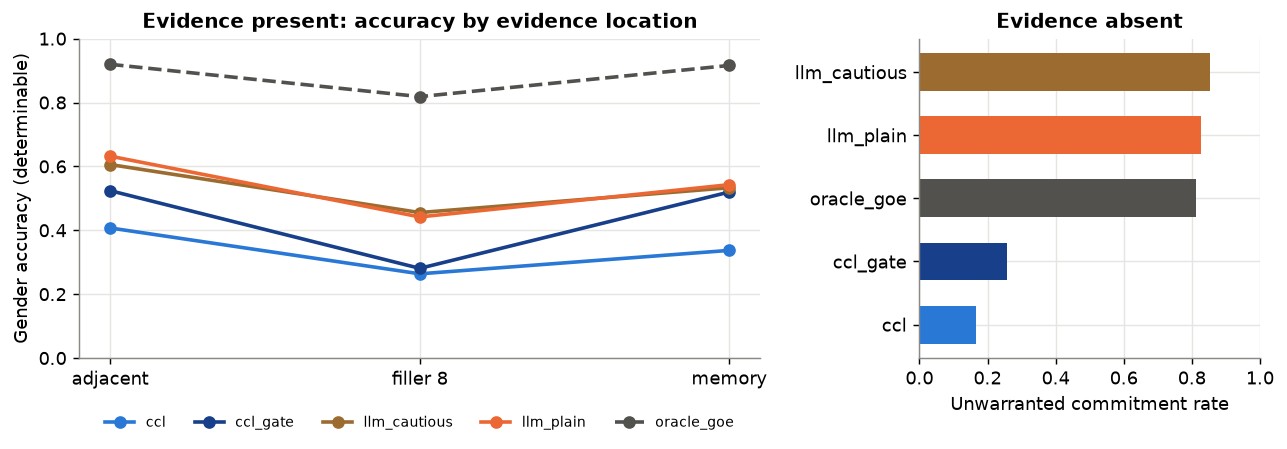

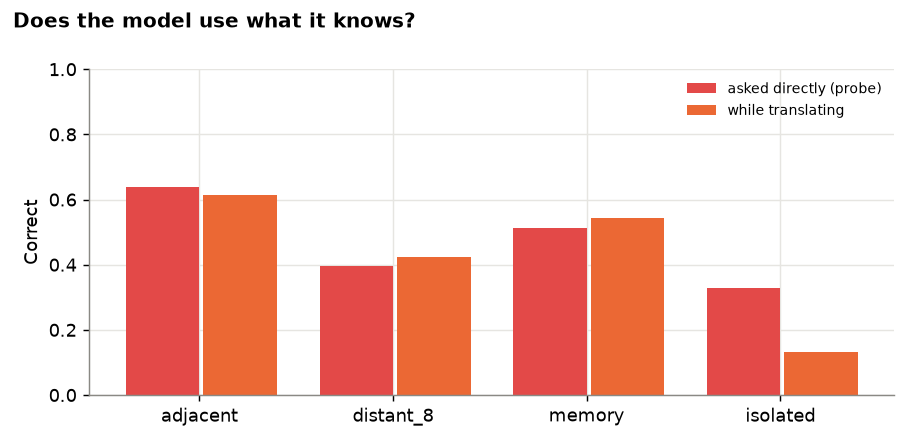

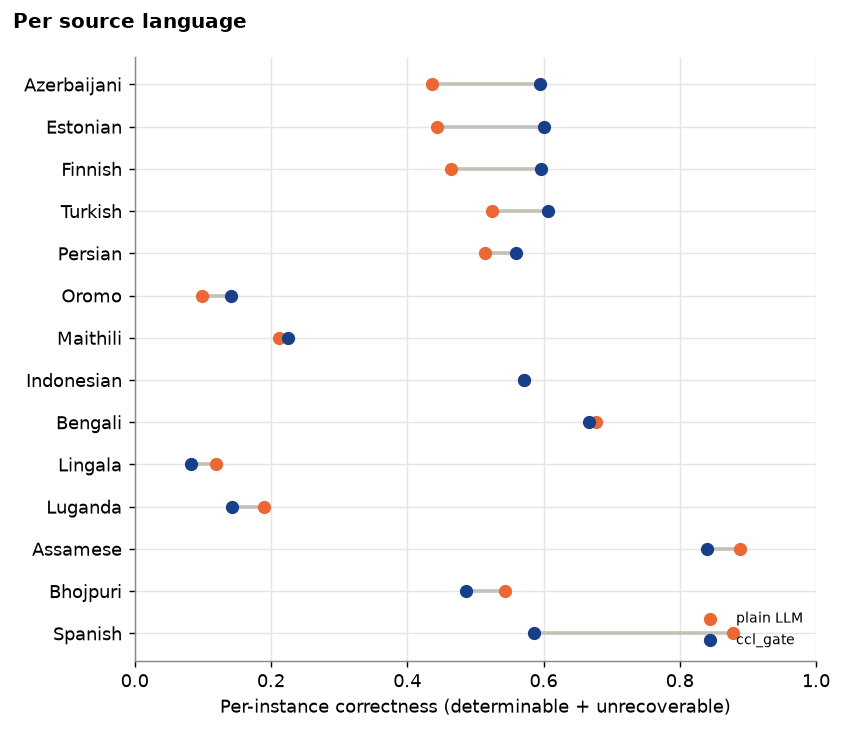

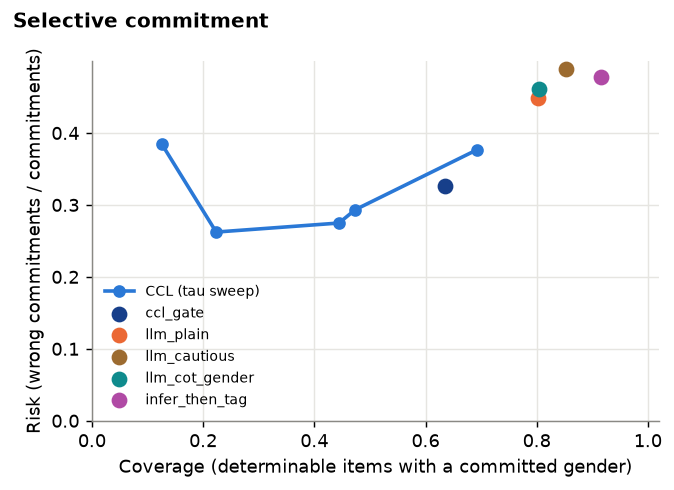

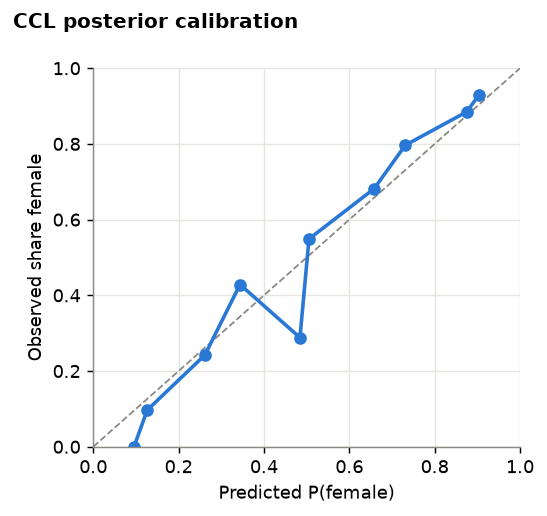

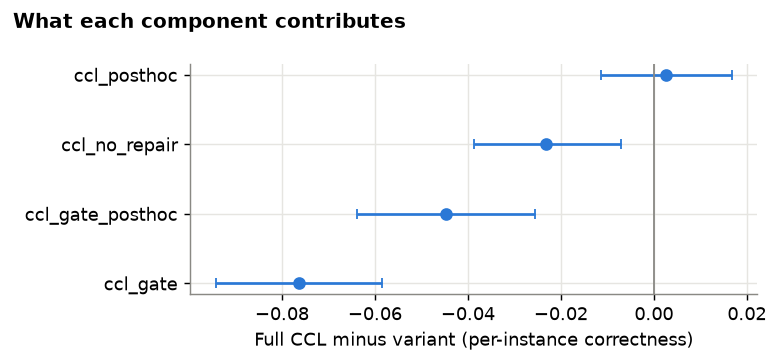

In [55]:
PALETTE = {"ccl": "#2a78d6", "llm_plain": "#eb6834", "llm_summary_mem": "#1baf7a", "llm_names_mem": "#eda100",
           "llm_selfrefine": "#e87ba4", "nllb_sent": "#008300", "llm_neutral_always": "#4a3aa7", "oracle_goe": "#52514e",
           "probe": "#e34948", "llm_cautious": "#9c6b30", "llm_cot_gender": "#0f8b8d", "infer_then_tag": "#b04aa5",
           "ccl_posthoc": "#7fb2ee", "ccl_gate": "#173f8a"}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.edgecolor": "#8a8984", "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False, "axes.axisbelow": True})

def finish(fig, name, title="", stamp=True):
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold")
    if STAMP and stamp:            # simulation figures carry their own label instead of the mock-output stamp
        fig.text(0.5, 0.5, STAMP, ha="center", va="center", fontsize=14, color="#e34948", alpha=0.25, rotation=20)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")
    plt.show()

def fig_distance():
    d = X2EN[X2EN.system.isin([s for s in ["llm_plain", "llm_cautious", "ccl", "ccl_gate", "nllb_sent", "oracle_goe"] if s in X2EN.system.unique()])]
    det = d[d.gold_kind == "determinable"]; conds = [c for c in COND_ORDER[:4] if c in det.condition.unique()]
    if not conds:
        return
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[2, 1]))
    ax = axes[0]
    for s, g in det.groupby("system"):
        y = [g[g.condition == c].correct.astype(float).mean() for c in conds]
        ax.plot(range(len(conds)), y, marker="o", lw=2, ms=6, color=PALETTE.get(s), label=s,
                ls="--" if s == "oracle_goe" else "-")
    ax.set_xticks(range(len(conds)), [c.replace("distant_", "+") .replace("+", "filler ") for c in conds])
    ax.set_ylim(0, 1); ax.set_ylabel("Gender accuracy (determinable)"); ax.set_title("Evidence present: accuracy by evidence location")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=5, fontsize=8)
    ax = axes[1]
    u = d[d.gold_kind.isin(["unrecoverable", "referent_ambiguous"])]
    if len(u):
        r = u.groupby("system").committed_gendered.mean().sort_values()
        ax.barh(r.index, r.values, color=[PALETTE.get(s, "#8a8984") for s in r.index], height=0.6)
        ax.set_xlim(0, 1); ax.set_xlabel("Unwarranted commitment rate"); ax.set_title("Evidence absent")
    finish(fig, "F1_distance_and_absence")

def fig_know_use():
    if not len(KU):
        return
    k = KU.groupby("condition")[["correct_probe", "correct_translate"]].mean().reindex([c for c in COND_ORDER if c in KU.condition.unique()])
    fig, ax = plt.subplots(figsize=(7, 3.4)); x = np.arange(len(k)); w = 0.38
    ax.bar(x - w / 2, k.correct_probe, w, color=PALETTE["probe"], label="asked directly (probe)")
    ax.bar(x + w / 2 + 0.02, k.correct_translate, w, color=PALETTE["llm_plain"], label="while translating")
    ax.set_xticks(x, k.index); ax.set_ylim(0, 1); ax.set_ylabel("Correct"); ax.legend(fontsize=8)
    finish(fig, "F2_knowing_vs_using", "Does the model use what it knows?")

def fig_languages():
    prop = "ccl_gate" if "ccl_gate" in X2EN.system.unique() else "ccl"
    d = X2EN[X2EN.gold_kind.isin(["determinable", "unrecoverable", "referent_ambiguous"]) & X2EN.system.isin(["llm_plain", prop])]
    if d.empty:
        return
    p = d.assign(c=d.correct.astype(float)).pivot_table(index="lang", columns="system", values="c", aggfunc="mean").dropna()
    if p.empty or prop not in p or "llm_plain" not in p:
        return
    p = p.rename(columns={prop: "ccl"}).assign(gap=lambda t: t.ccl - t.llm_plain).sort_values("gap")
    fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(p) + 1.2))
    for i, (lg, r) in enumerate(p.iterrows()):
        ax.plot([r.llm_plain, r.ccl], [i, i], color="#c3c2b7", lw=2, zorder=1)
    ax.scatter(p.llm_plain, range(len(p)), color=PALETTE["llm_plain"], s=40, zorder=2, label="plain LLM")
    ax.scatter(p.ccl, range(len(p)), color=PALETTE.get(prop, PALETTE["ccl"]), s=40, zorder=3, label=prop)
    ax.set_yticks(range(len(p)), [f"{LANG_NAMES.get(l, l)}" for l in p.index]); ax.set_xlim(0, 1)
    ax.set_xlabel("Per-instance correctness (determinable + unrecoverable)"); ax.legend(fontsize=8, loc="lower right")
    finish(fig, "F3_languages", "Per source language")

def fig_risk_coverage():
    if not len(RC):
        return
    fig, ax = plt.subplots(figsize=(5.2, 3.8))
    ax.plot(RC.coverage, RC.risk, marker="o", lw=2, color=PALETTE["ccl"], label="CCL (tau sweep)")
    for s in ["ccl_gate", "llm_plain", "llm_cautious", "llm_cot_gender", "infer_then_tag", "llm_neutral_always", "nllb_sent", "llm_selfrefine"]:
        g = X2EN[X2EN.system == s]
        if g.empty:
            continue
        det = g[g.gold_kind == "determinable"]; unr = g[g.gold_kind.isin(["unrecoverable", "referent_ambiguous"])]
        cd, cu = det[det.committed_gendered], unr[unr.committed_gendered]
        cov = len(cd) / max(len(det), 1); risk = ((~cd.correct.astype(bool)).sum() + len(cu)) / max(len(cd) + len(cu), 1)
        ax.scatter([cov], [risk], s=60, color=PALETTE.get(s), label=s, zorder=3)
    ax.set_xlabel("Coverage (determinable items with a committed gender)"); ax.set_ylabel("Risk (wrong commitments / commitments)")
    ax.set_xlim(0, 1.02); ax.set_ylim(0, None); ax.legend(fontsize=8)
    finish(fig, "F4_risk_coverage", "Selective commitment")

def fig_reliability():
    if not len(REL):
        return
    fig, ax = plt.subplots(figsize=(4.2, 4))
    ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1)
    ax.plot(REL.conf, REL.freq, marker="o", lw=2, color=PALETTE["ccl"])
    ax.set_xlabel("Predicted P(female)"); ax.set_ylabel("Observed share female"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    finish(fig, "F5_reliability", "CCL posterior calibration")

def fig_ablations():
    if not len(T_ABL_CMP):
        return
    d = T_ABL_CMP.sort_values("diff")
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(d) + 1.2))
    y = np.arange(len(d))
    ax.errorbar(d["diff"], y, xerr=[d["diff"] - d.ci_low, d.ci_high - d["diff"]], fmt="o", color=PALETTE["ccl"], ms=6, lw=1.5, capsize=3)
    ax.axvline(0, color="#8a8984", lw=1)
    ax.set_yticks(y, [c.replace("ccl - ", "") for c in d.comparison]); ax.set_xlabel("Full CCL minus variant (per-instance correctness)")
    finish(fig, "F6_ablations", "What each component contributes")

def fig_bwb():
    if not BWB_RECS or "BS" not in globals() or BS.empty:
        return
    order = ["same_line", "earlier_in_chunk", "earlier_chunk", "previous_chapter", "not_in_source"]
    conds = sorted(BS.condition.unique())
    fig, axes = plt.subplots(1, len(conds), figsize=(5 * len(conds), 3.6), sharey=True, squeeze=False)
    for ax, c in zip(axes[0], conds):
        g = BS[BS.condition == c]; systems = [s for s in CONFIG["run_bwb_systems"] if s in g.system.unique()]
        x = np.arange(len(order)); w = 0.8 / max(len(systems), 1)
        for i, s in enumerate(systems):
            v = [g[(g.system == s) & (g.evidence == o)].opposite.mean() for o in order]
            ax.bar(x + i * w - 0.4 + w / 2, v, w * 0.92, color=PALETTE.get(s, "#8a8984"), label=s)
        ax.set_xticks(x, [o.replace("_", " ") for o in order], rotation=20, ha="right"); ax.set_title(c.replace("_", " "))
    axes[0][0].set_ylabel("Opposite-gender pronoun rate"); axes[0][-1].legend(fontsize=8)
    finish(fig, "F7_bwb_evidence", "Chapter-level: errors by where the source marks gender")

def fig_lab():
    """Simulation ablations (Section 9b): paired difference vs v1 per scenario. Labelled as simulation."""
    if not SIM or "ablations" not in SIM:
        return
    d = SIM["ablations"][SIM["ablations"].variant != "v1_default"]
    order = d.groupby("variant").dBAL.mean().sort_values().index.tolist()
    scen = list(SCENARIOS)
    fig, ax = plt.subplots(figsize=(7.5, 0.38 * len(order) + 1.4))
    cols = {"clean": "#2a78d6", "moderate": "#1baf7a", "noisy": "#eda100", "small_model": "#e34948"}
    for j, sc in enumerate(scen):
        g = d[d.scenario == sc].set_index("variant").reindex(order)
        y = np.arange(len(order)) + (j - 1.5) * 0.18
        ax.errorbar(g.dBAL, y, xerr=[(g.dBAL - g.dBAL_lo).fillna(0).clip(lower=0), (g.dBAL_hi - g.dBAL).fillna(0).clip(lower=0)],
                    fmt="o", ms=4, lw=1, capsize=2, color=cols[sc], label=sc)
    ax.axvline(0, color="#8a8984", lw=1)
    ax.set_yticks(np.arange(len(order)), order); ax.set_xlabel("Decision-level BAL difference vs v1 (test)")
    ax.legend(fontsize=8, loc="lower right", title="noise scenario", title_fontsize=8)
    fig.text(0.99, 0.01, "SIMULATION on real item structures, assumed noise", ha="right", fontsize=7, color="#8a8984")
    finish(fig, "F8_lab_simulation_ablations", "Decision-layer components (simulation)", stamp=False)

for f in [fig_distance, fig_know_use, fig_languages, fig_risk_coverage, fig_reliability, fig_ablations, fig_bwb, fig_lab]:
    try:
        f()
    except Exception as ex:
        print(f"{f.__name__} skipped: {type(ex).__name__}: {ex}")

## 15. Reproducibility manifest
Records the configuration, dataset commits, calibration, package versions, hardware, model names and cache statistics. Archive `ccl_work/` (instances, records, scores, cache) with the paper so every number can be regenerated without re-querying models.

In [56]:
def pkg_versions():
    out = {}
    for m in ["numpy", "pandas", "scipy", "sklearn", "matplotlib", "sacrebleu", "statsmodels", "transformers", "vllm", "torch", "datasets"]:
        try:
            out[m] = __import__(m).__version__
        except Exception:
            pass
    return out
def gpu_info():
    try:
        return subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return "none"
def file_hash(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

MANIFEST.update(dict(
    finished=datetime.datetime.now(datetime.timezone.utc).isoformat(), python=sys.version, platform=platform.platform(),
    packages=pkg_versions(), gpu=gpu_info(), llm_cache=dict(LLM.stats), n_test_instances=len(TEST), n_dev_instances=len(DEV),
    counterfactual_construction=dict(CF_NOTES), build_log=dict(BUILD_LOG), mittens_name_forms=MIT_NAMES,
    dedup=dict(DEDUP), llm_stats=dict(LLM.stats),
    output_hashes={p.name: file_hash(p) for p in OUT.glob("*.jsonl")}, stamp=STAMP))
def _jsonable(o):
    if isinstance(o, dict):
        return {(k if isinstance(k, (str, int, float, bool)) or k is None else "|".join(map(str, k)) if isinstance(k, tuple) else str(k)): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_jsonable(x) for x in o]
    return o
(OUT / "manifest.json").write_text(json.dumps(_jsonable(MANIFEST), indent=1, default=str, ensure_ascii=False))
print("manifest written:", OUT / "manifest.json")
if STAMP:
    print("\n" + "!" * 70 + f"\n{STAMP}. Switch CCL_RUN_MODE to 'pilot' or 'full' with a real backend.\n" + "!" * 70)
print("stage timings (s):", json.dumps(TIMINGS, indent=0))

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


manifest written: <project>\_runtime\ccl_work\outputs\pilot\qwen3-8b\manifest.json
stage timings (s): {
"build_base": 1.19,
"validity_checks": 1.19,
"subsample": 0.03,
"counterfactuals": 0.06,
"ccl_extract": 1.24,
"ccl_resolve_lp": 0.75,
"calibration_dev_states": 1.31,
"calibration_dev_plain": 0.47,
"llm_plain": 0.75,
"llm_cautious": 0.77,
"llm_cot_gender": 0.51,
"infer_then_tag": 1.18,
"ccl_translate": 2.27,
"ccl_repair": 0.46,
"ccl_all_variants": 6.56,
"lab_real_states": 4.61
}


## 16. Final configuration, interpretation, limitations and reproduction

**Final configuration (the `ccl_gate` system).** Qwen3-8B Q4_K_M; v3 switches `hygiene, prior, pseudo, slots, tauguard, prompts, prompts2, monotone, gate`; evidence weights = expert defaults × fitted temperature (a = 0.415 on dev); τ = 0.70, τ_gate = 0.60 (both dev-selected); log-prob resolver; singular-*they* deferral; gate instructions added to the plain prompt with the earlier text; monotone targeted repair. Values used are written to `Results/pilot/config_used.json`.

**What the results show** (held-out test; Sections 12.1–12.1c):
1. *Abstaining.* Where gender cannot be known (isolated targets) or the referent is ambiguous, the prompt baselines still output a gendered pronoun in 83–92 % of cases, even when told to be cautious; CCL-Gate does so in 26 % (CCL 17 %). This is the largest and most robust effect (+71 to +82 points on isolated items, all p_holm < 0.001).
2. *Knowing and using.* On determinable items CCL-Gate commits the wrong gender in 15.6 % of cases versus 23.7–30.5 % for the prompt baselines, and its gendered outputs are more often right (precision 0.75 vs 0.65–0.70). It also narrows the male-default gap (test accuracy M − F: +0.08 vs +0.22 for plain and +0.44 for cautious, table T6). The price is more neutral renderings (36 % vs 8–20 %), so exact-gender accuracy on determinable items is 0.47 versus 0.54–0.60.
3. *Overall.* CCL-Gate beats each prompt baseline on per-instance correctness over all analysed conditions (+5.6 vs plain, +6.8 vs cautious, +6.4 vs CoT; +3.5 vs infer-then-tag, CI −0.2 to +7.4) and in the adjacent condition (+5.1 to +8.4); it ties in the memory condition (−1.8 to −6.8, only infer-then-tag's CI excludes zero before correction) and loses with 8 filler sentences between evidence and target (−16 to −28).
4. *Ablations.* The gate beats full ledger conditioning by 7.6 points (paired, CI 5.9–9.4): the ledger is better at deciding *whether* gender is observable than at choosing *which* gender the translator should use. Instructions beat post-hoc repair: applying the gate by repair instead of instructions lowers BAL from 0.608 to 0.533 because repair leaves 51 % of isolated items gendered. Repair in full CCL trades accuracy for abstention: without it, determinable accuracy rises (0.44 vs 0.35) but gendered output on unknowable items more than doubles (0.38 vs 0.17); BAL 0.53 vs 0.59. At decision level, removing deferral costs 0.34 BAL and removing the name prior 0.02.

**Limitations.** One 4-bit 8B model; one run (no seed variation; greedy decoding); distant_32 not analysed (output budget); distant_8 is the method's weak condition (extraction over long filler passages misses evidence; parse failures 4 % for CCL-Gate vs 1–2 % for plain and cautious); BWB chapter-level data and verified Urdu items were not available; no human evaluation of fluency of neutral renderings yet (sheet exported in Section 13); CCL costs ~7× the tokens of the plain baseline (1,900 vs 270 tokens per instance); the pronoun scorer treats "his/her" as committing for every system; the server KV cache changed from f16 to q8_0 during the run.

**Reproduce.**
```
# cache-only re-run of every number (minutes; no GPU needed)
powershell -ExecutionPolicy Bypass -File "_runtime\scripts\run_final_notebook.ps1"
# regenerate model calls: start the server (Section 1.1), move the cache file away, run the same script (more than a day)
```
Environment: `_runtime/venv` (Python 3.12.6, packages in `requirements_lock.txt`), llama.cpp b11642, Qwen3-8B-Q4_K_M.gguf. Data are cloned at pinned commits (Section 2); FLORES+ on Hugging Face is gated, so the public FLORES-200 tarball is used.


## 17. Export to the `Results` folder
Copies the tables, figures, manifest and scored records of this run to `<project>/Results/<run mode>/` (override with `CCL_RESULTS_DIR`). Re-running the notebook overwrites them with identical content, because every model call comes from the cache.

In [57]:
RESULTS = Path(os.environ.get("CCL_RESULTS_DIR") or (WORK.parent.parent / "Results")).resolve() / RUN_MODE
for sub in ["tables", "figures", "records"]:
    (RESULTS / sub).mkdir(parents=True, exist_ok=True)
n_files = 0
for src_dir, dst in [(TAB, RESULTS / "tables"), (FIG, RESULTS / "figures")]:
    for p in src_dir.rglob("*"):
        if p.is_file():
            q = dst / p.relative_to(src_dir); q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n_files += 1
for name in ["scores_items.csv", "scores_tau_sweep.csv", "manifest.json", "ccl_weights.json", "ccl_tau.json", "ccl_tau_gate.json", "records_items.jsonl"]:
    p = OUT / name
    if p.exists():
        shutil.copy2(p, RESULTS / "records" / name); n_files += 1
(RESULTS / "config_used.json").write_text(json.dumps(_jsonable(dict(run_mode=RUN_MODE, config=CONFIG, v3=sorted(V3),
    weights=current_weights(), tau=current_tau(), tau_gate=current_tau_gate(), analysis_excluded=EXCL)), indent=1, default=str))
print(f"exported {n_files} files to {RESULTS}")


exported 86 files to <project>\Results\pilot